In [3]:
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from statannotations.Annotator import Annotator

from config import RESSERENO_ROOT
from bfmn_building import pipeline_single_participant, pipeline_multiple_participants
from questionnaires_analysis import factor_grouping, big_5, item_reversion_sum
from tfmn_building import tfmn_buiding

In [2]:
pd.set_option('display.max_columns', None)

In [4]:
out_folder = RESSERENO_ROOT / "out"

# BFMN building

In [4]:
physics_associations = pd.read_csv(f'{out_folder}/formatting/physics_2025/associations_valence_fisica.csv')

stem_group_associations = physics_associations[physics_associations['participant_id'].str.startswith('fisica_stem')]

## Single BFMN

In [5]:
keywords = ['ansia', 'matematica', 'fisica', 'universita', 'esame', 'stress', 'benessere', 'fallimento', 'futuro', 'compagni']

stem_group_associations_id = stem_group_associations.copy()

stem_group_associations_id['base_id'] = (stem_group_associations_id['participant_id'].str.rsplit('_', n=1).str[0])

ids_with_multiple_sessions = (stem_group_associations_id.loc[stem_group_associations_id['participant_id'].str.endswith(('_2', '_3')), 'base_id'].unique())

ids_sessions = stem_group_associations_id['participant_id'][stem_group_associations_id['base_id'].isin(ids_with_multiple_sessions)].unique()

In [6]:
stem_group_associations['cue_word'].unique()

array(['scienza', 'statistica', 'ipotesi', 'ansia', 'benessere',
       'equazione', 'fisica', 'innovazione', 'panico', 'meditazione',
       'matematica', 'analisi', 'scoperta', 'scienziata', 'docente',
       'programmazione', 'laboratorio', 'conoscenza', 'fallimento',
       'voto', 'numeri', 'logica', 'ricerca', 'imbarazzo', 'compagni',
       'problema', 'informatica', 'sfida', 'paura', 'genitori', 'dati',
       'esperimento', 'stress', 'intelligenza_artificiale', 'regole',
       'scienziato', 'scuola', 'creatività', 'arte', 'esame', 'futuro',
       'vita'], dtype=object)

Processing participant: fisica_stem_001_1


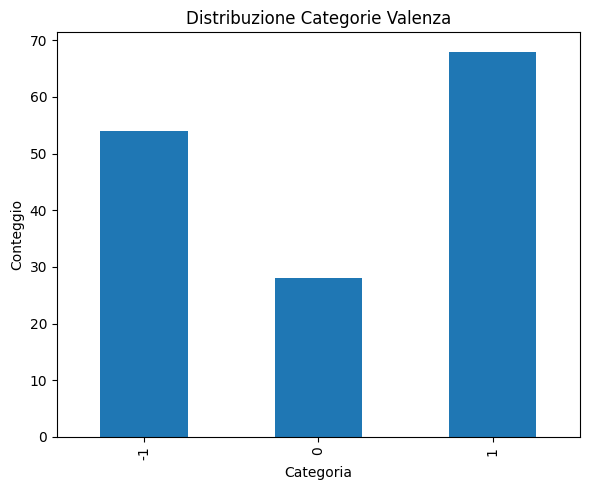

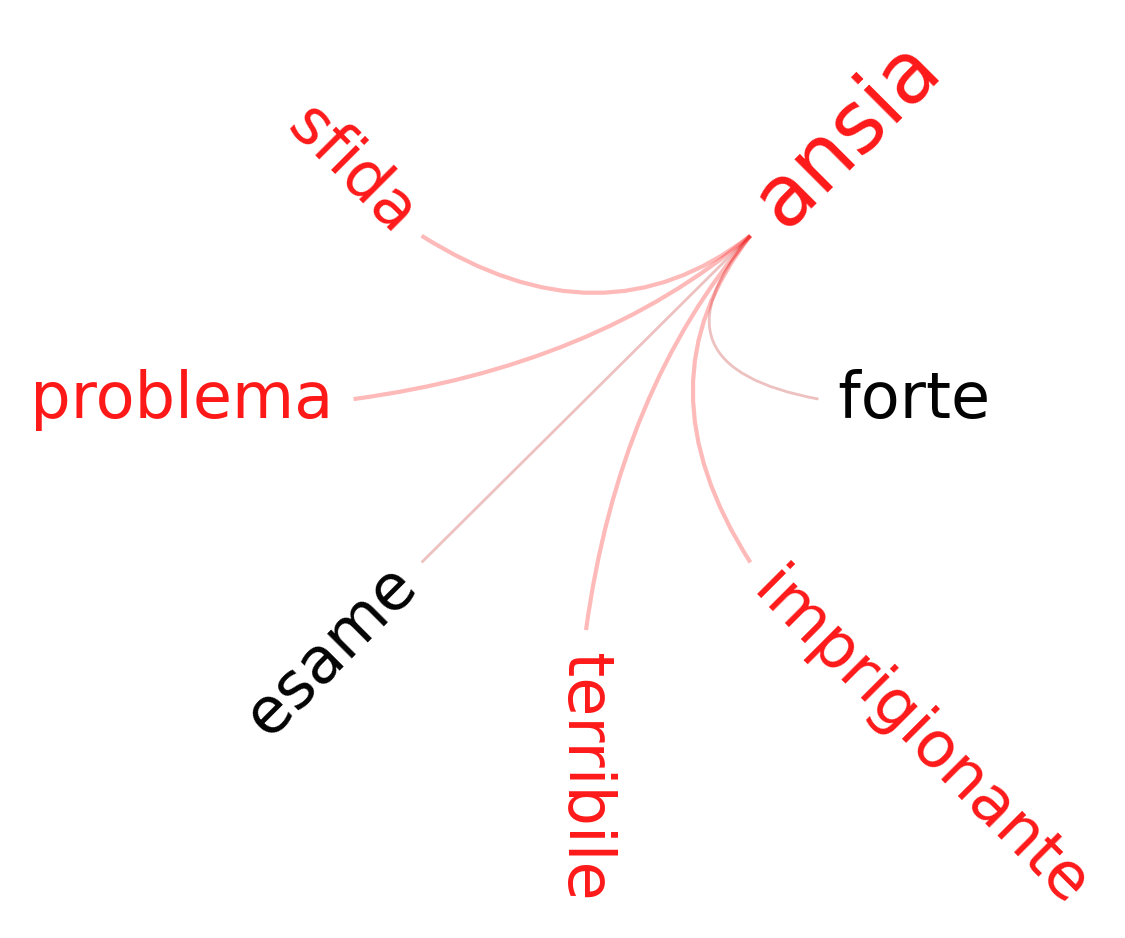

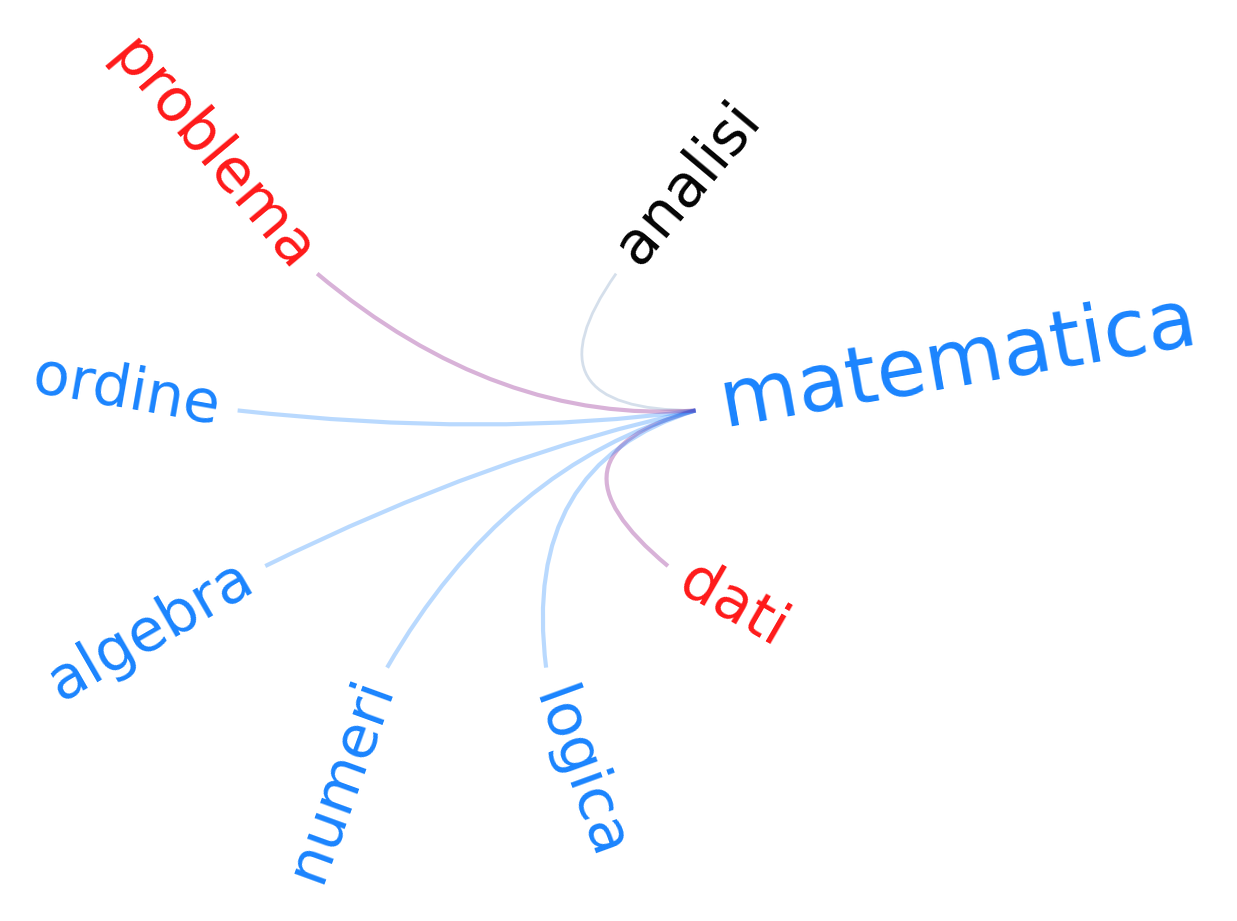

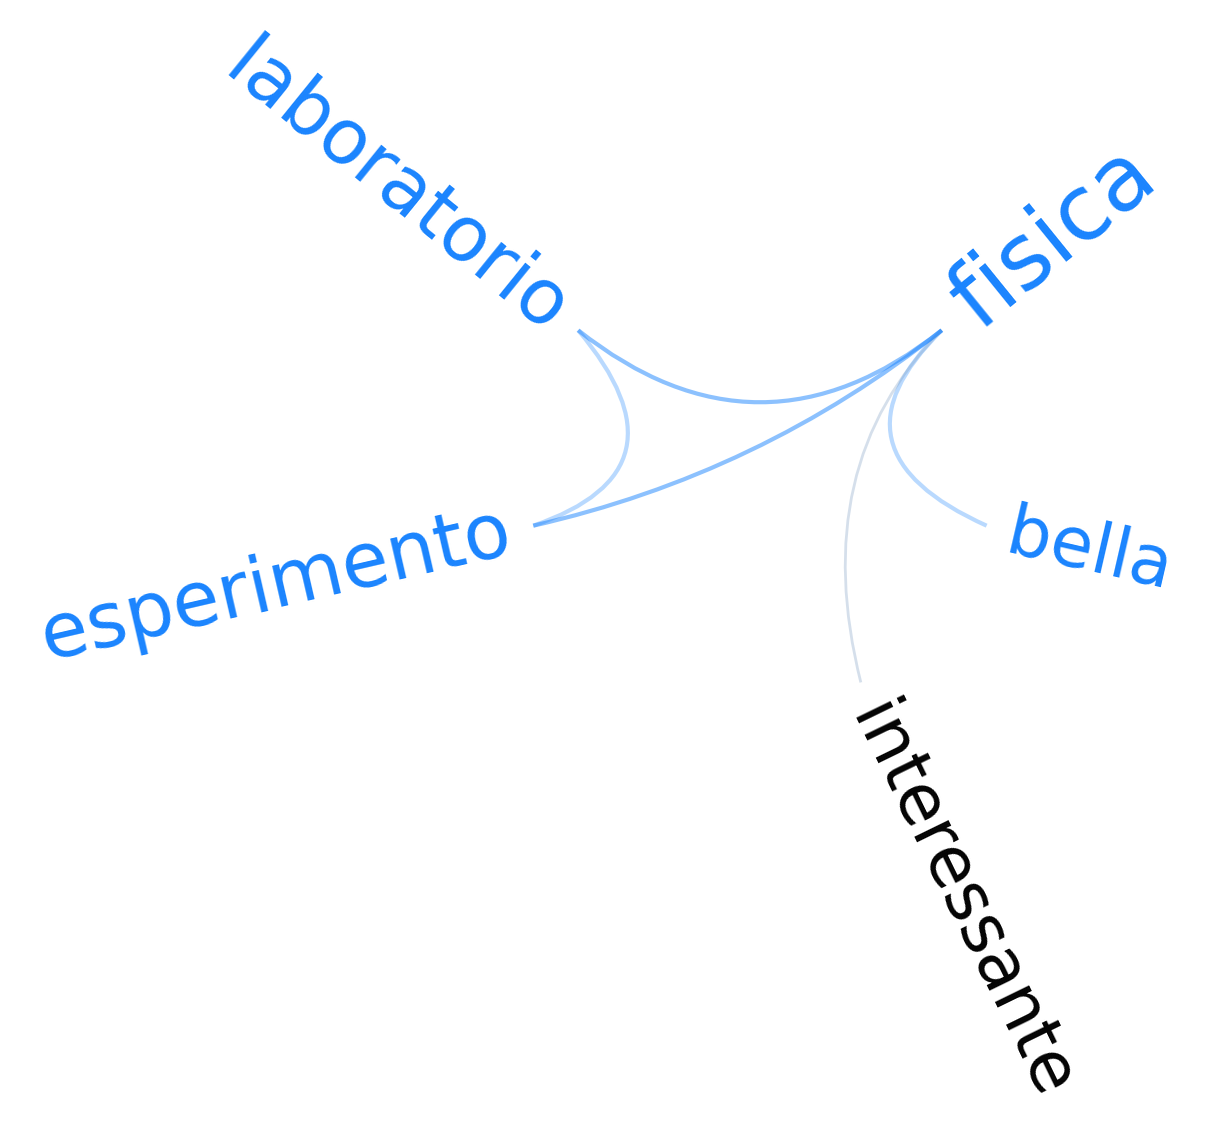

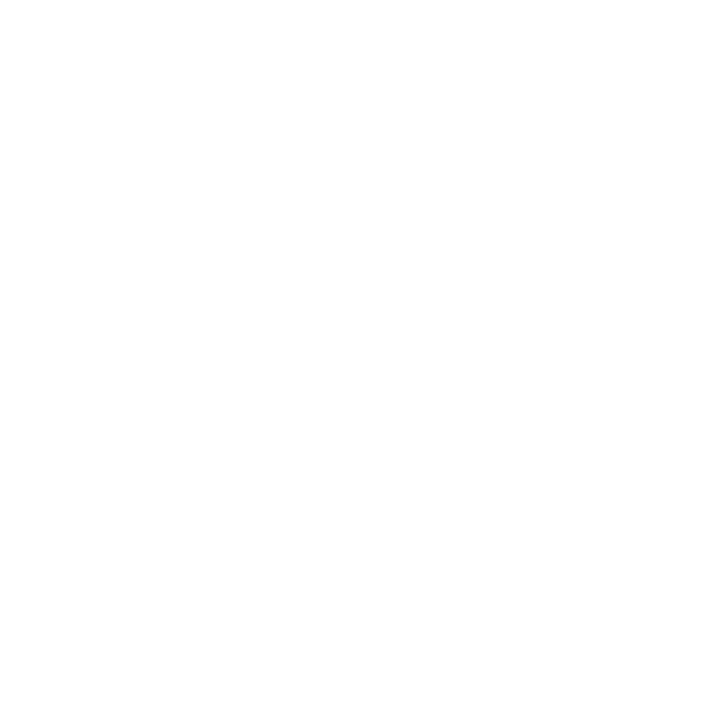

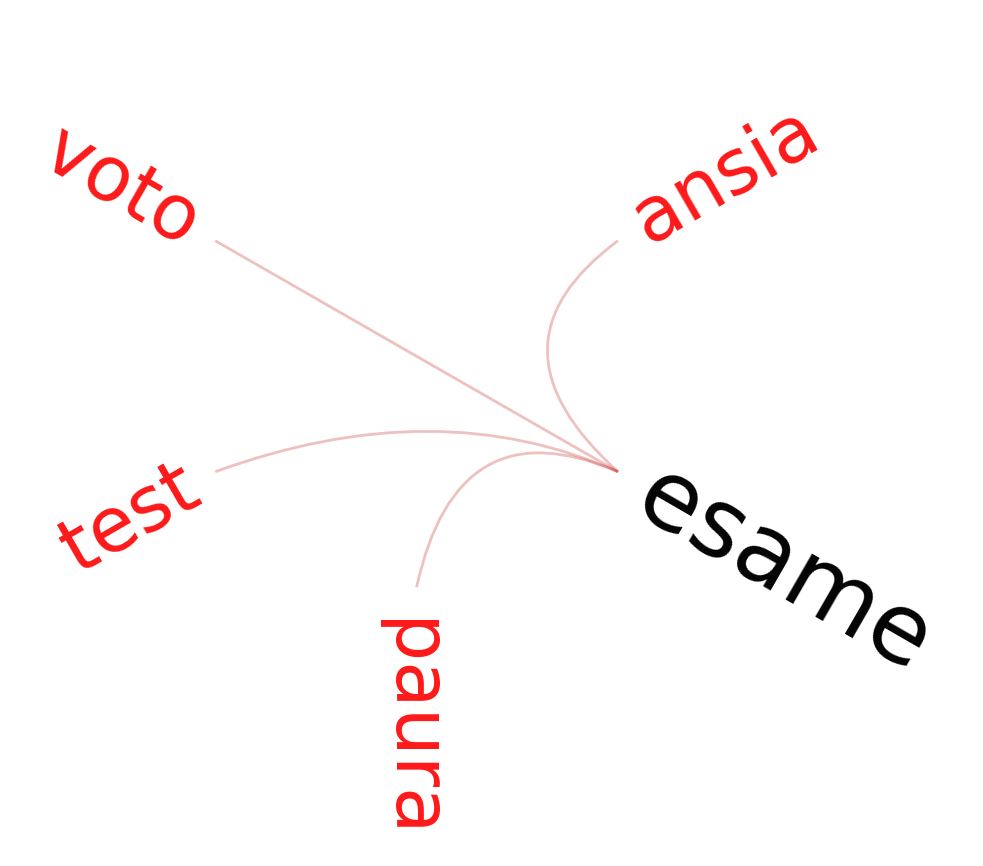

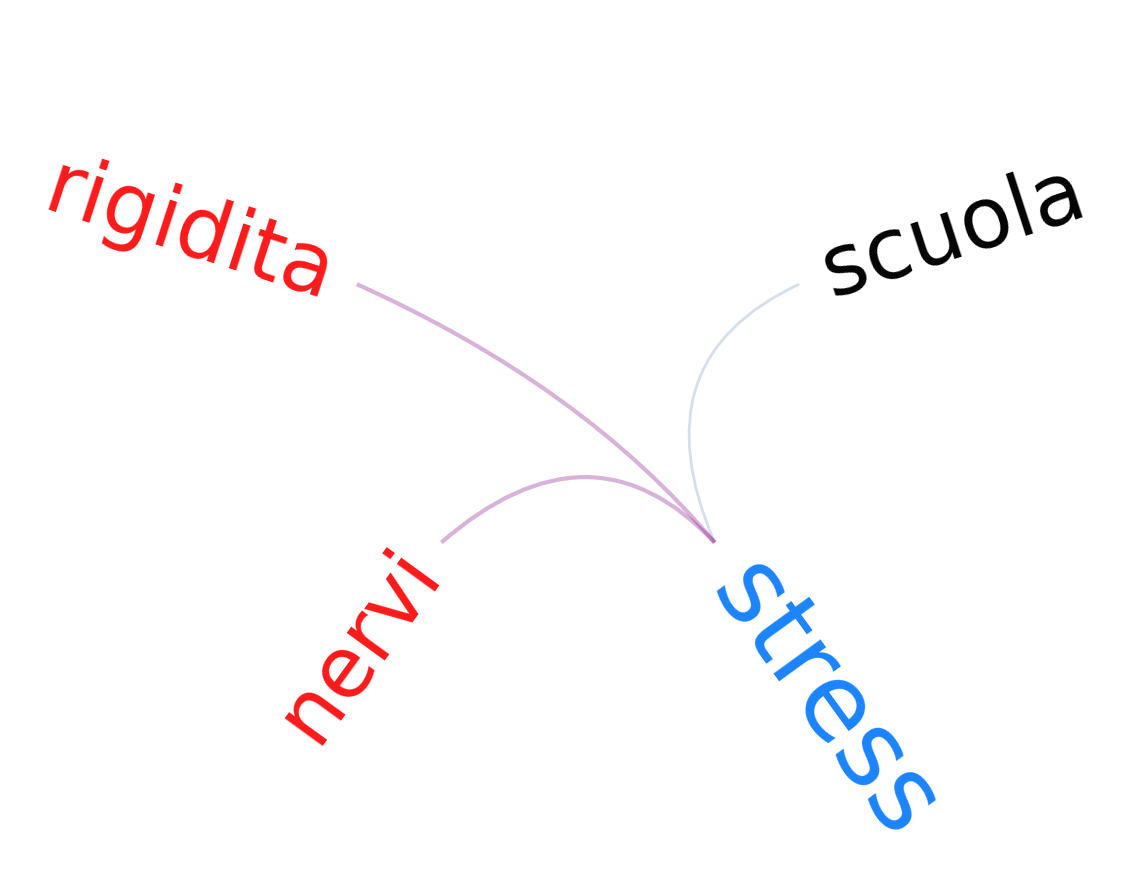

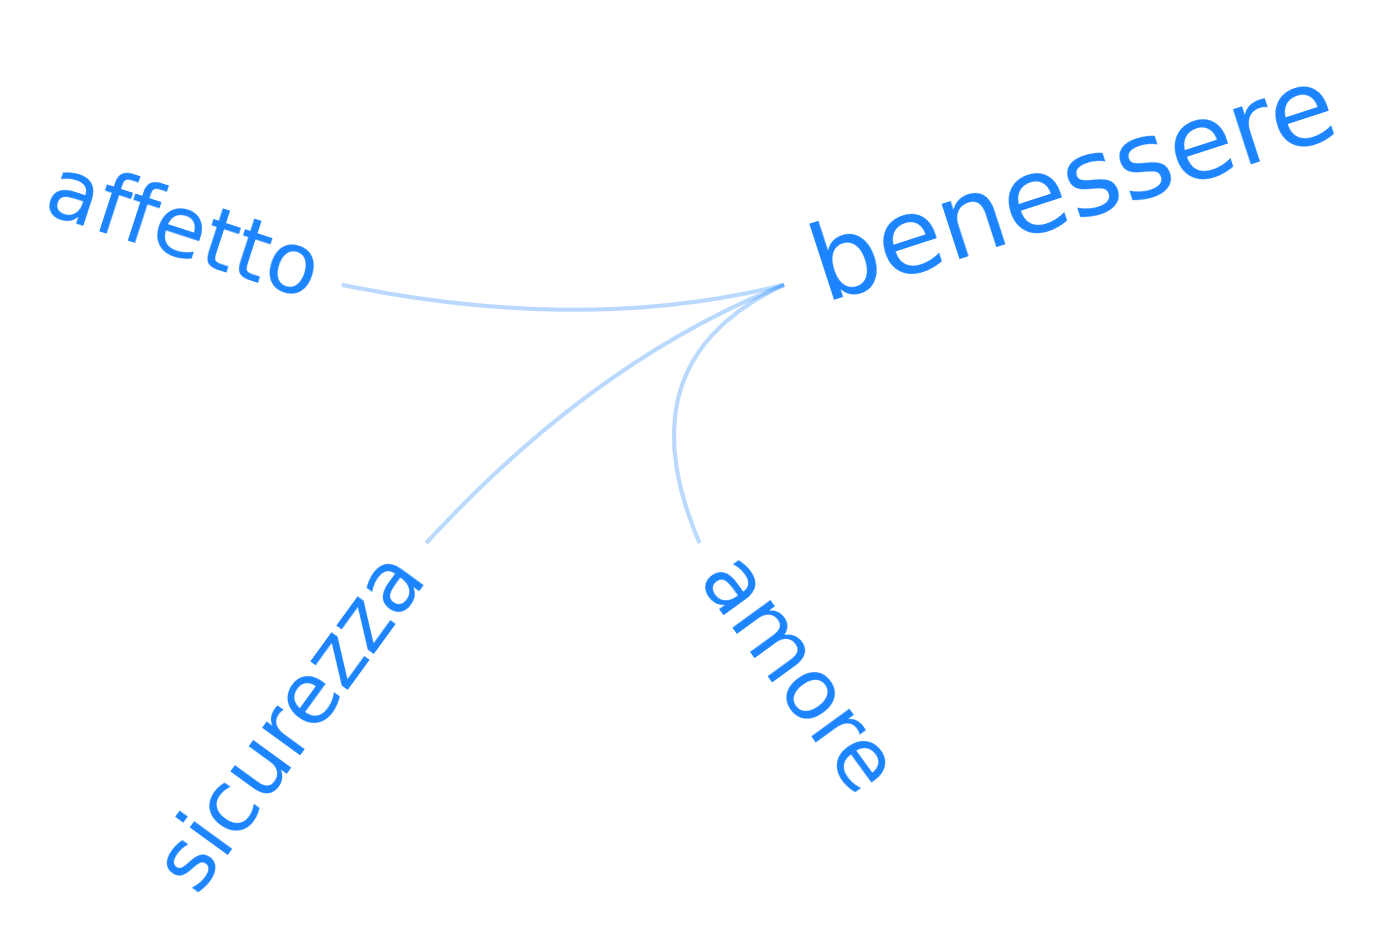

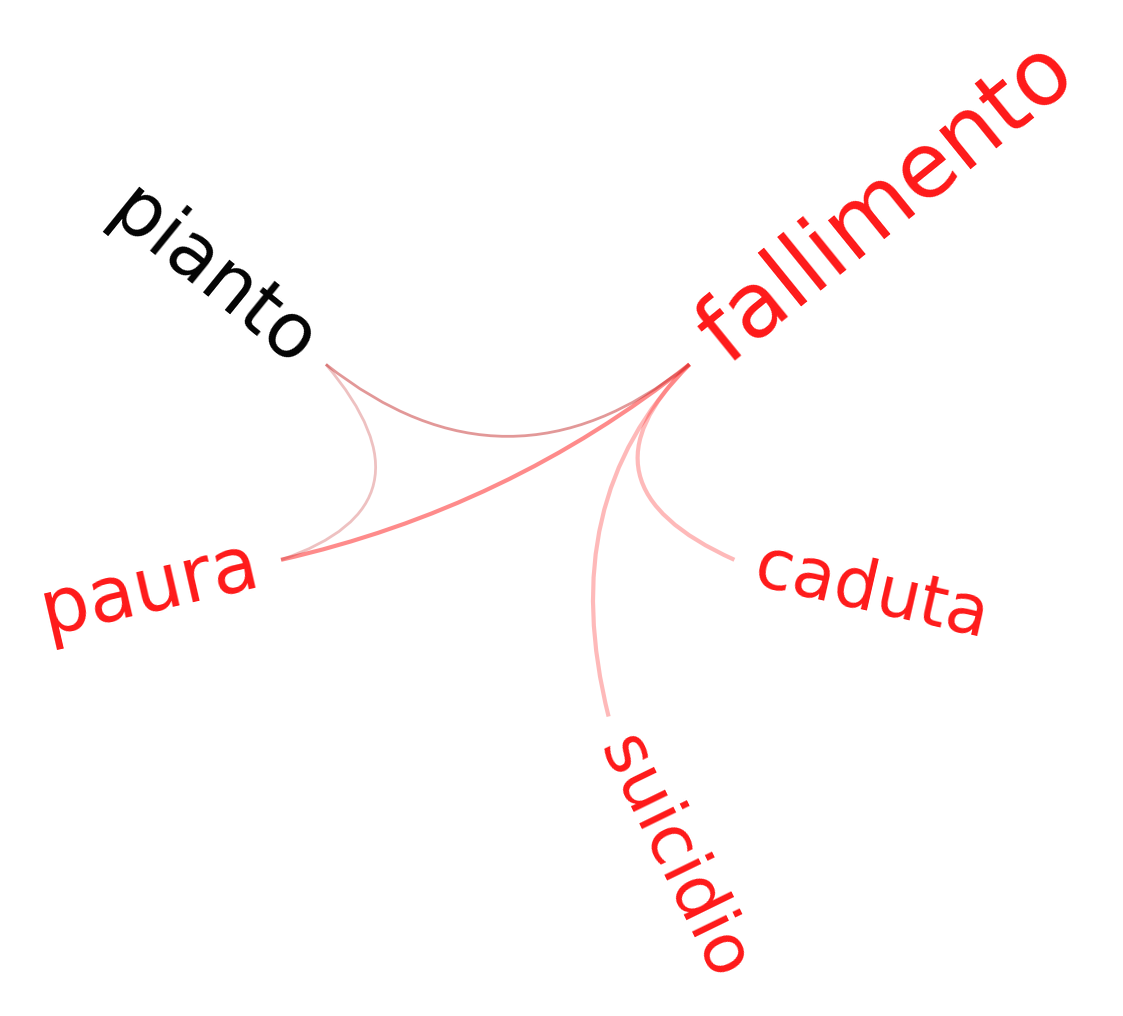

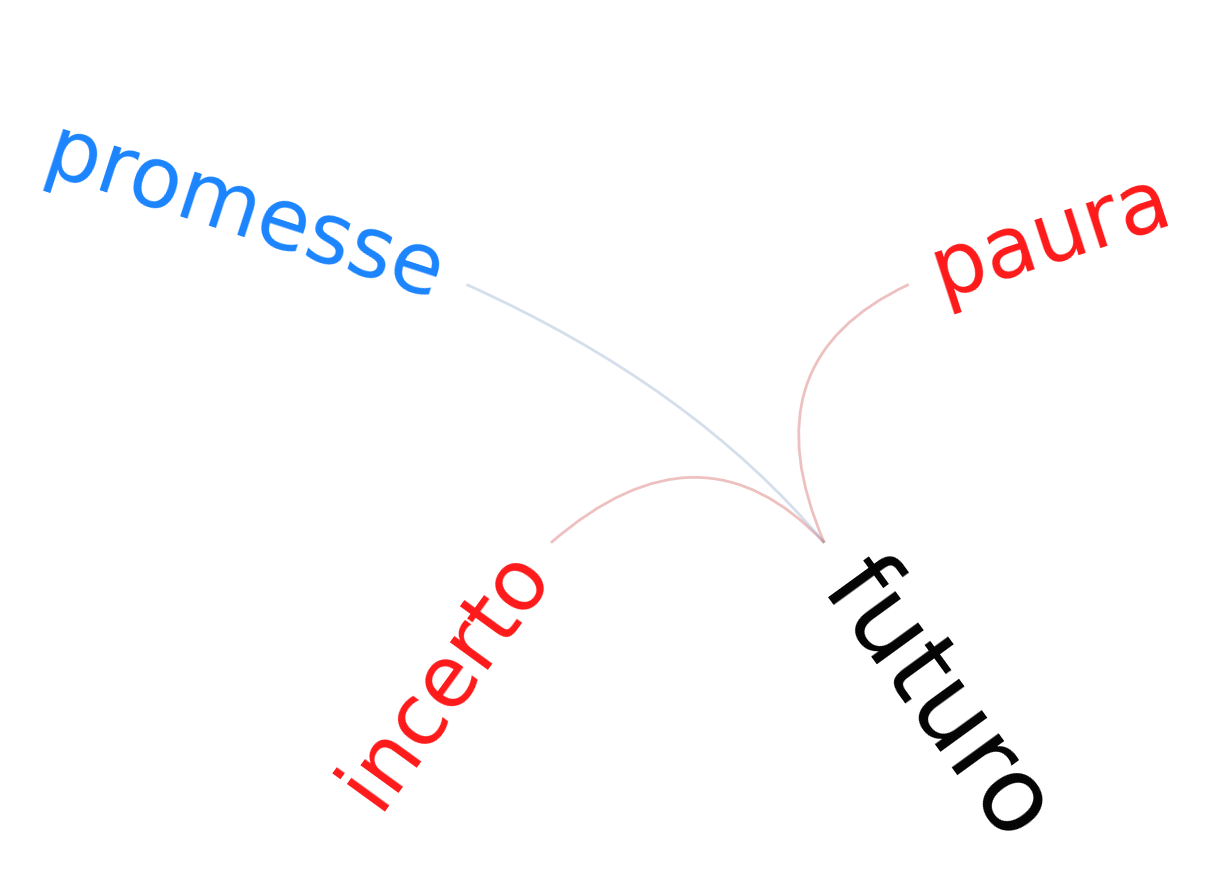

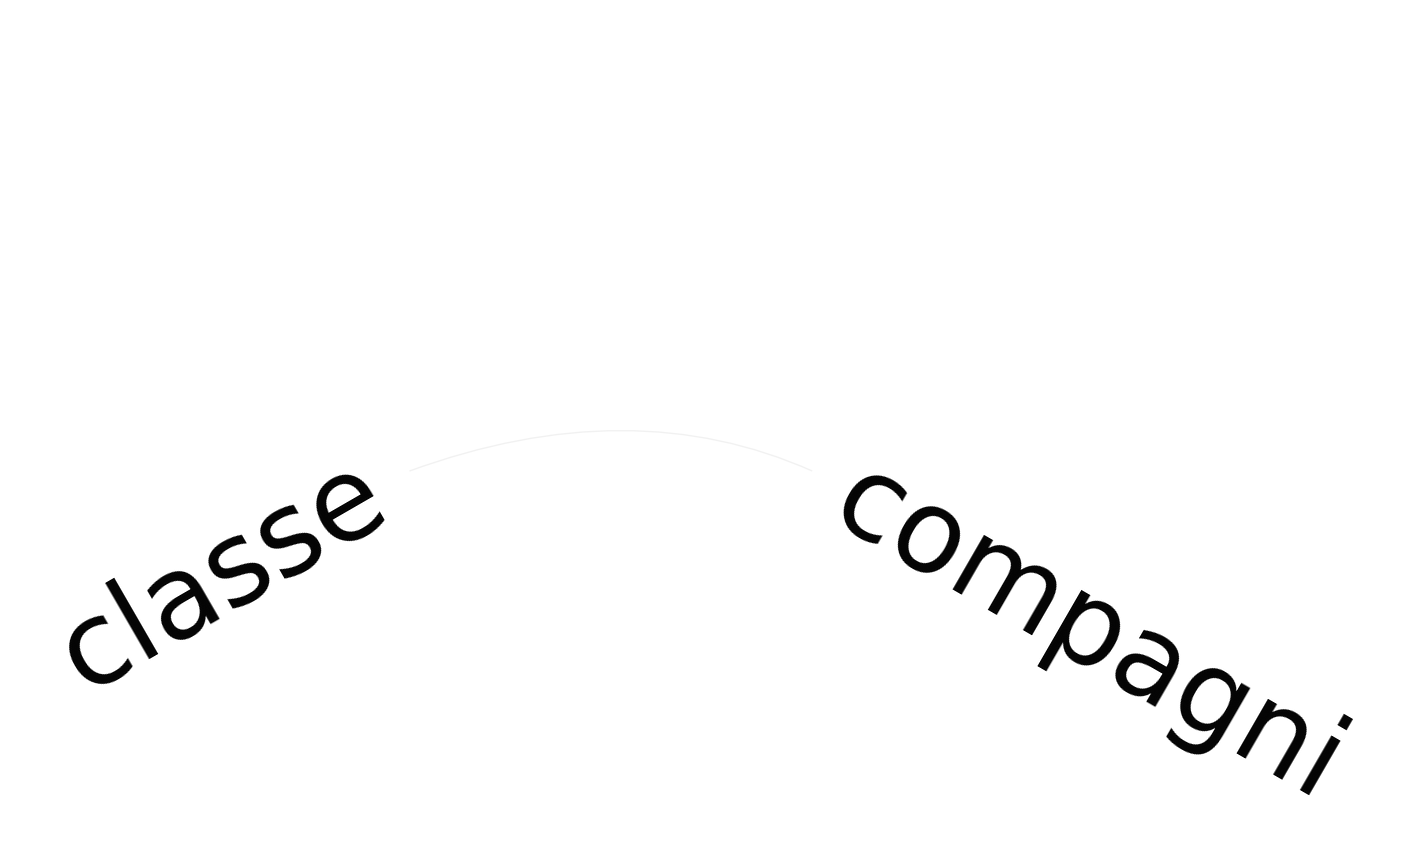

Processing participant: fisica_stem_002_1


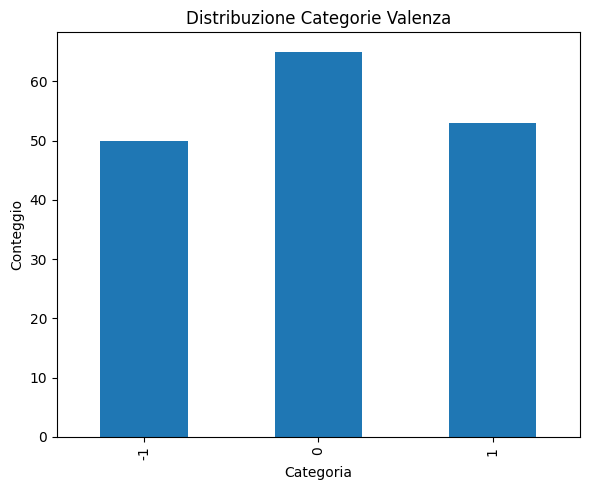

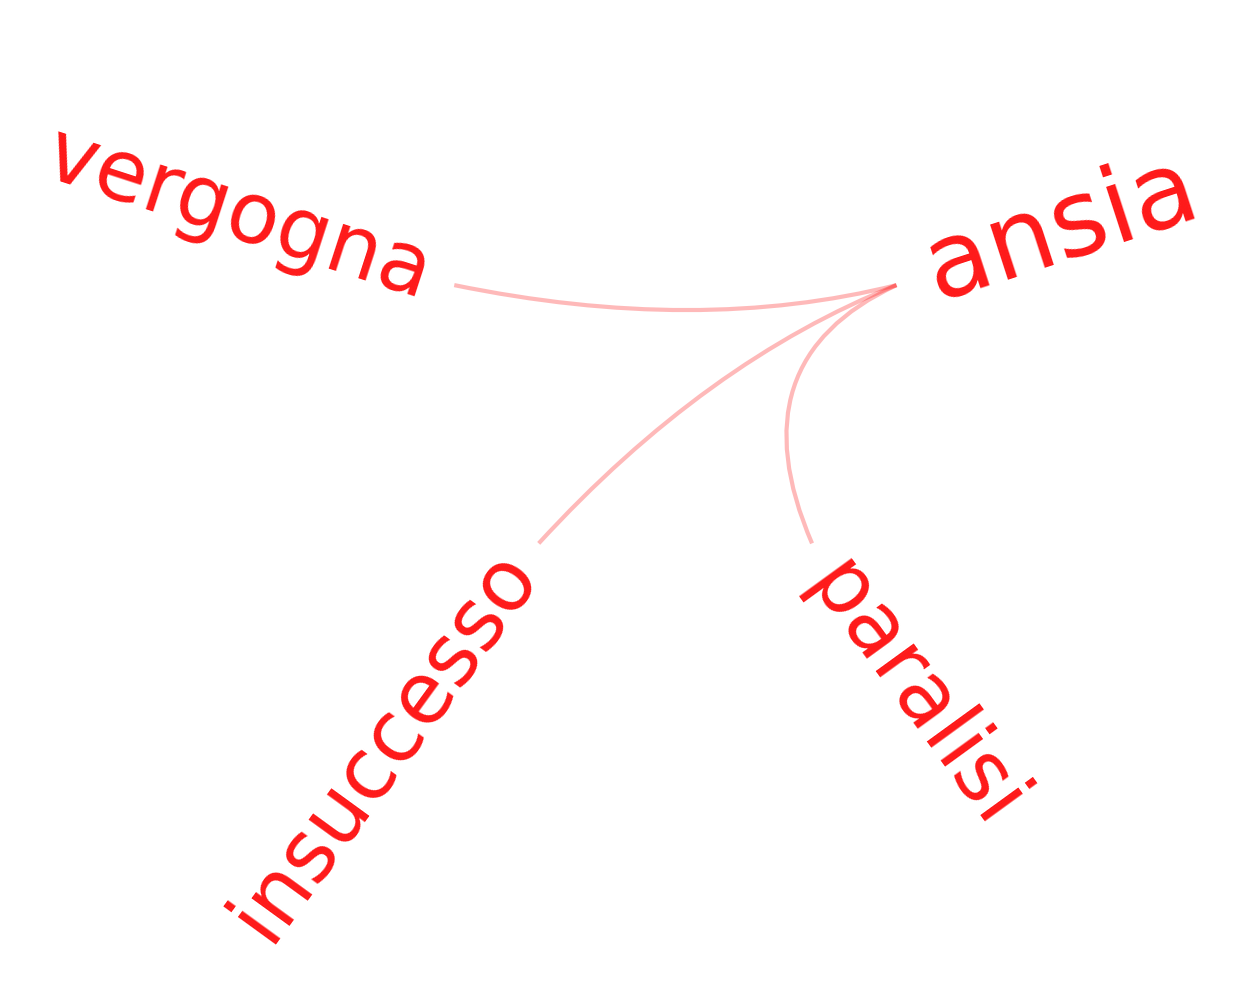

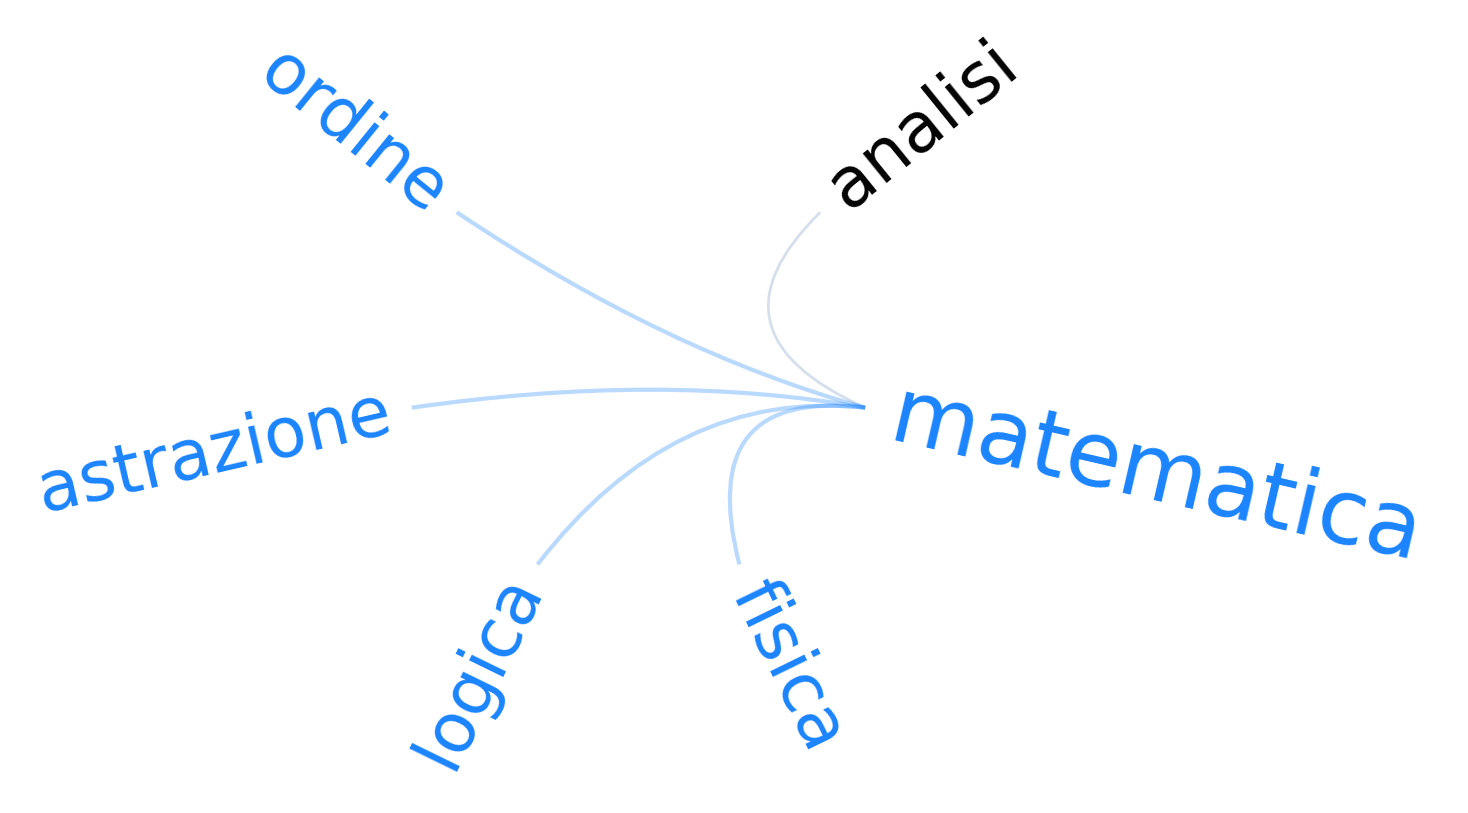

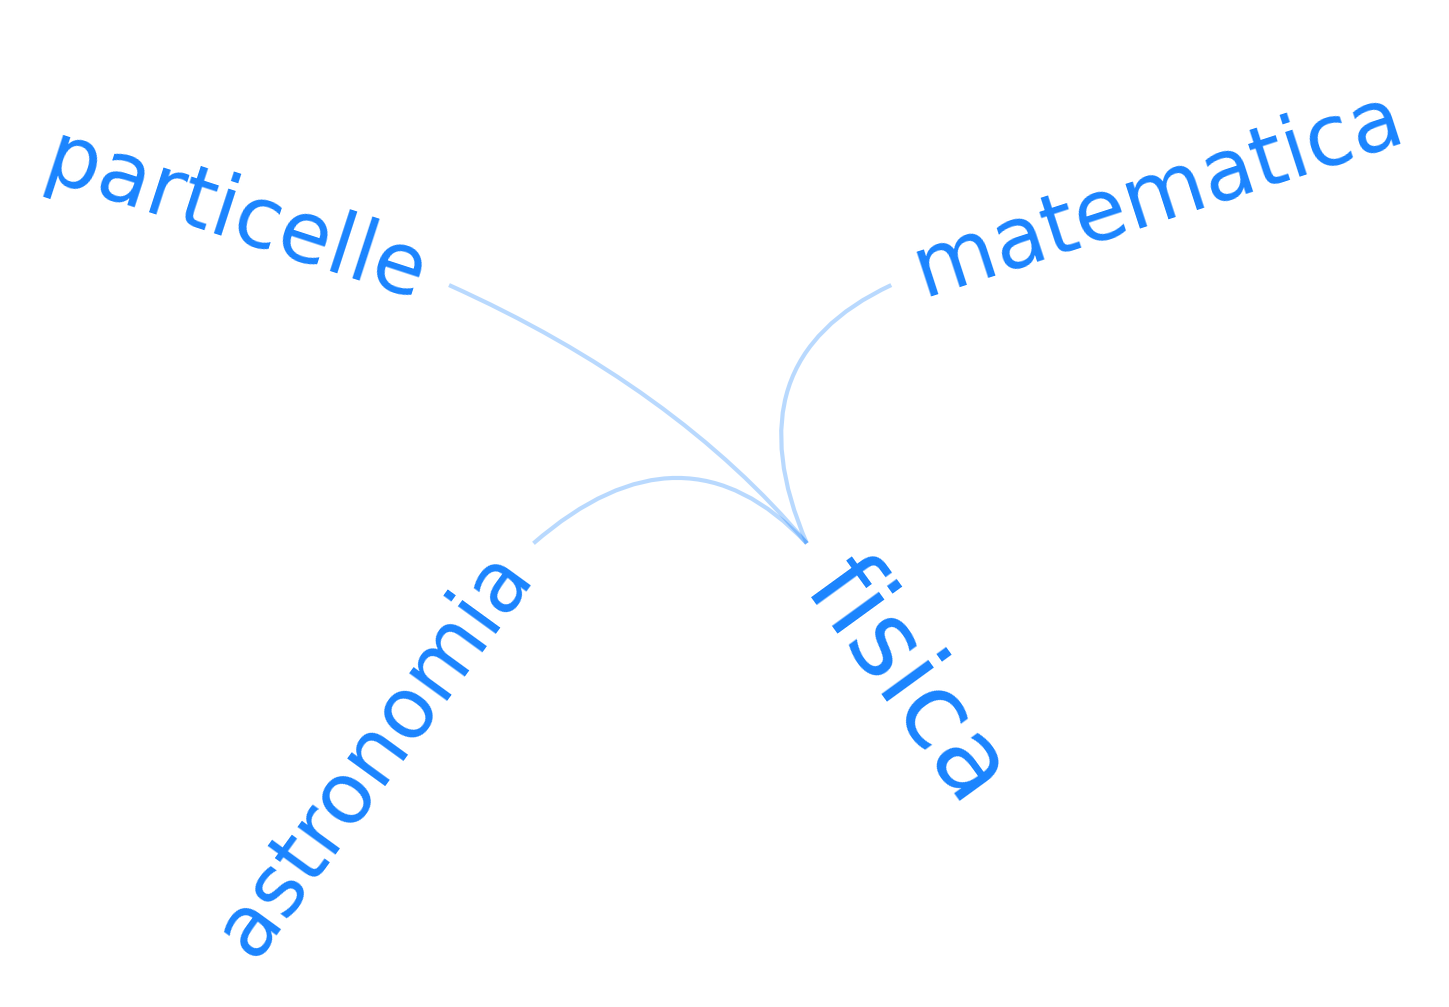

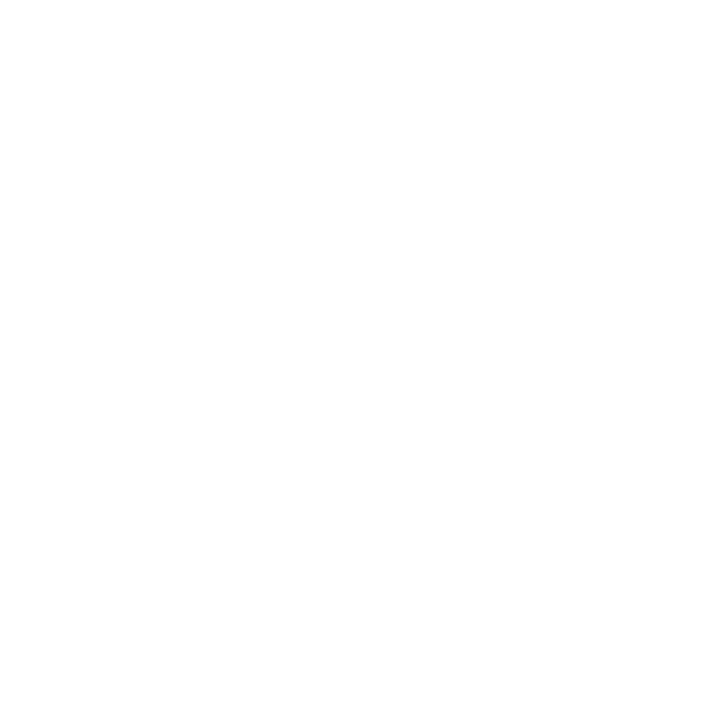

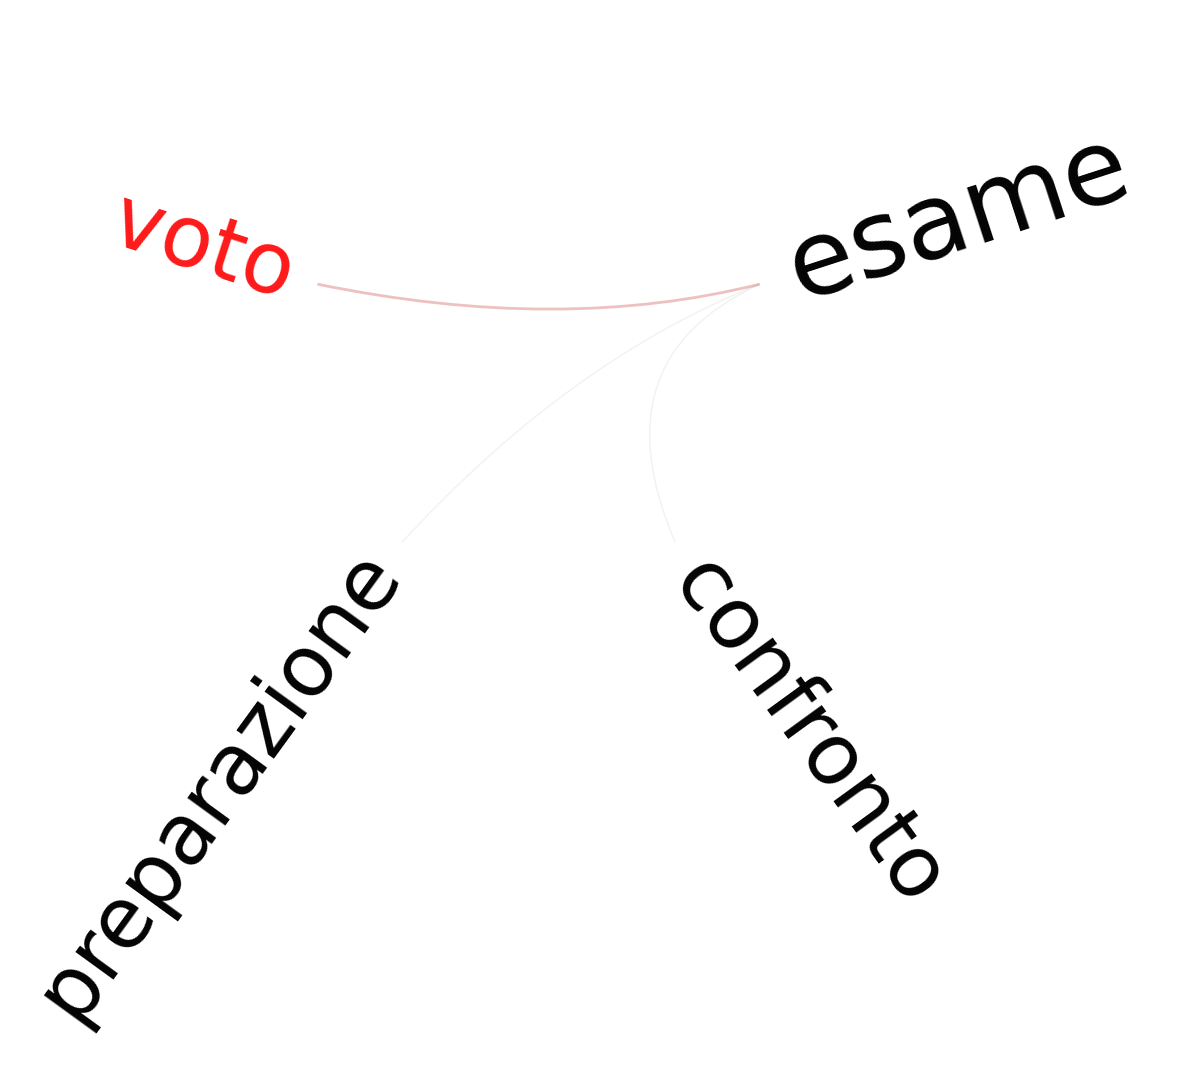

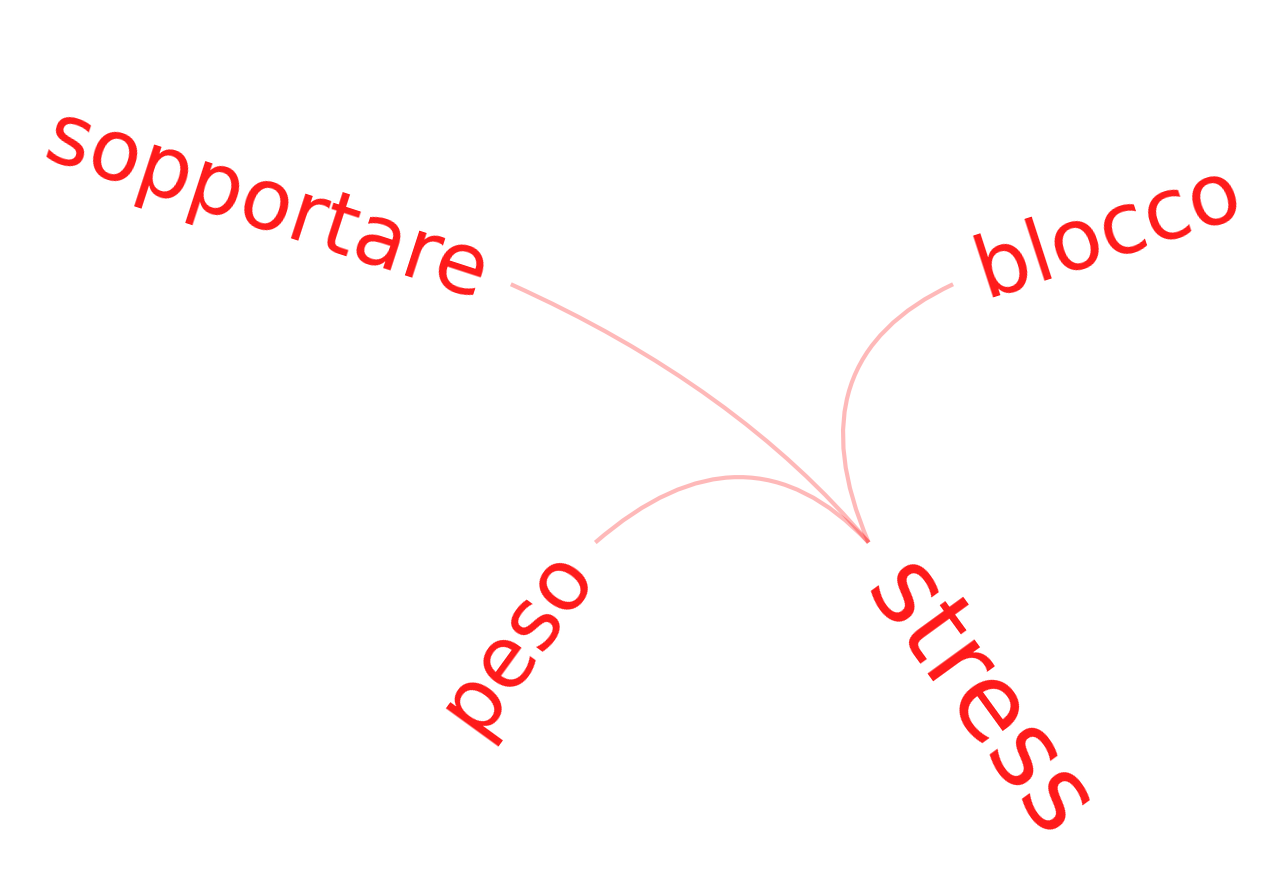

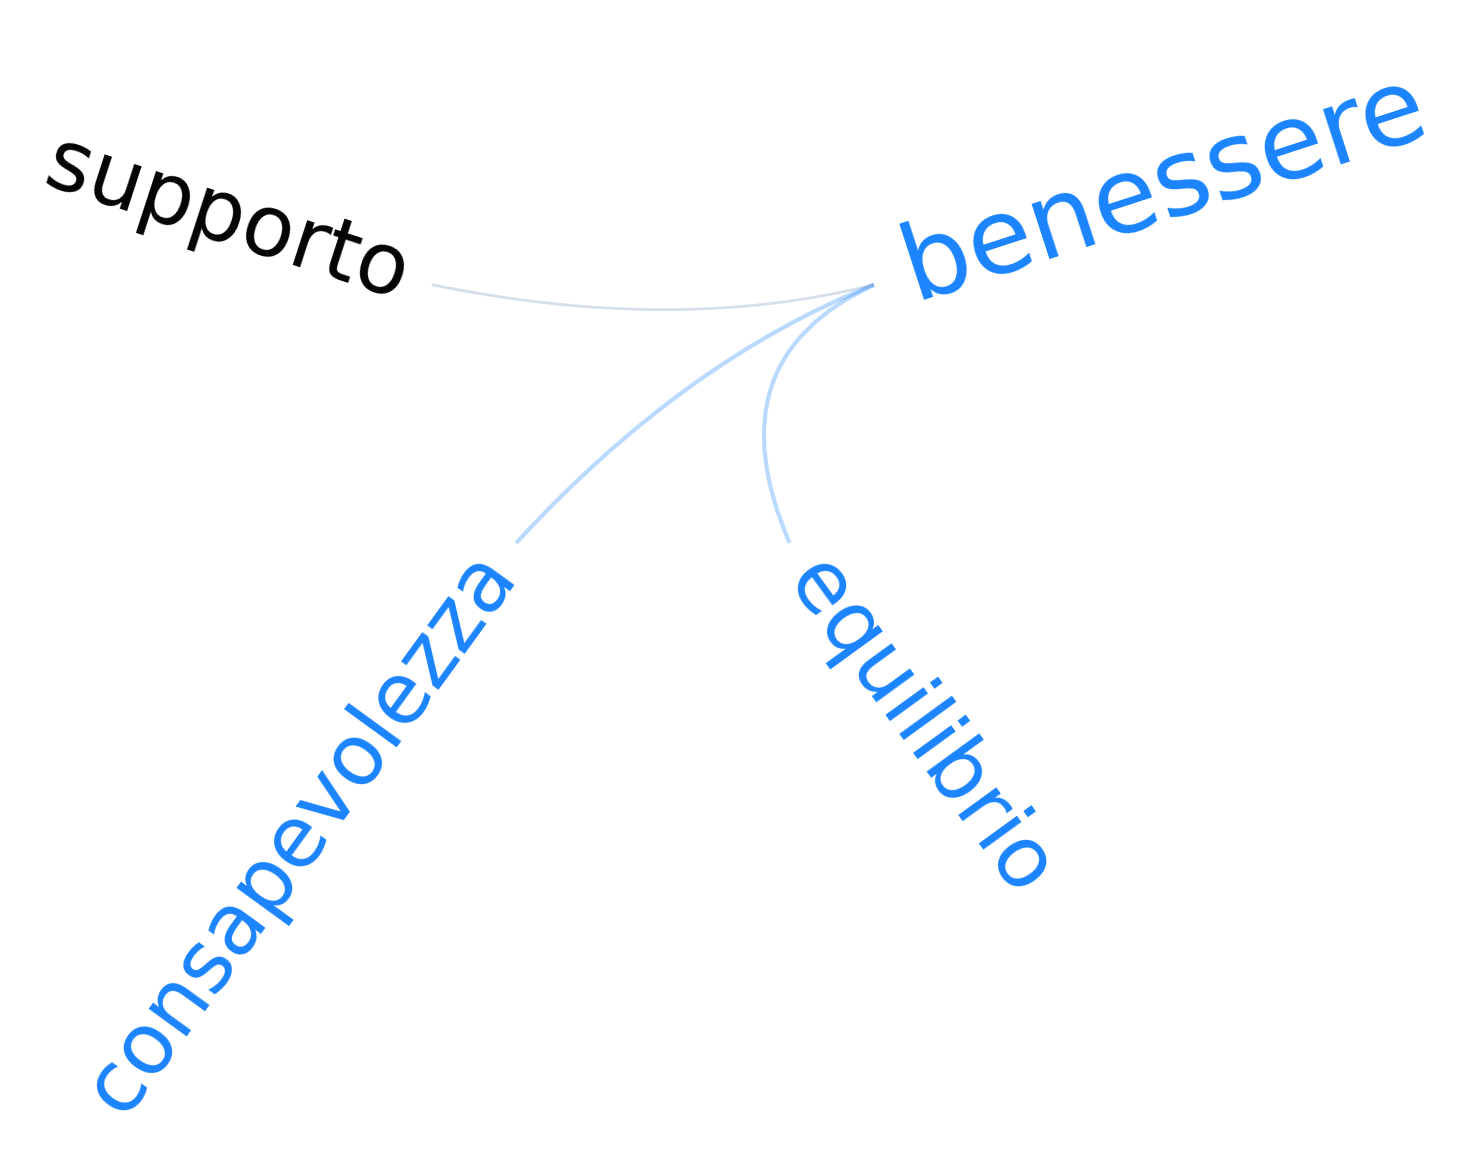

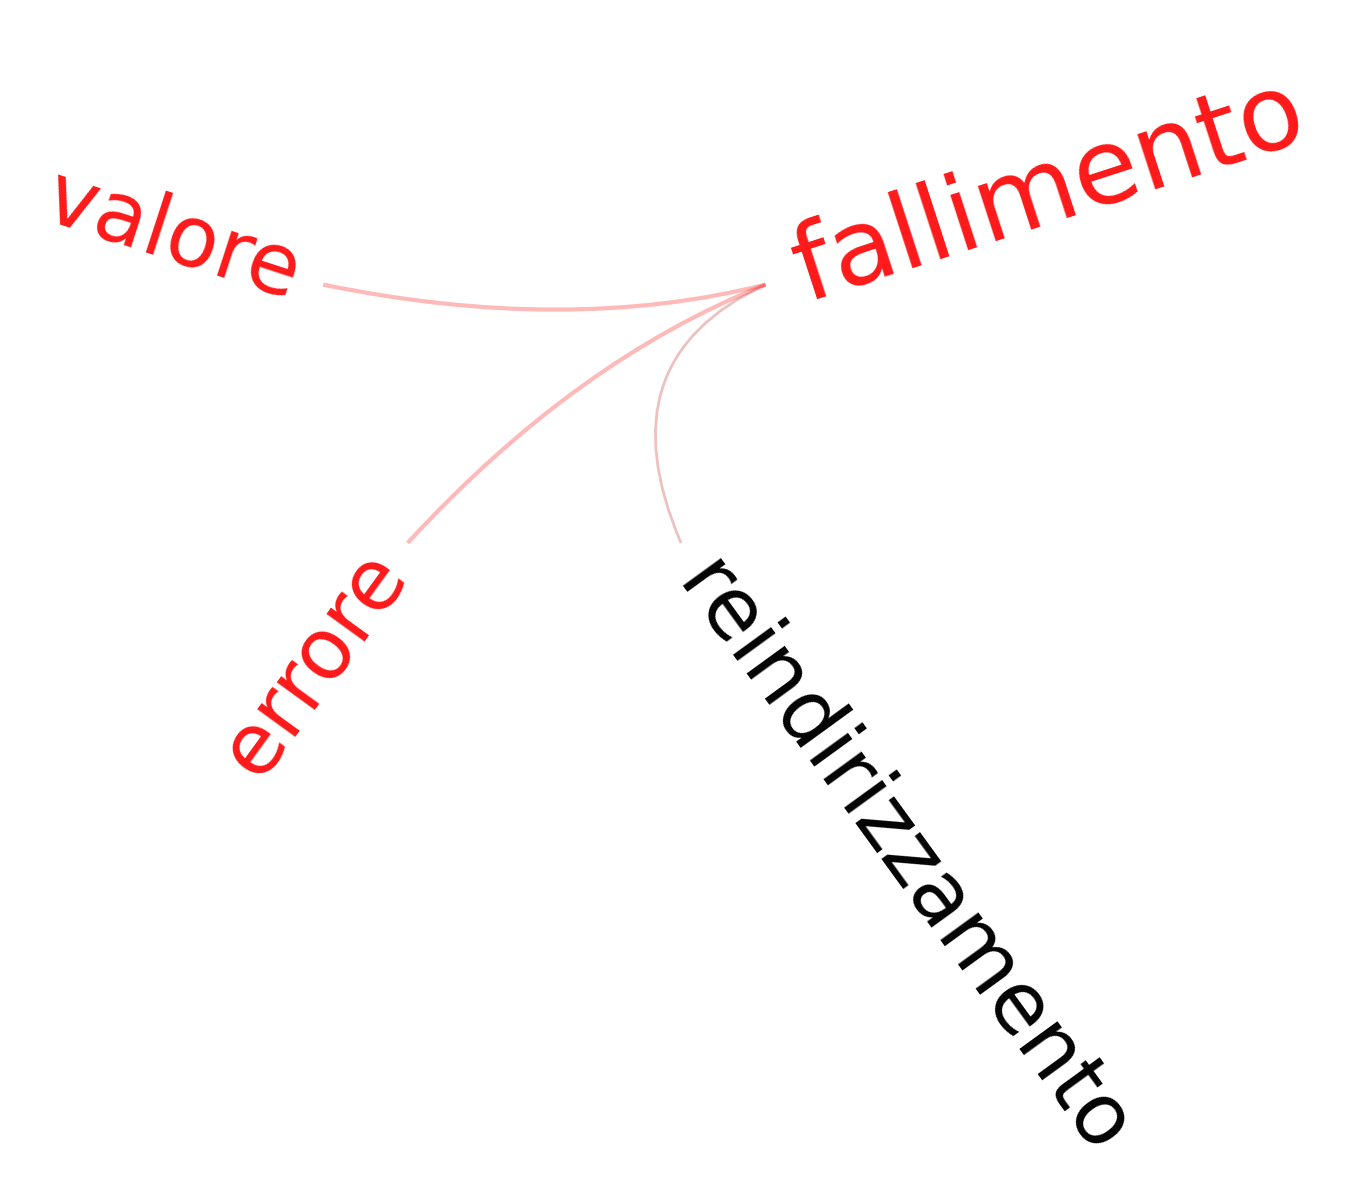

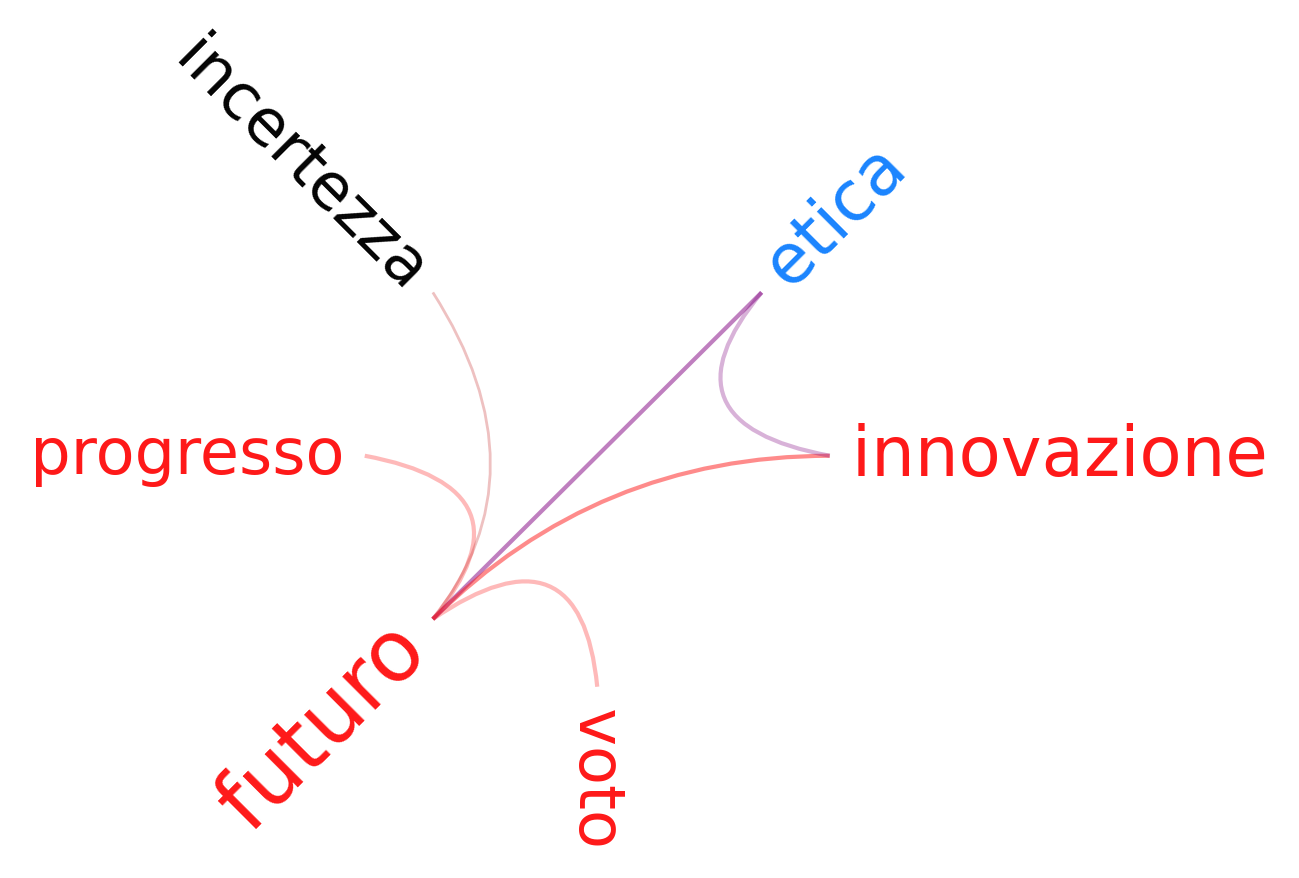

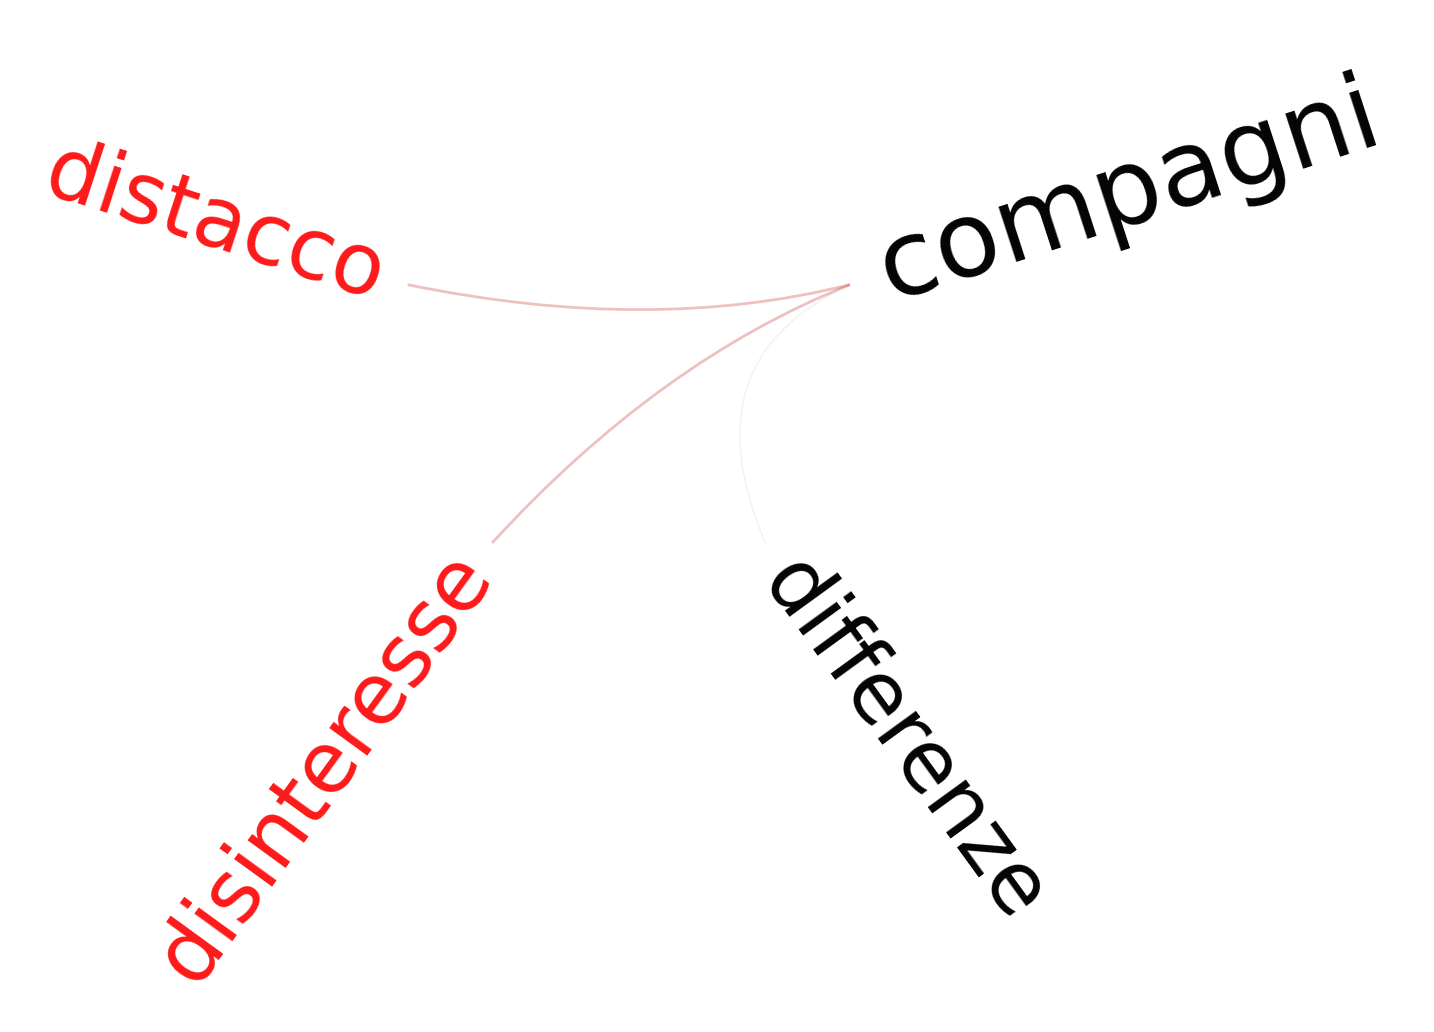

Processing participant: fisica_stem_002_2


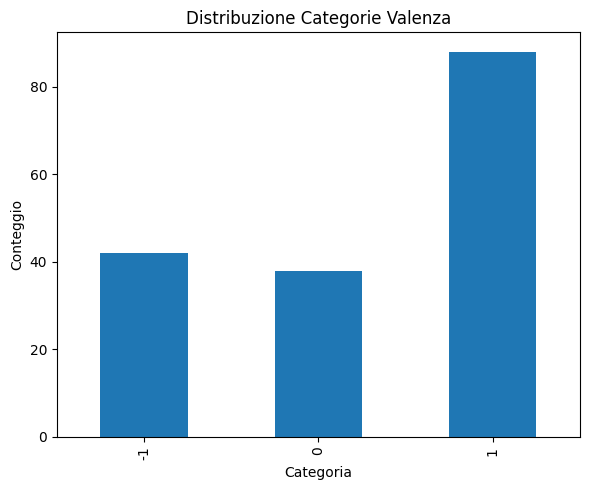

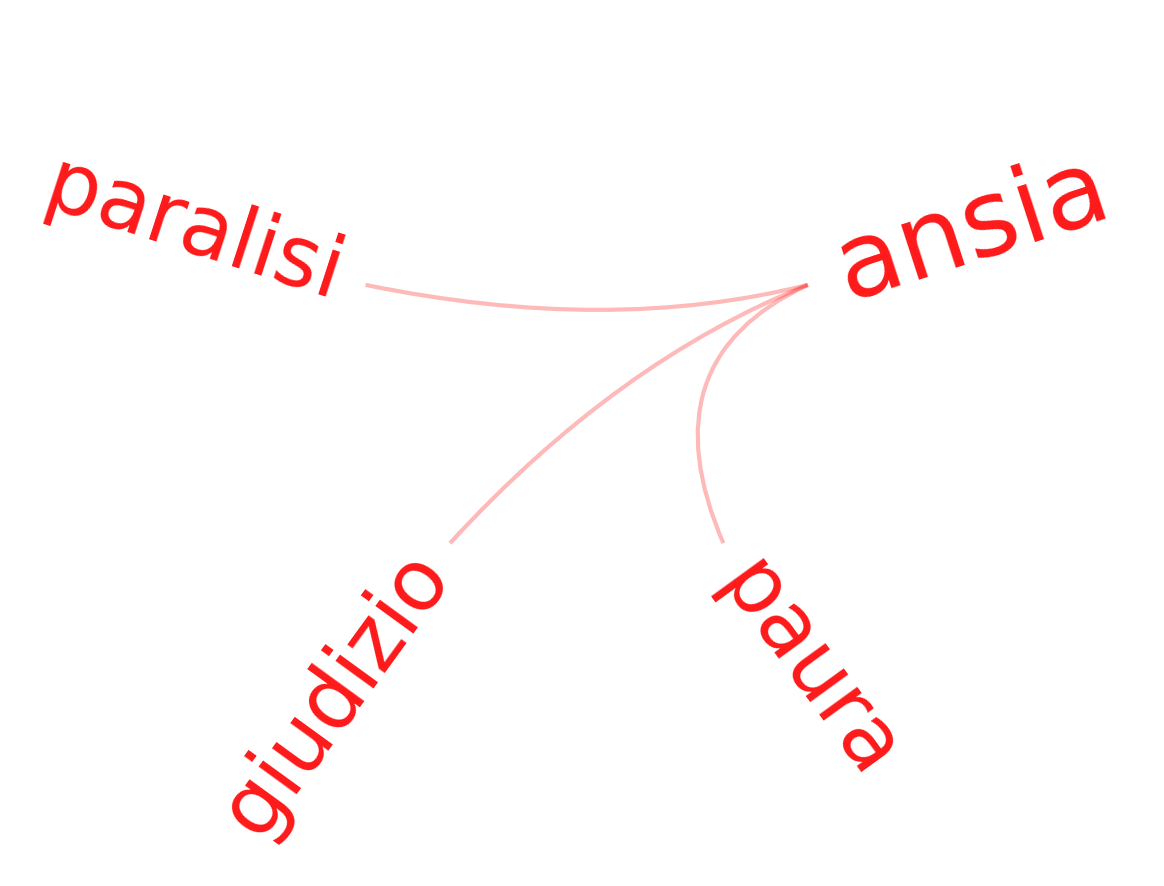

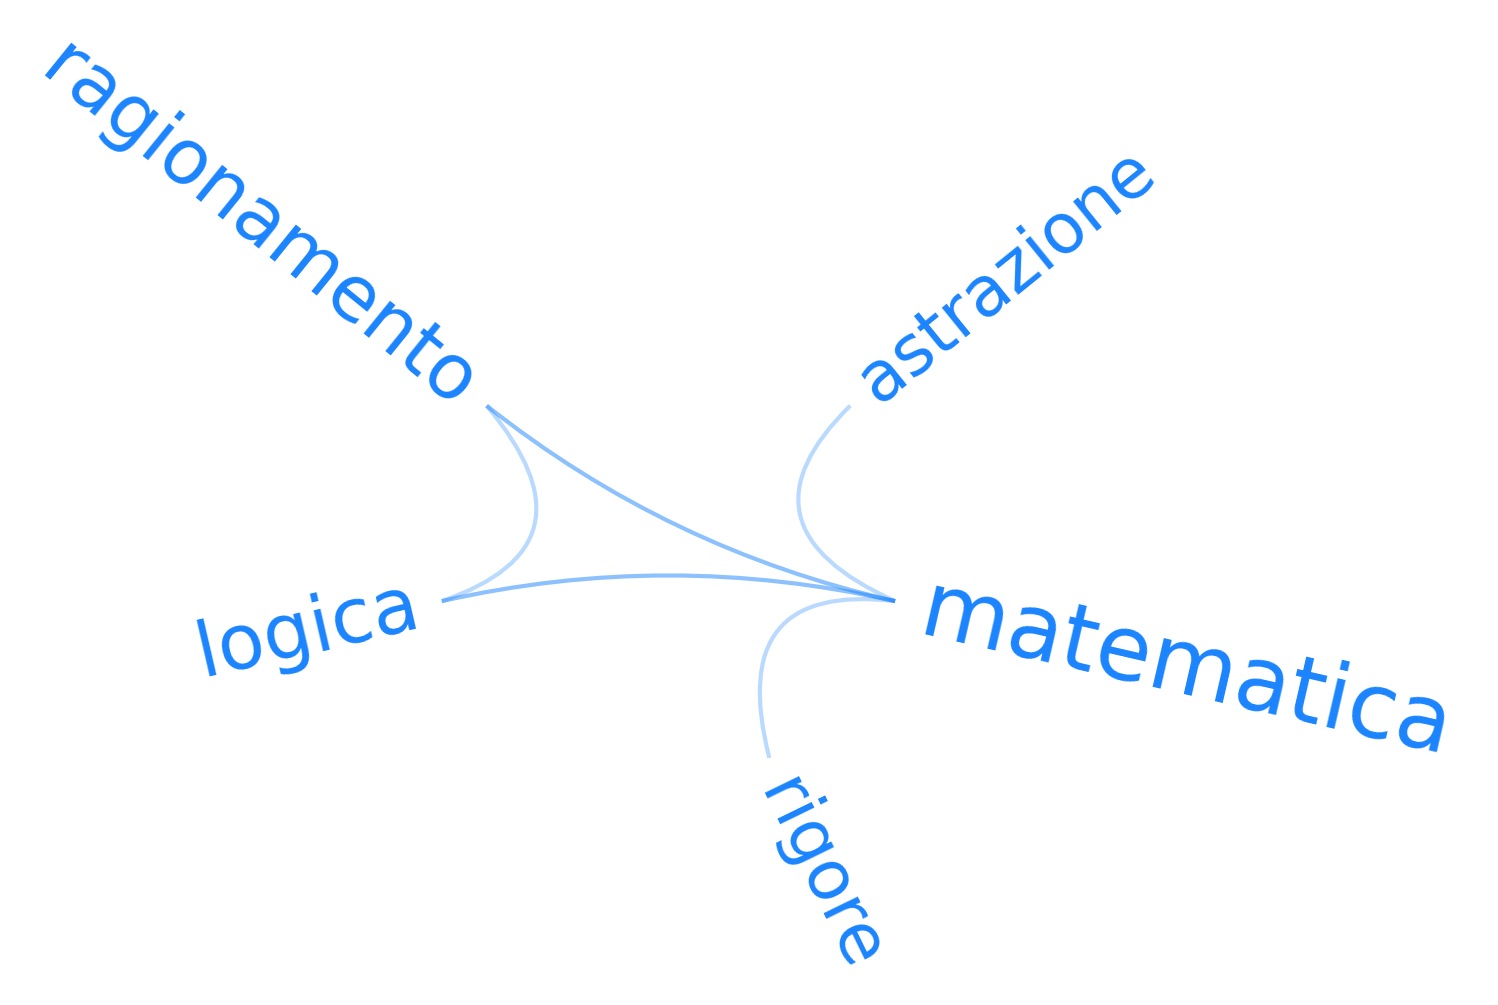

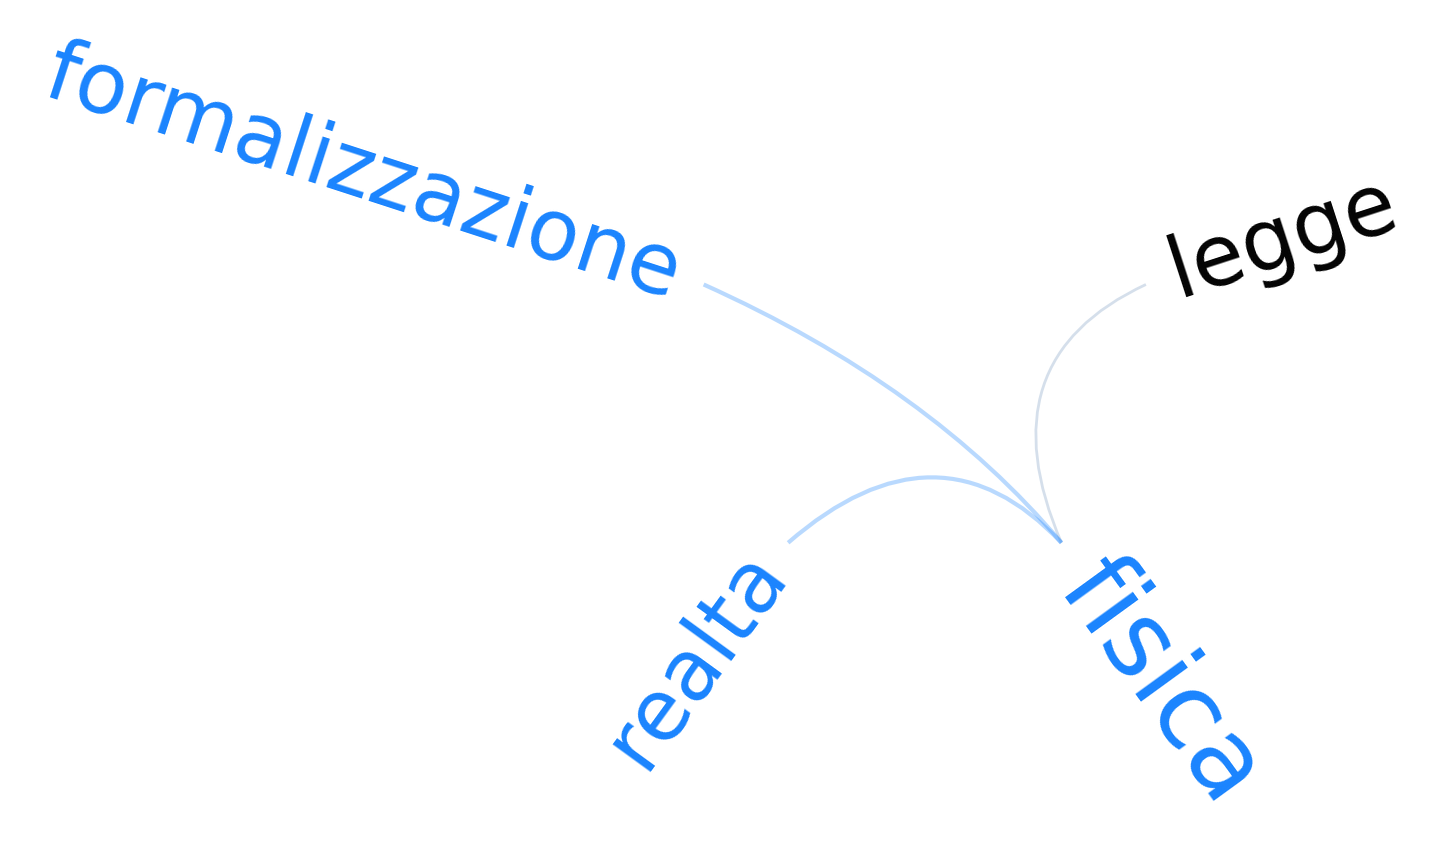

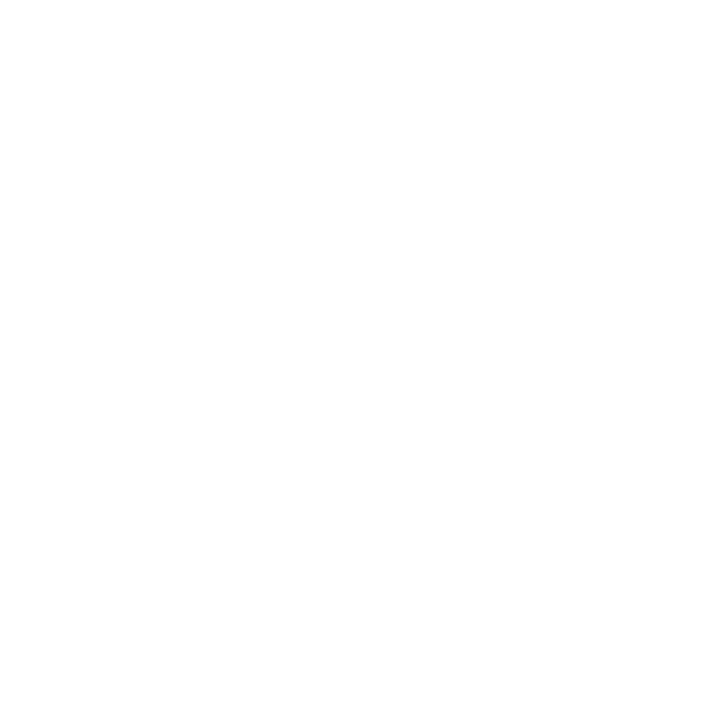

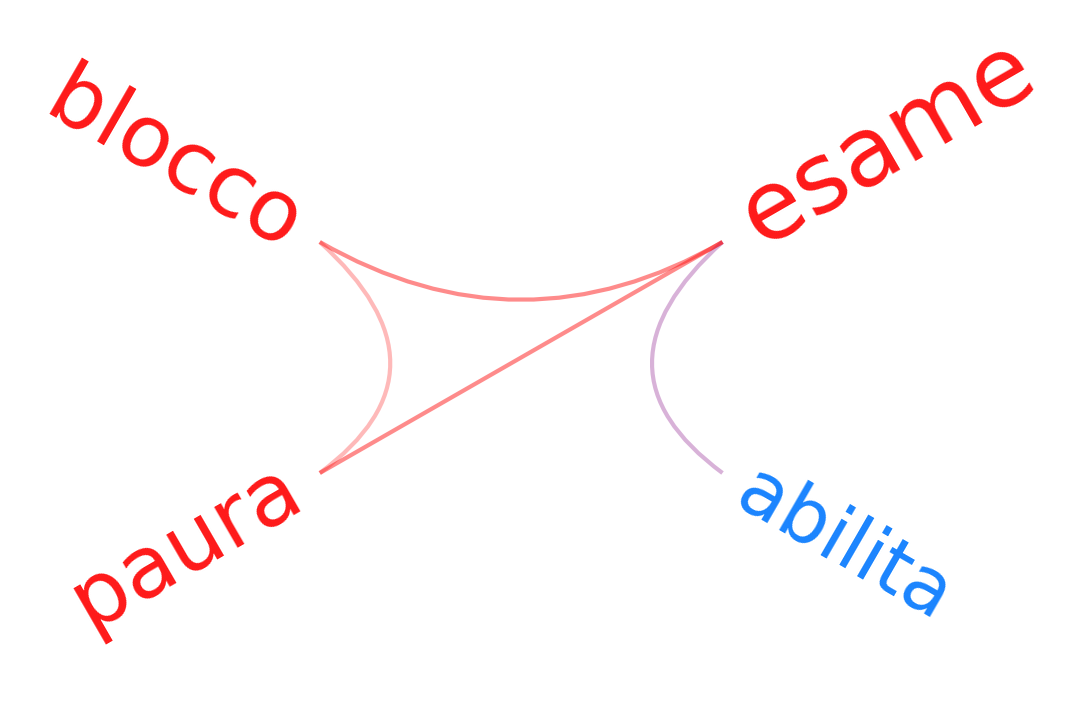

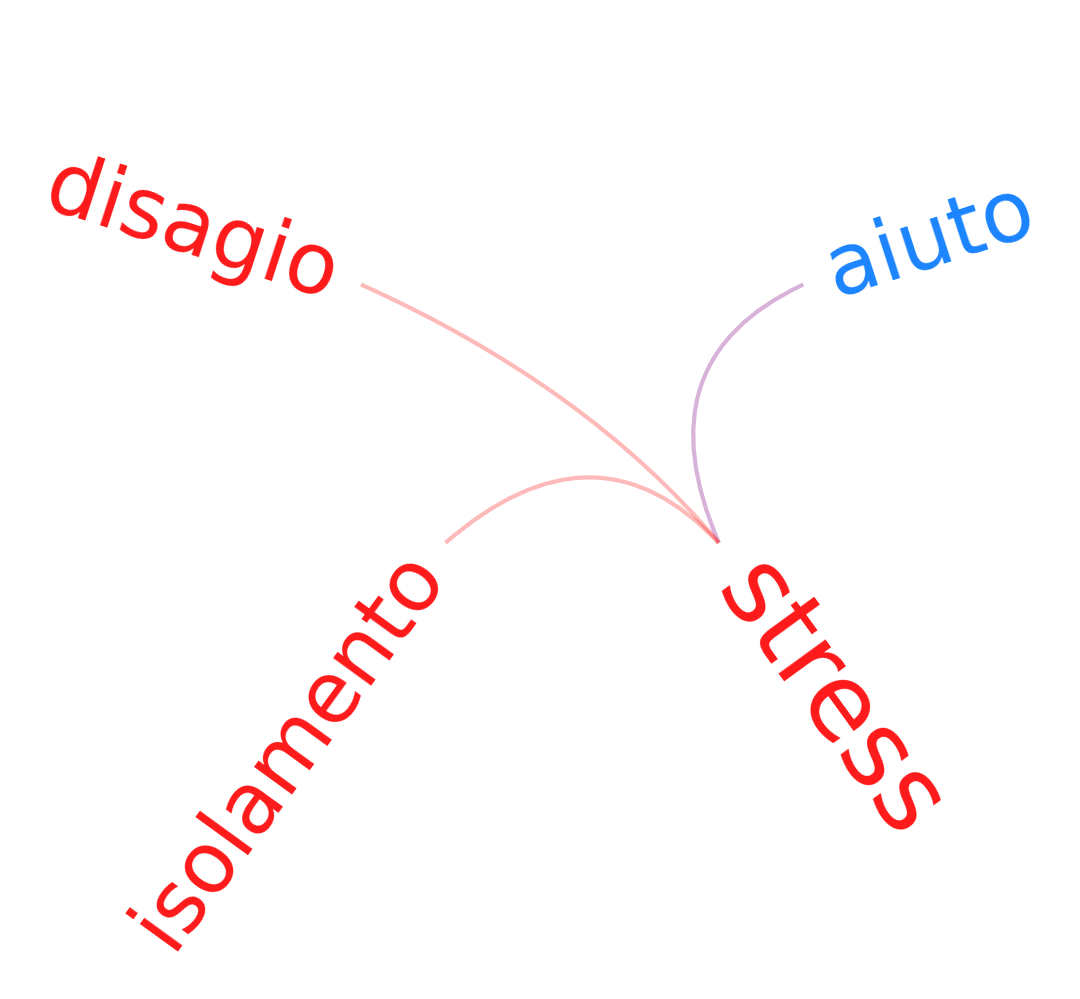

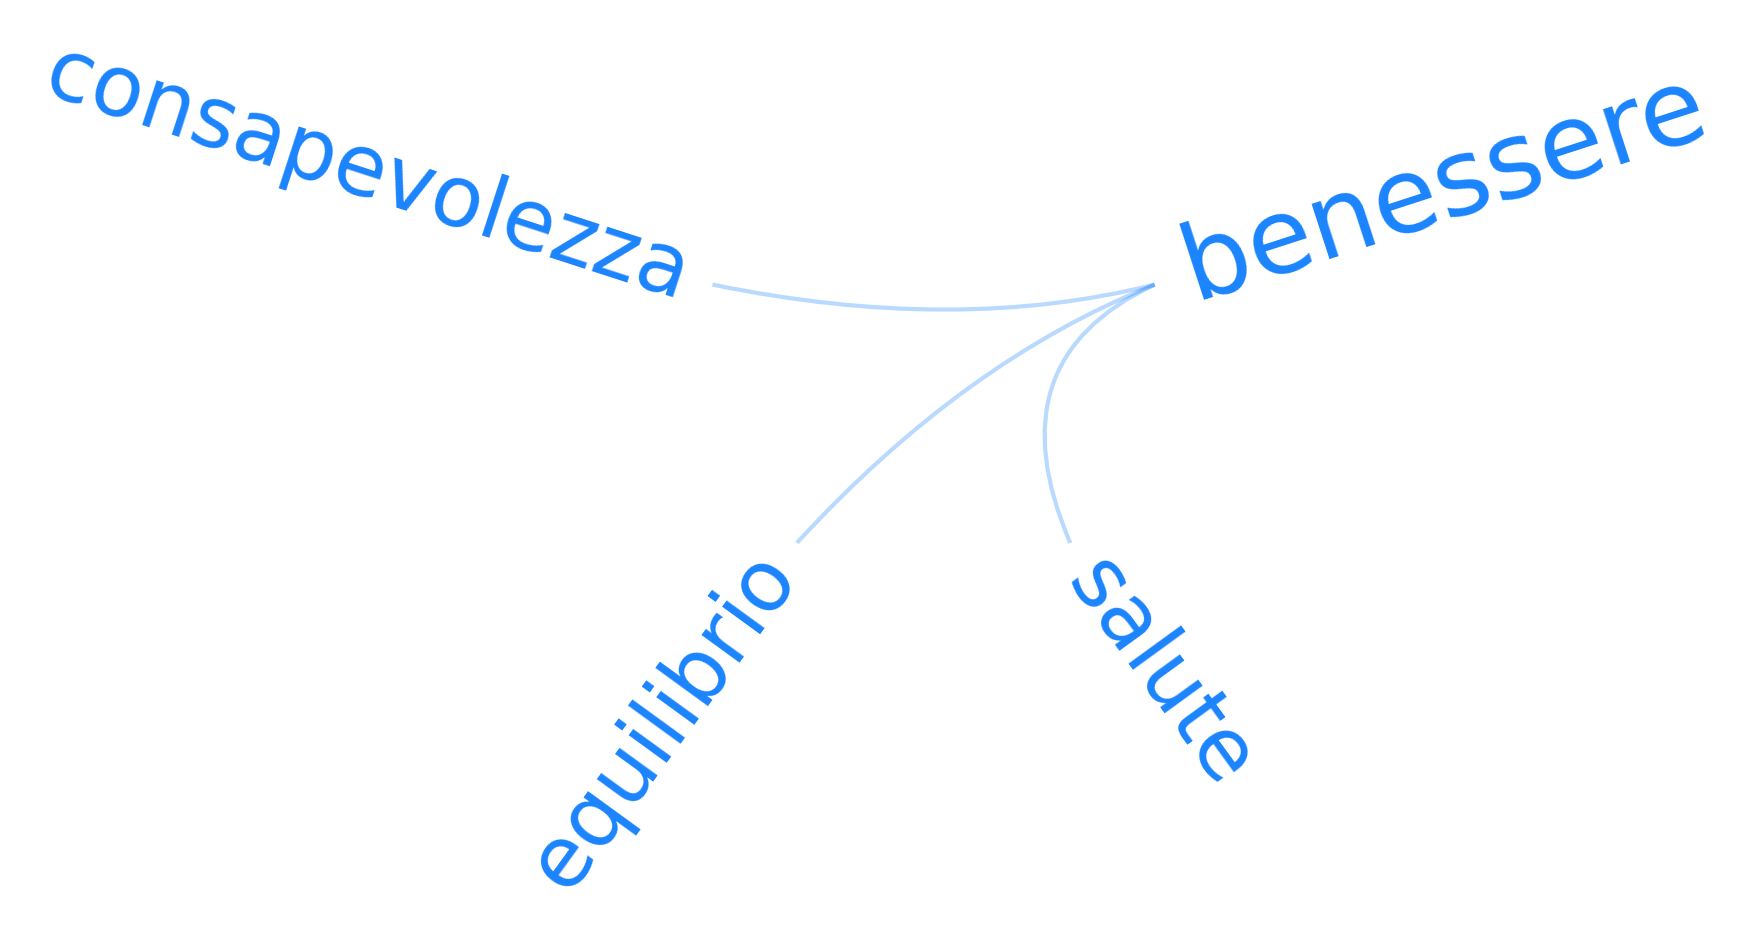

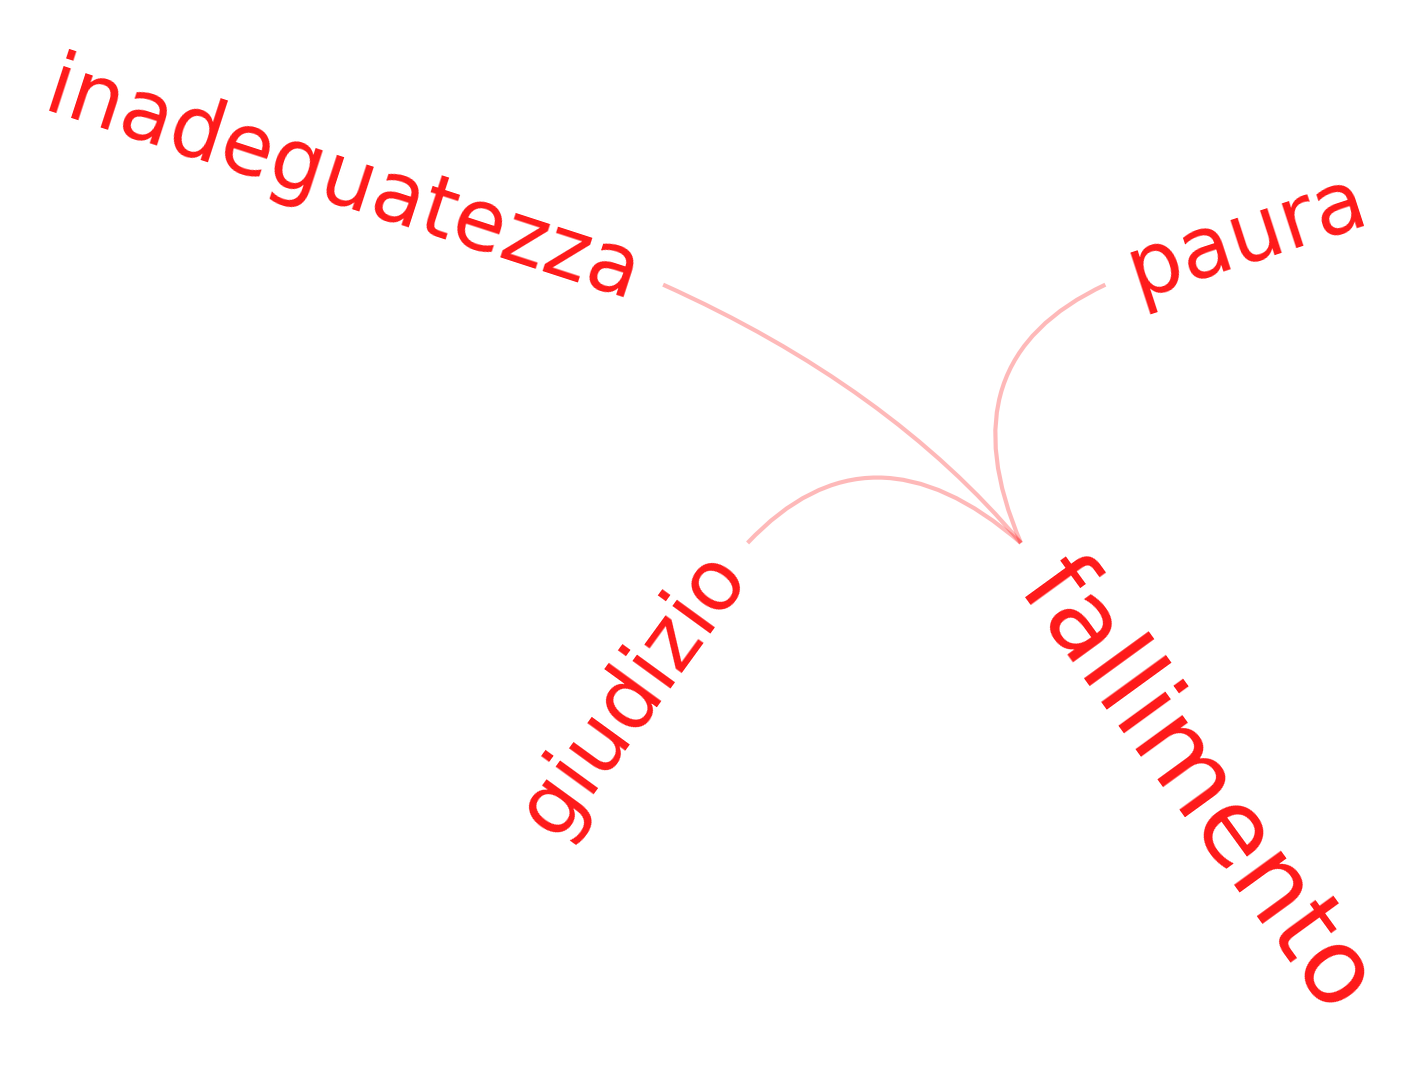

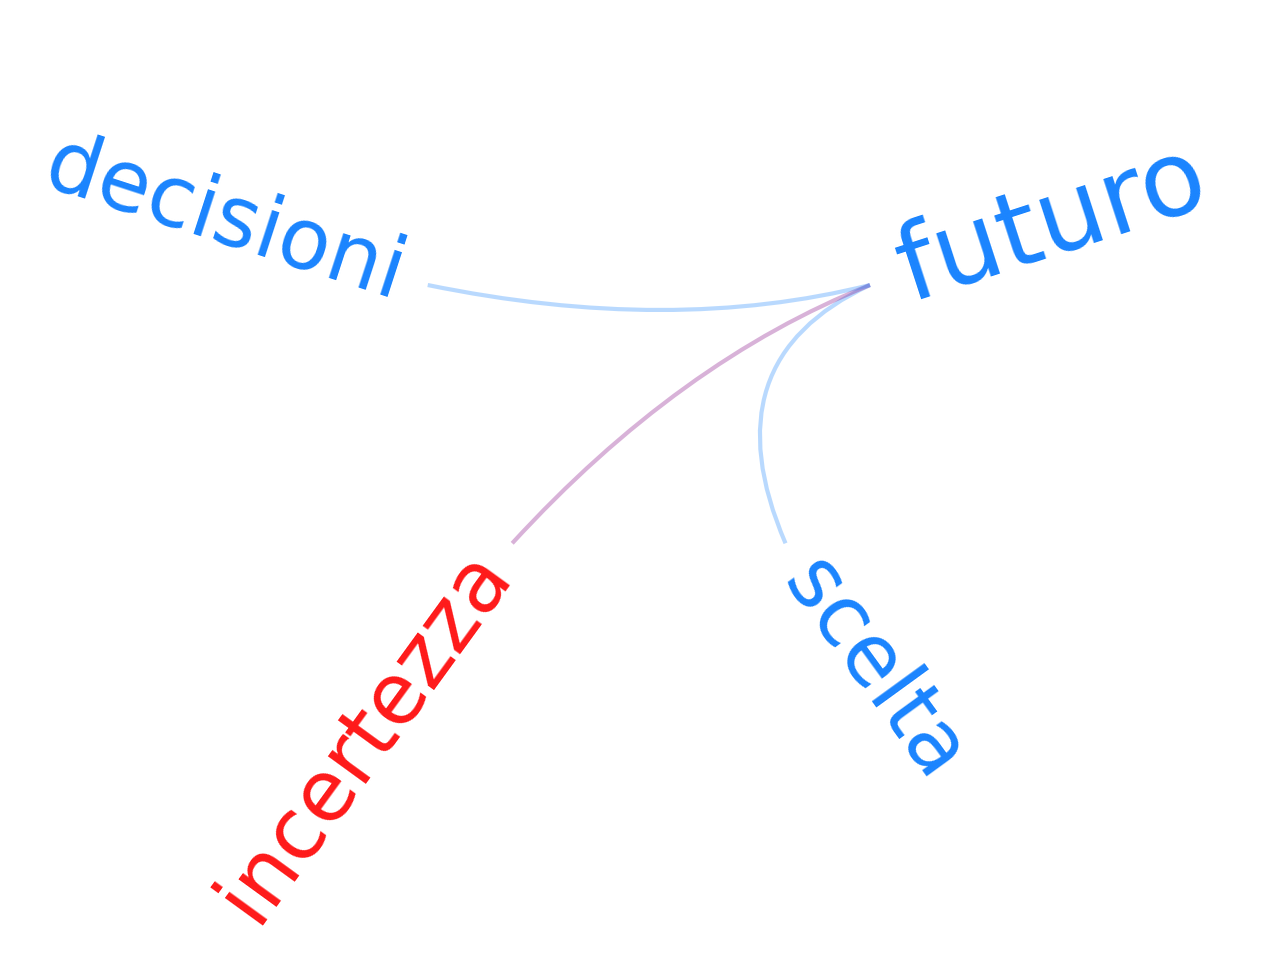

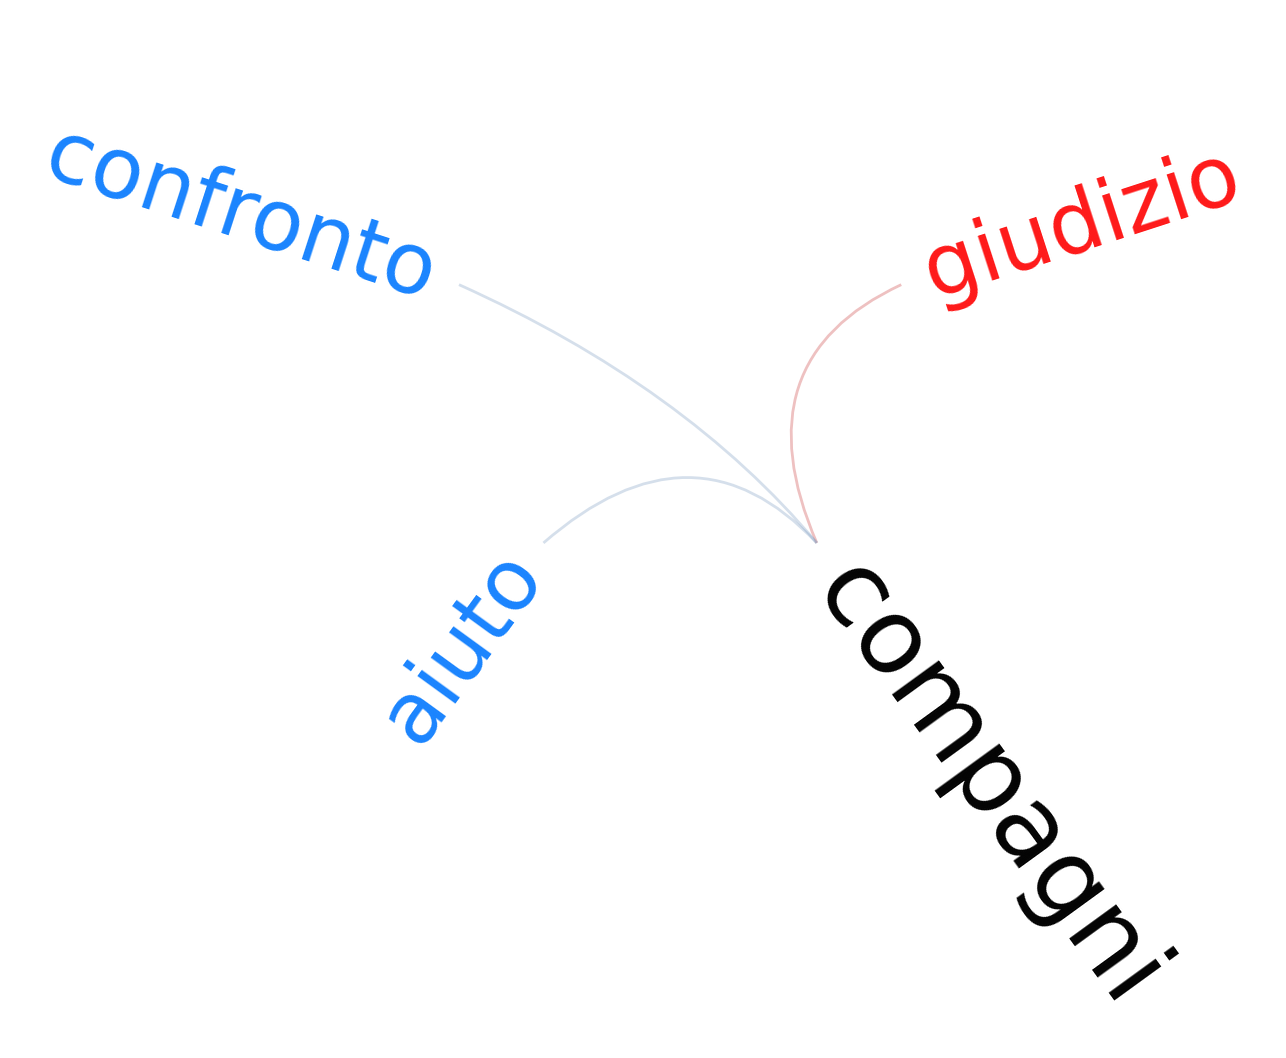

Processing participant: fisica_stem_001_2


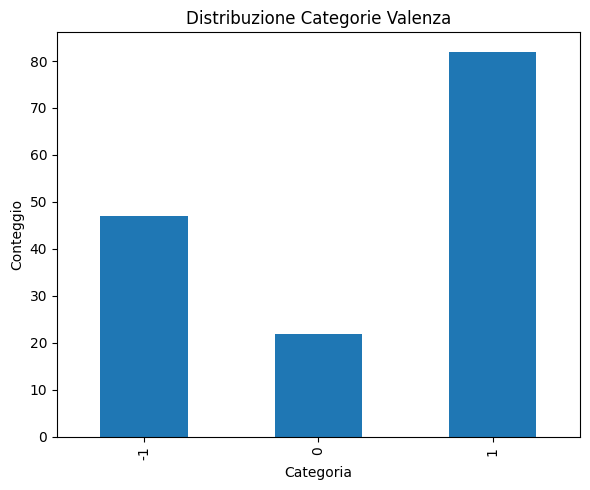

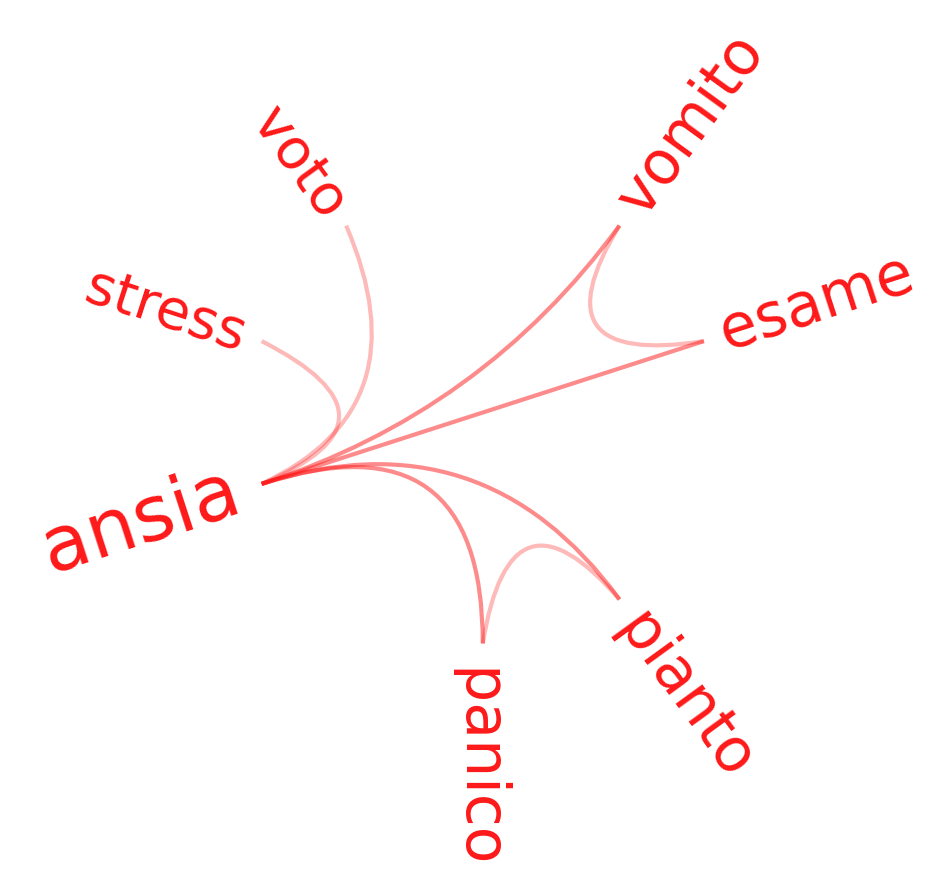

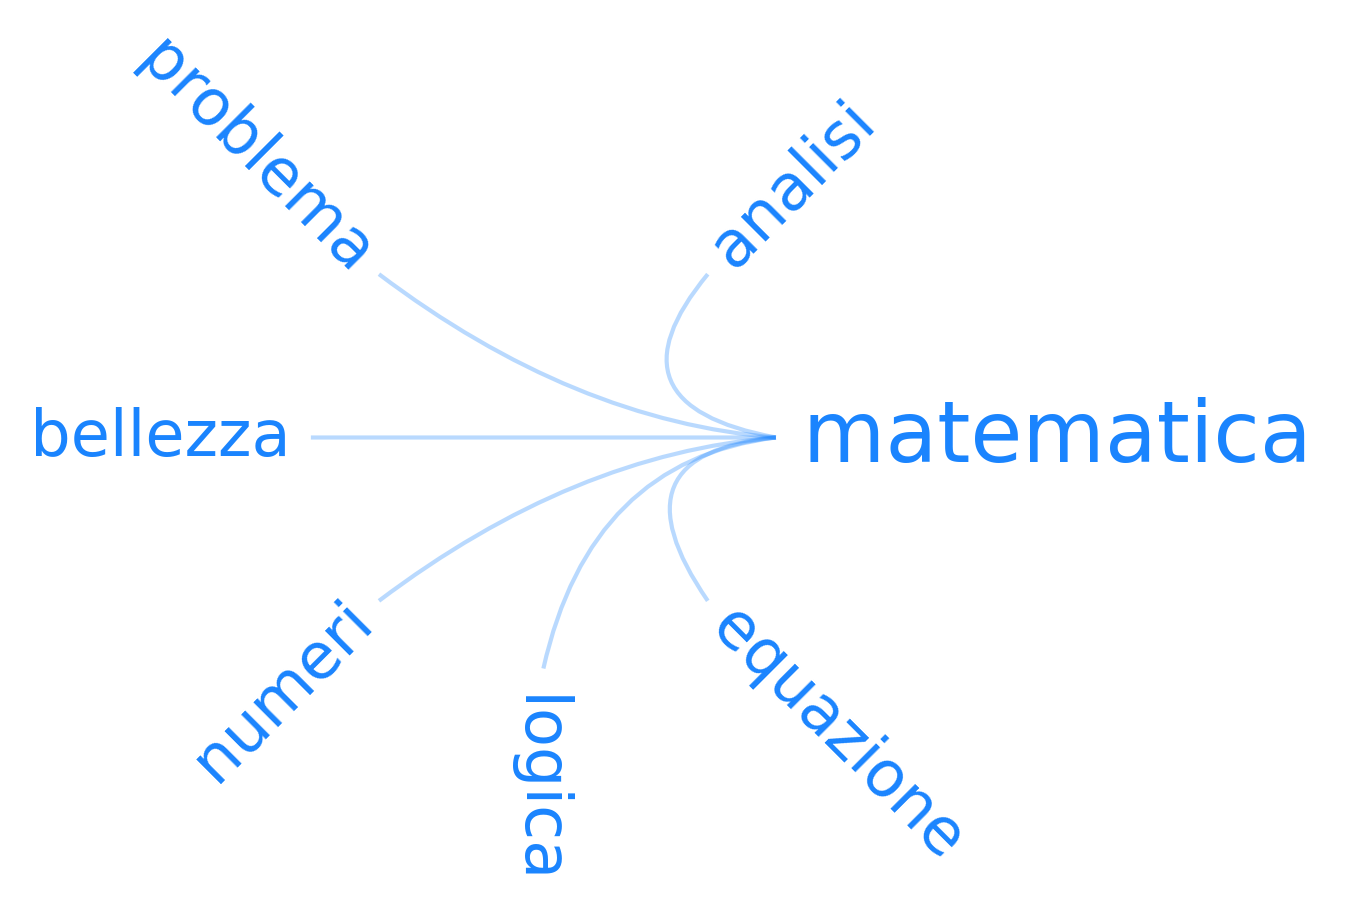

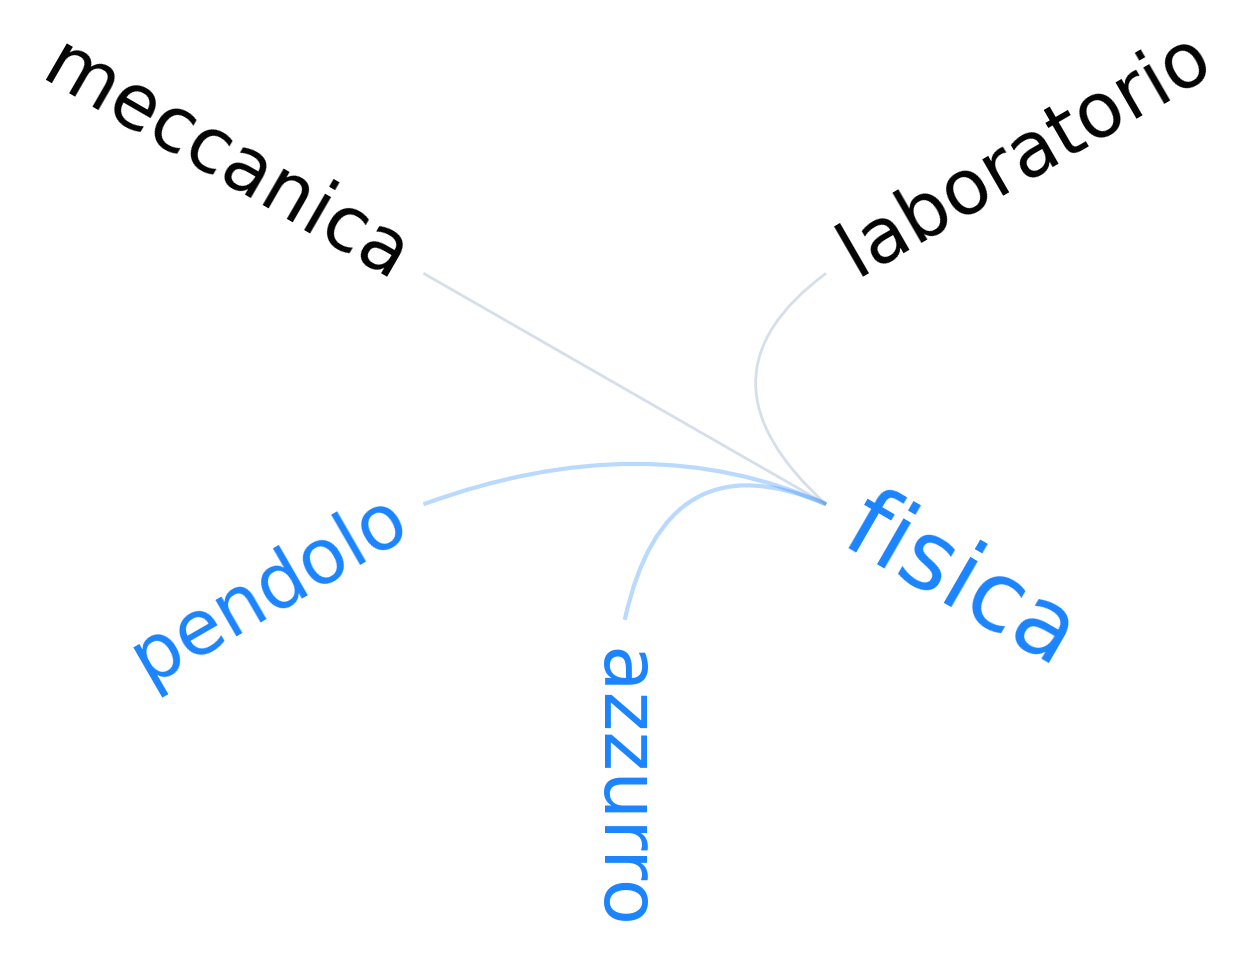

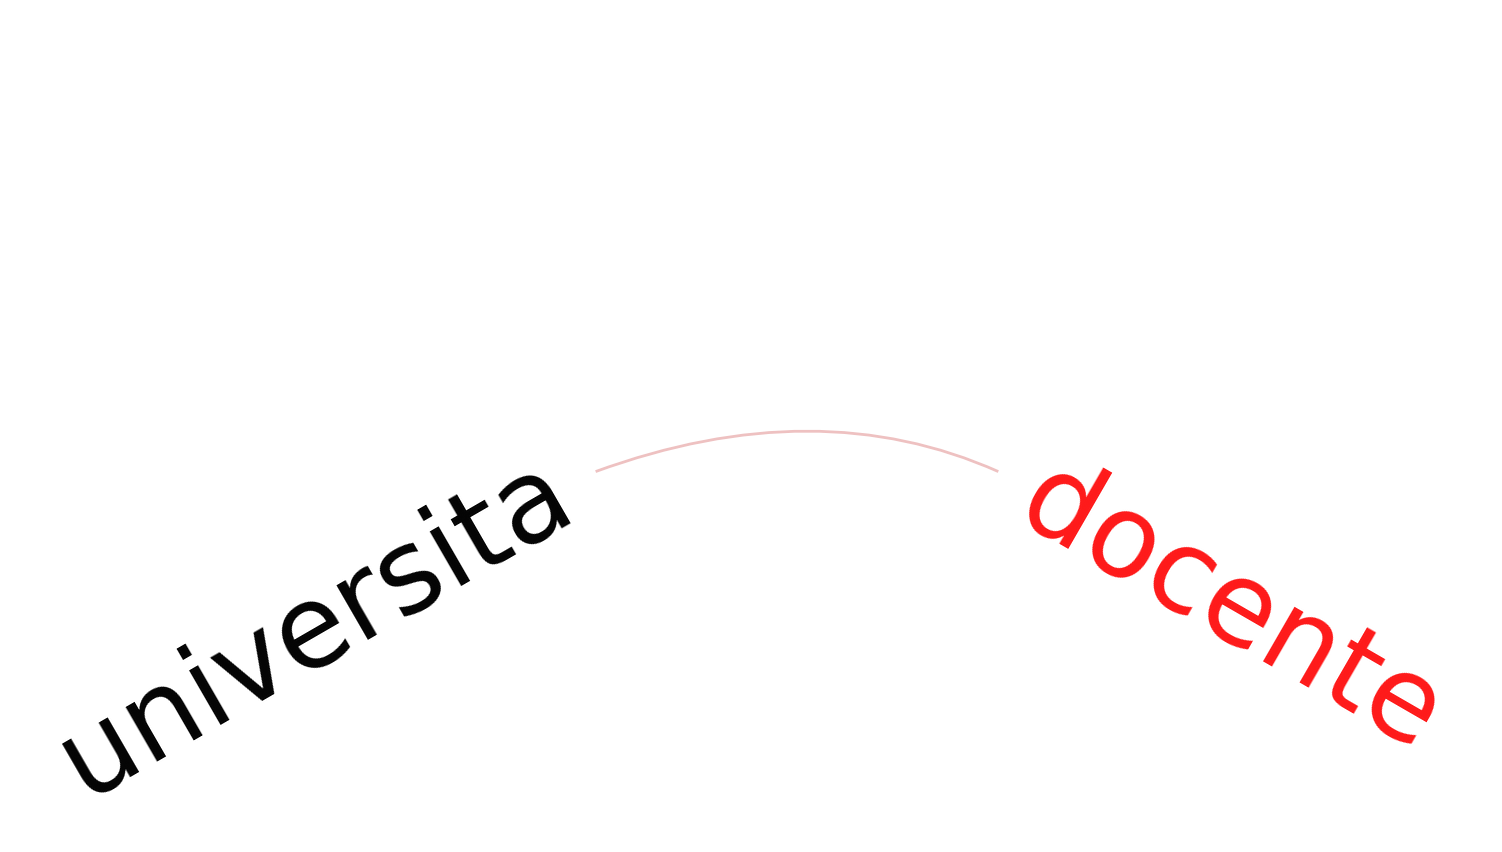

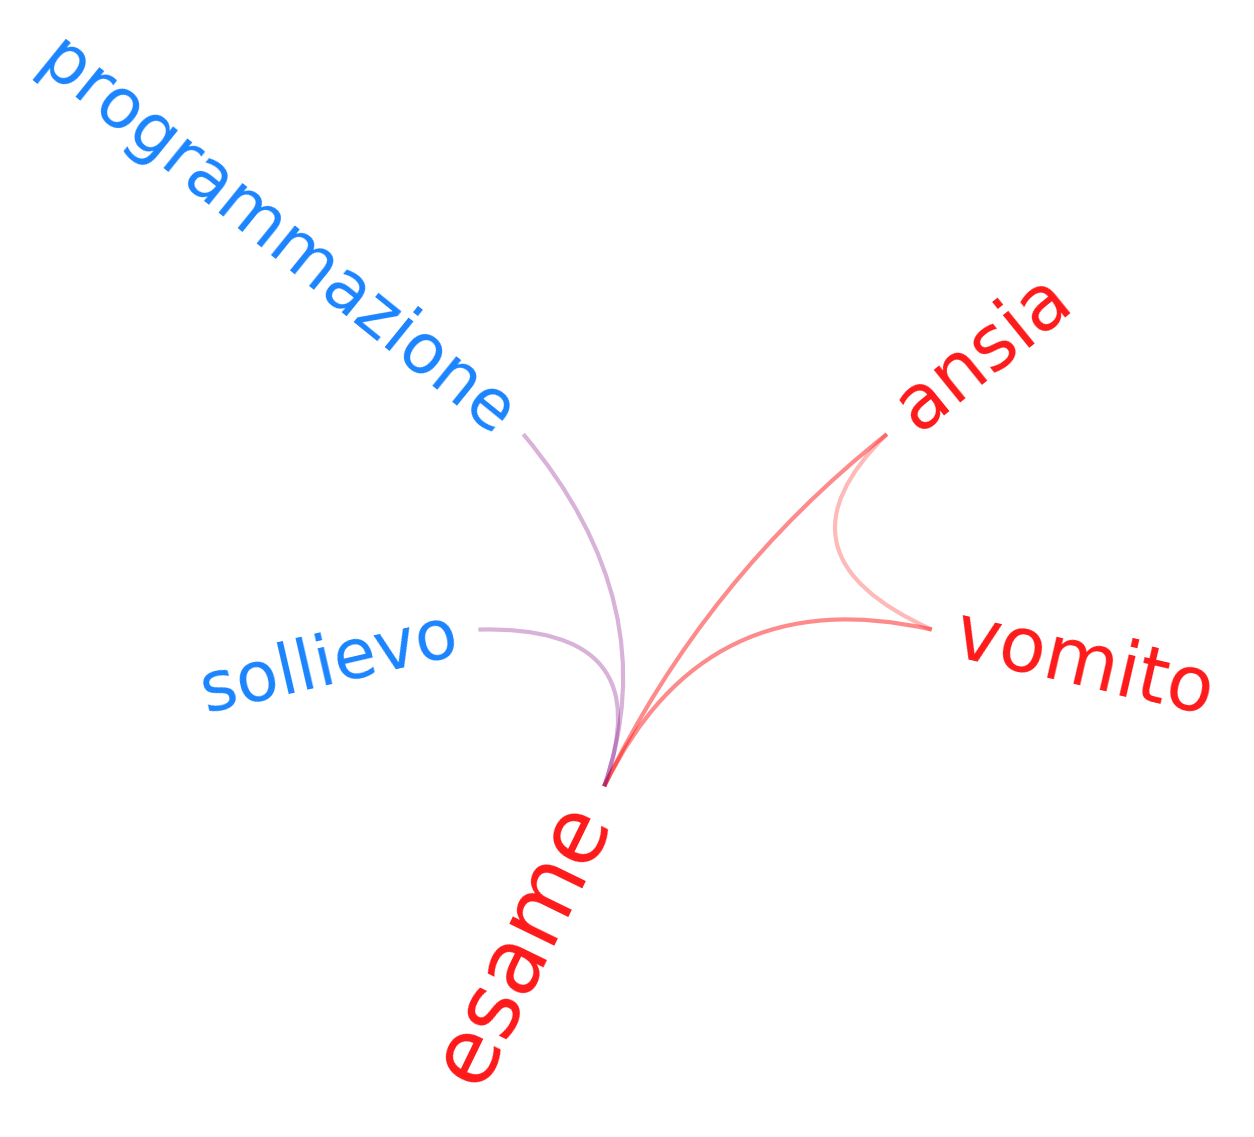

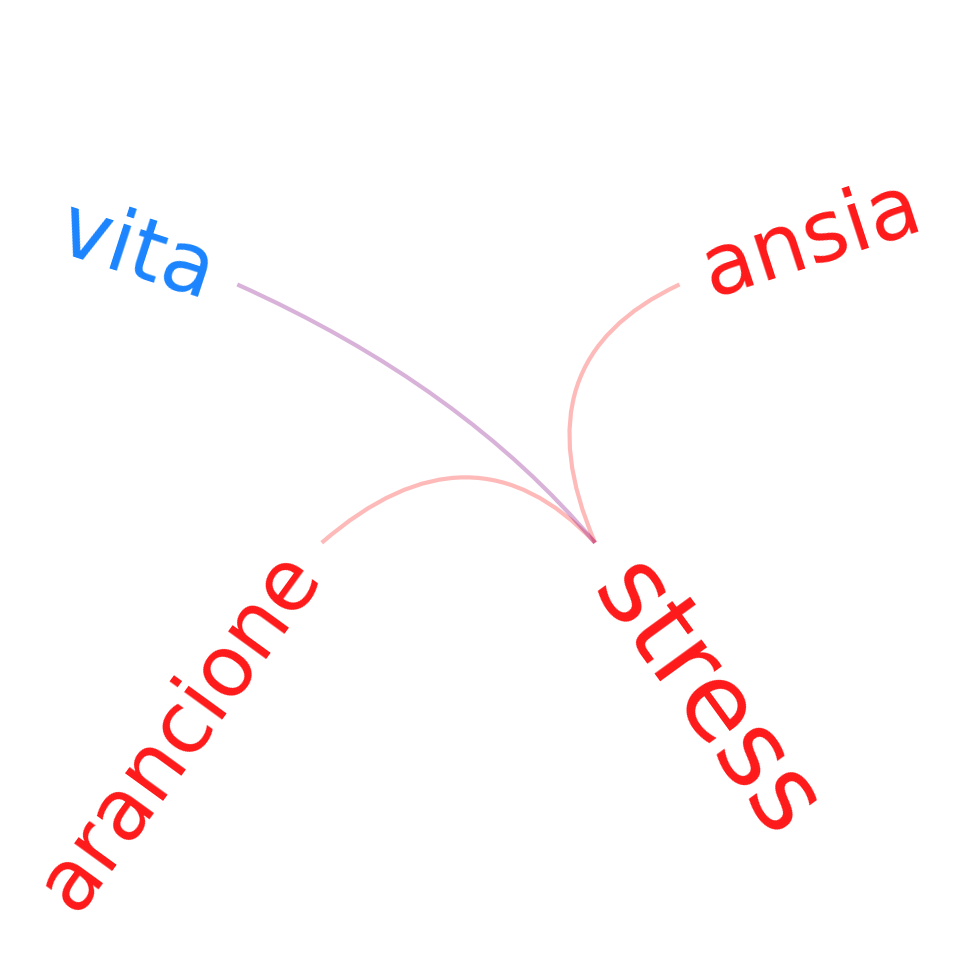

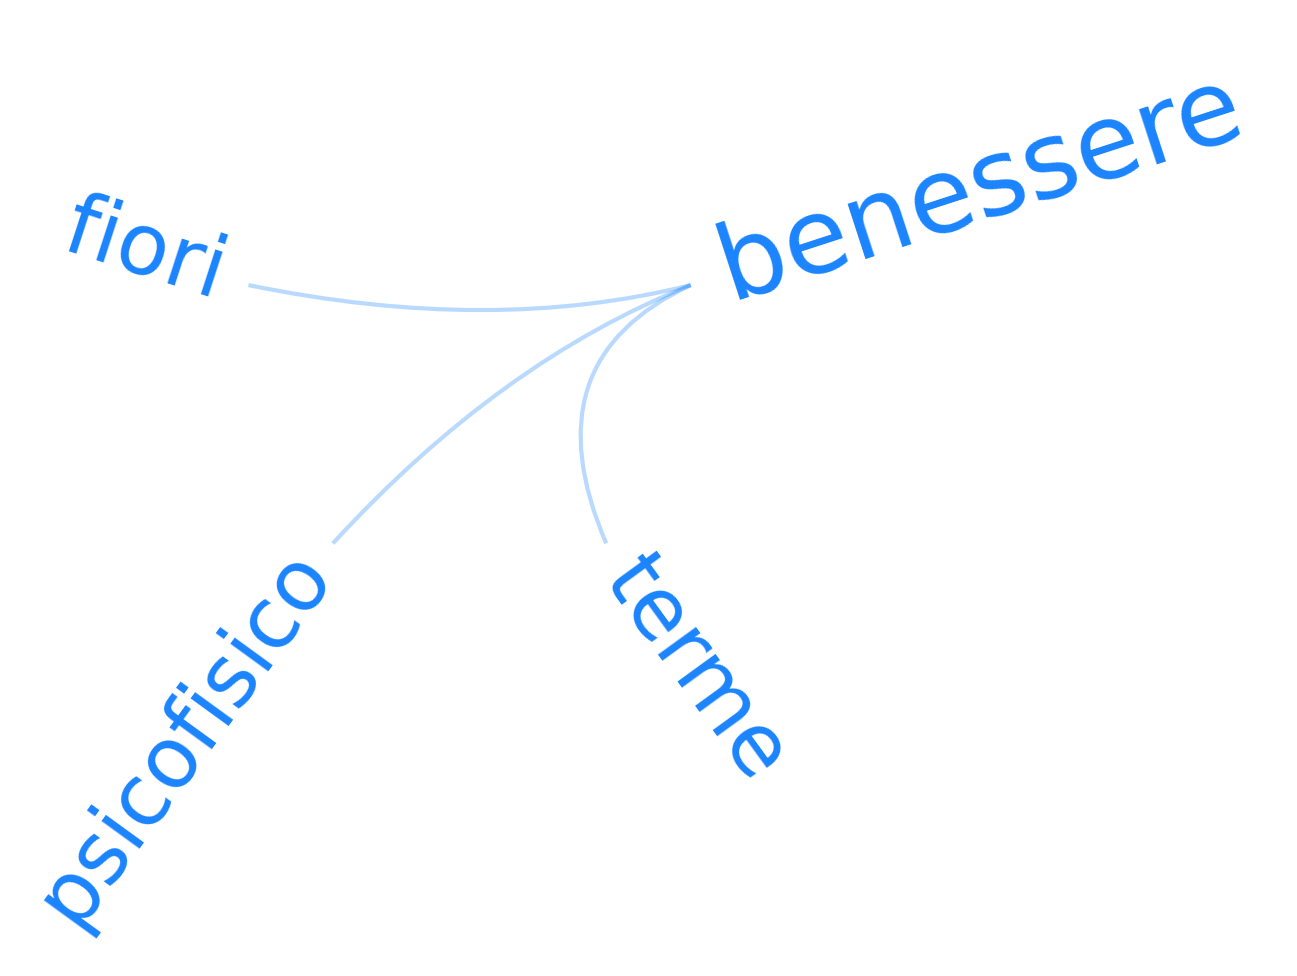

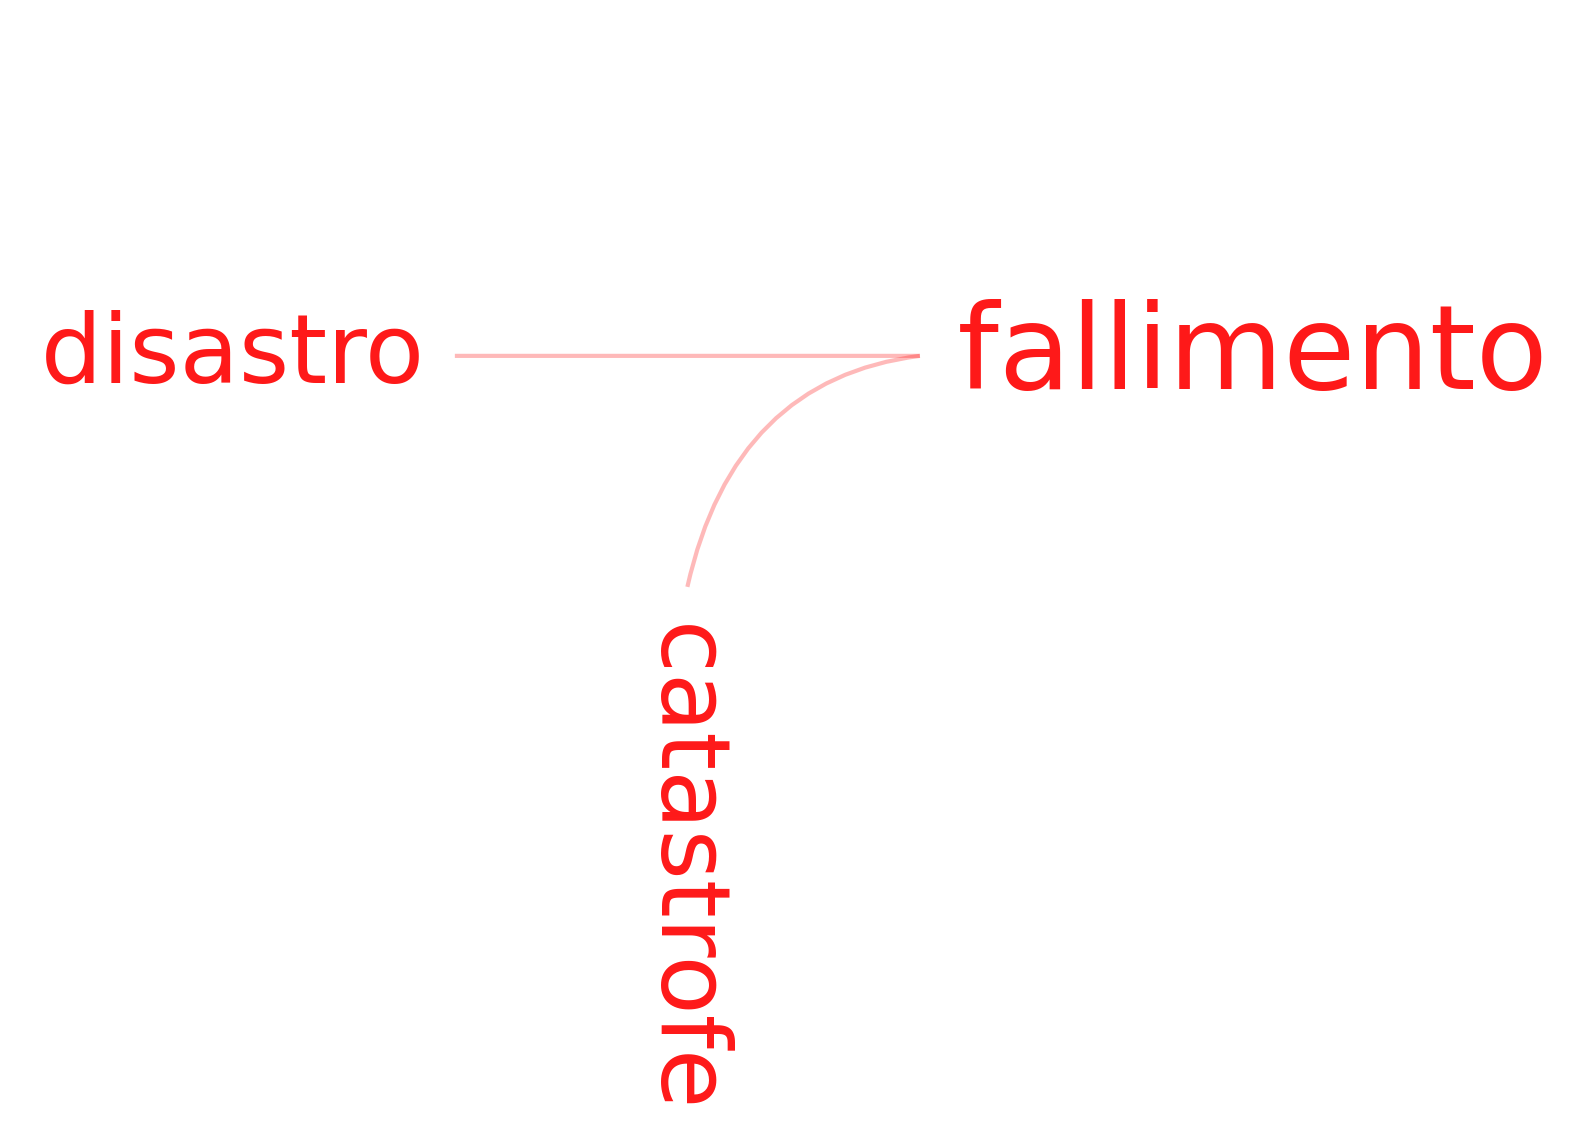

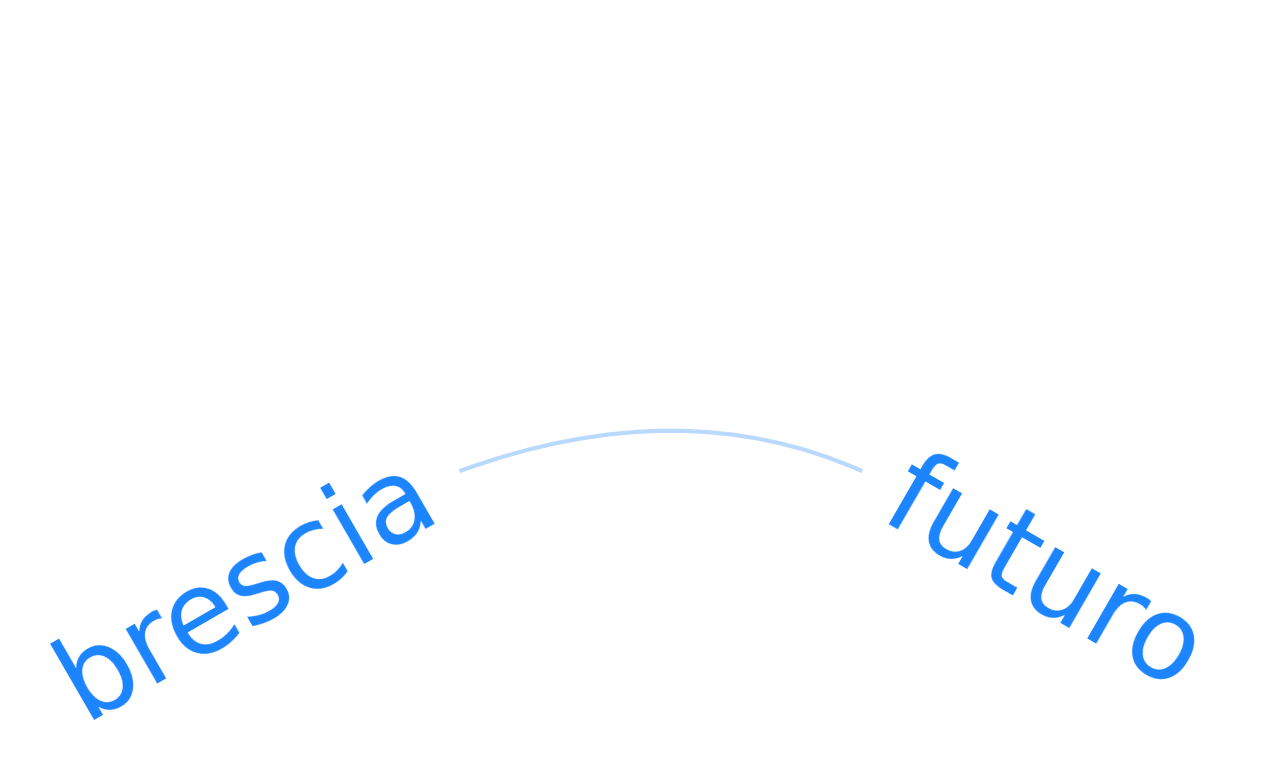

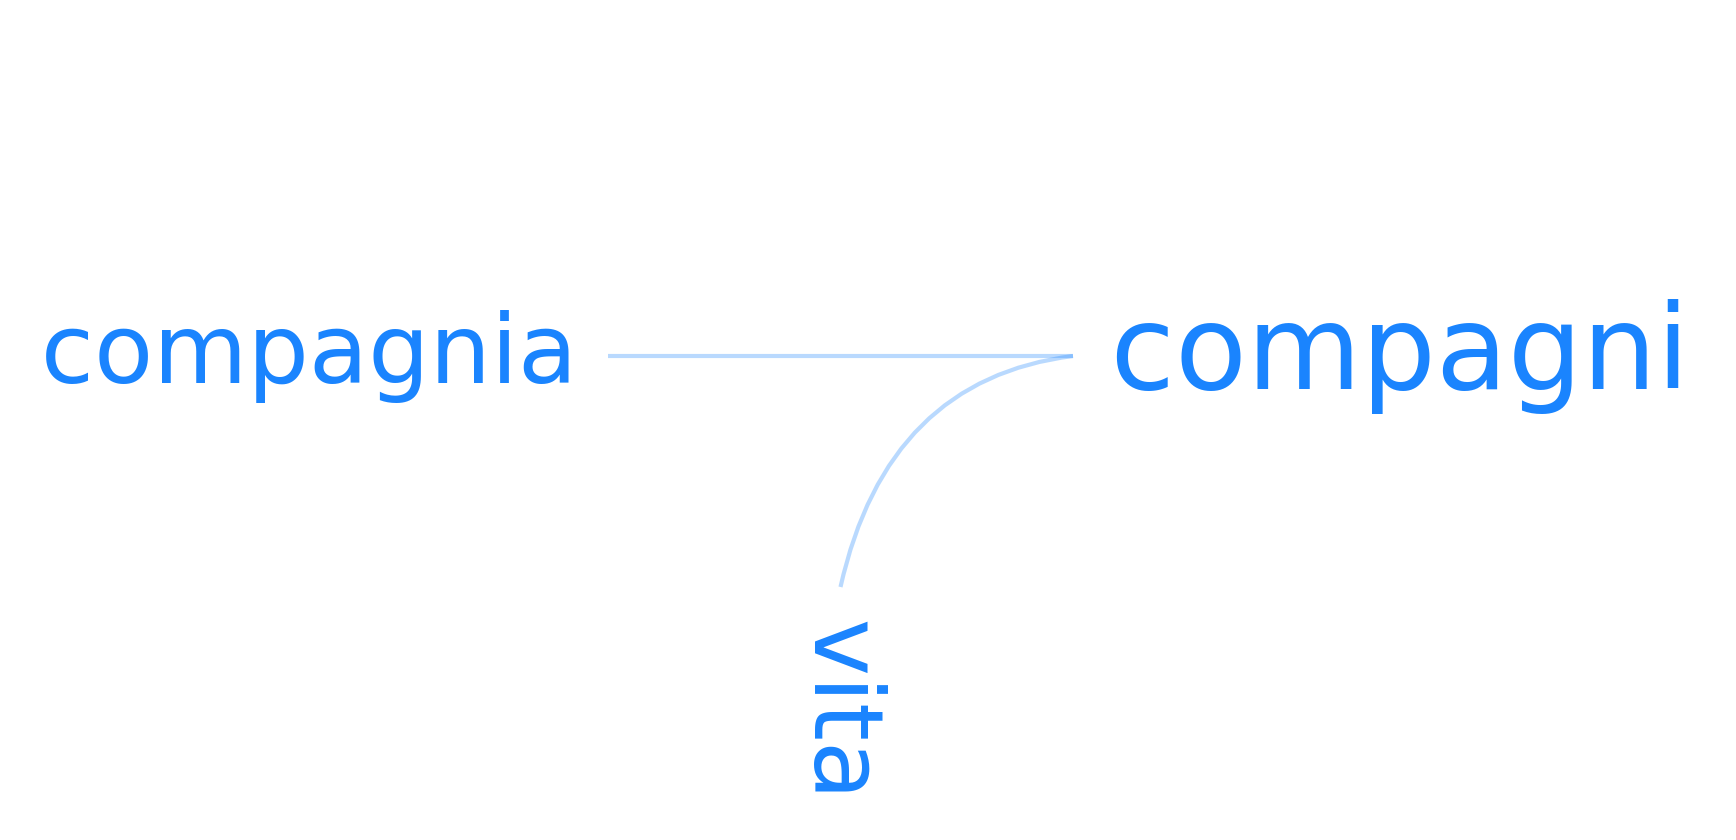

Processing participant: fisica_stem_002_3


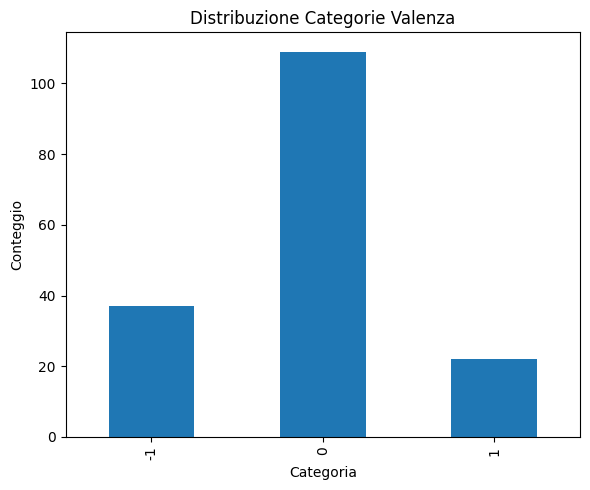

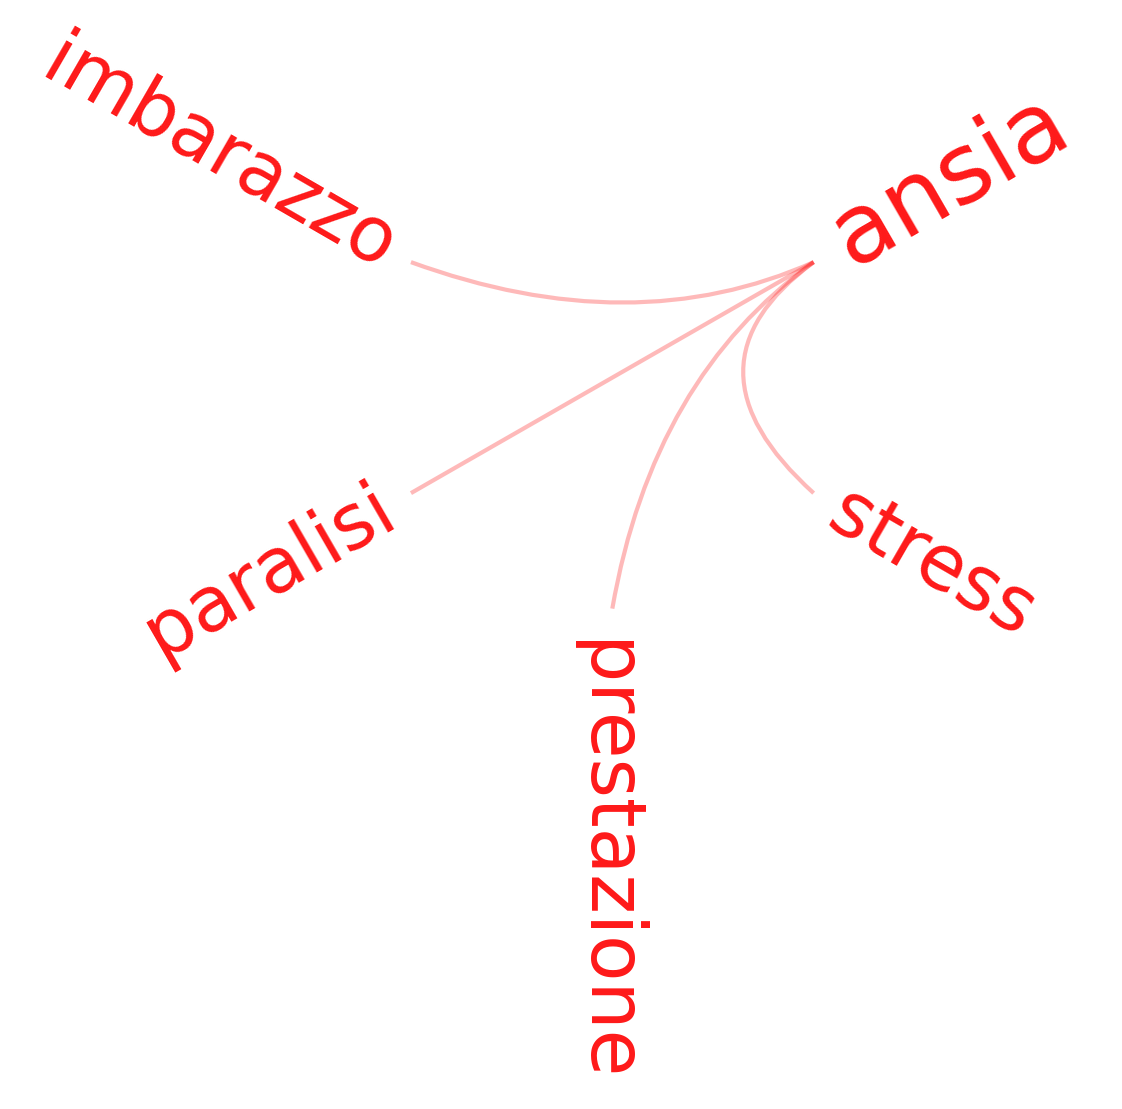

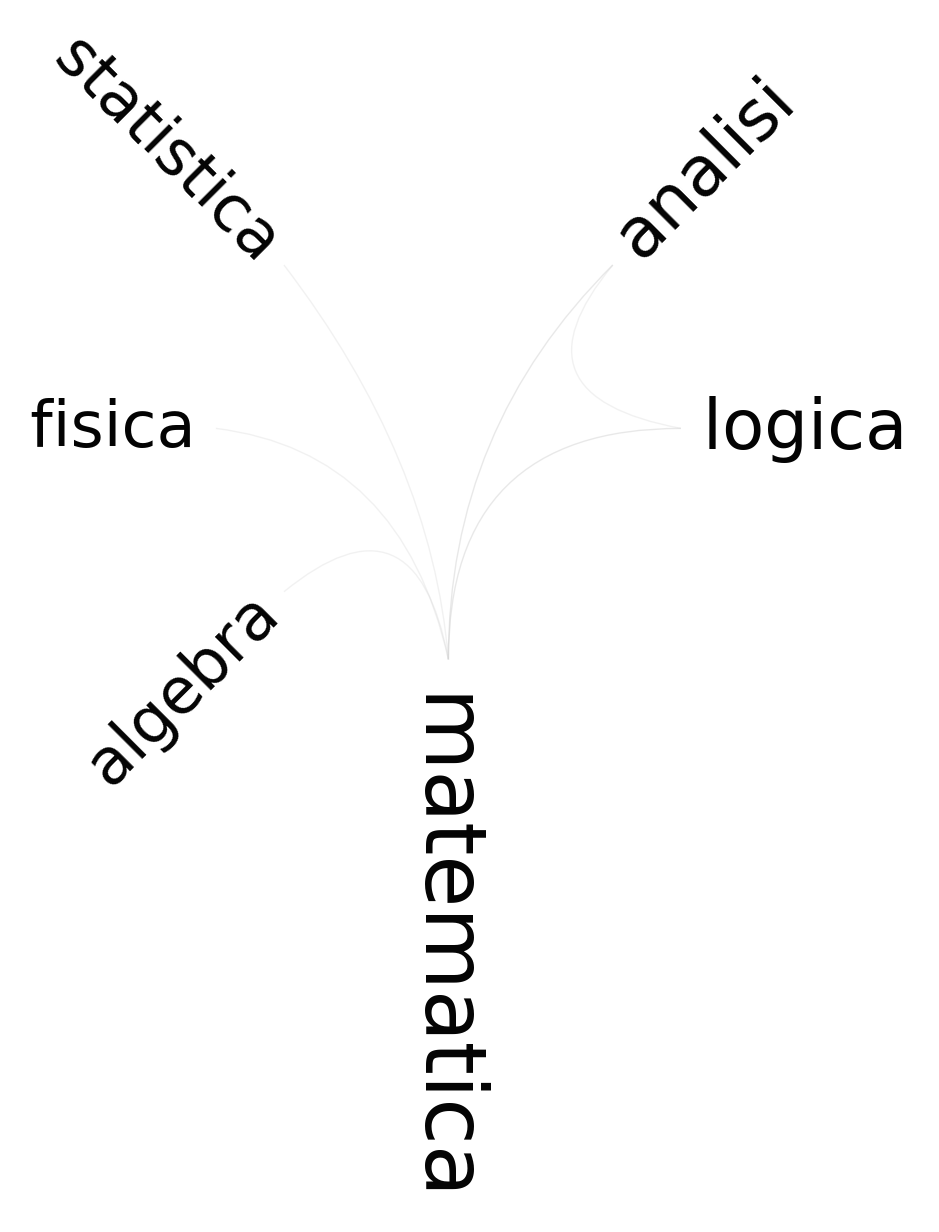

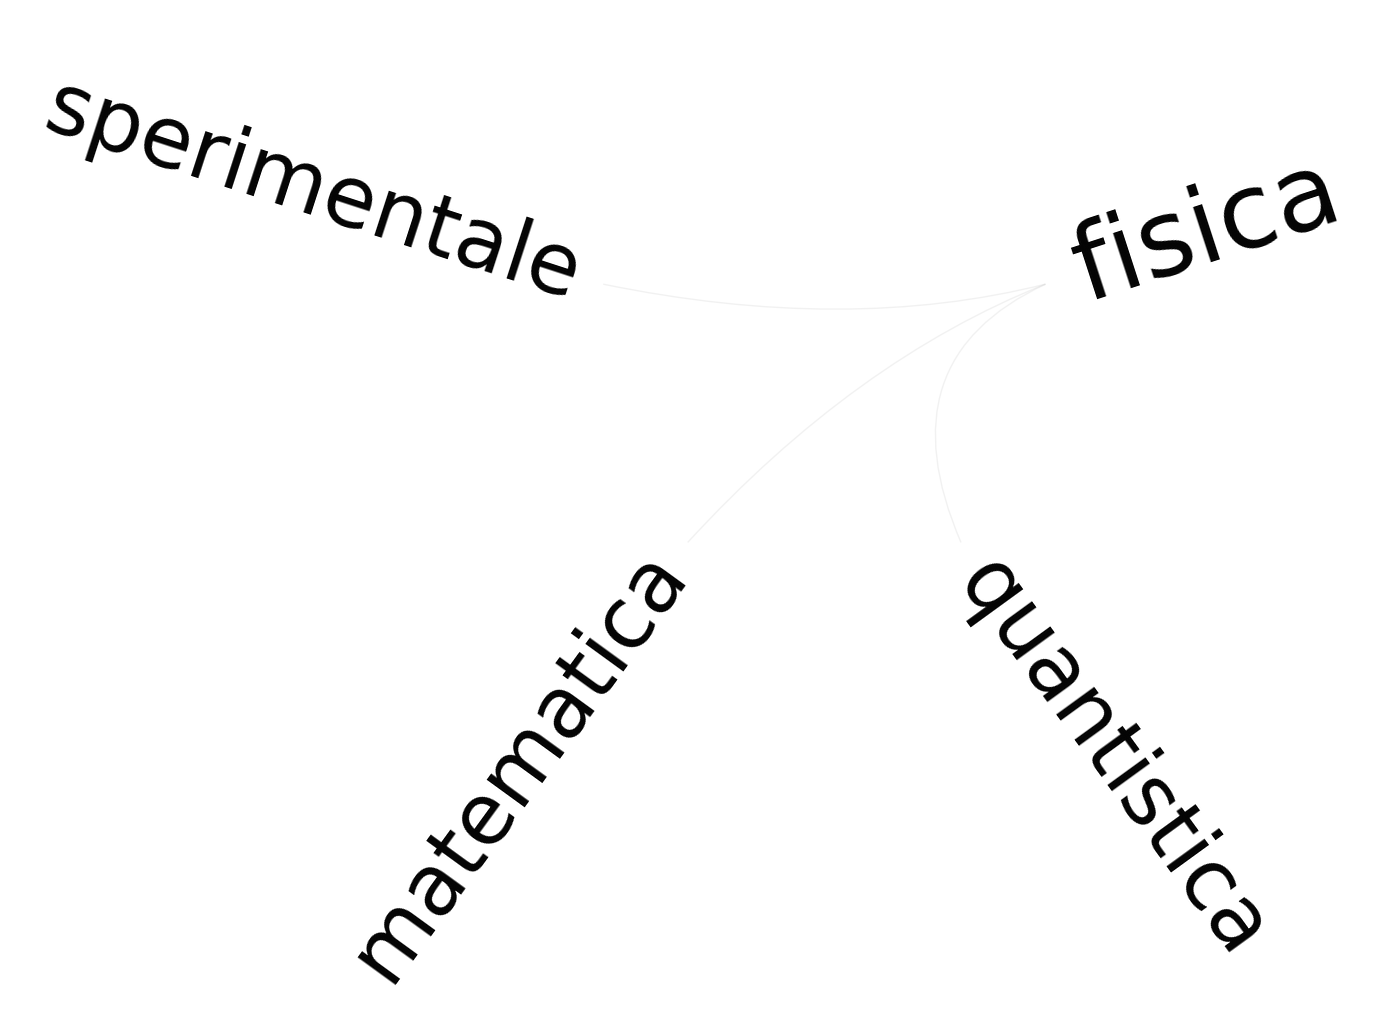

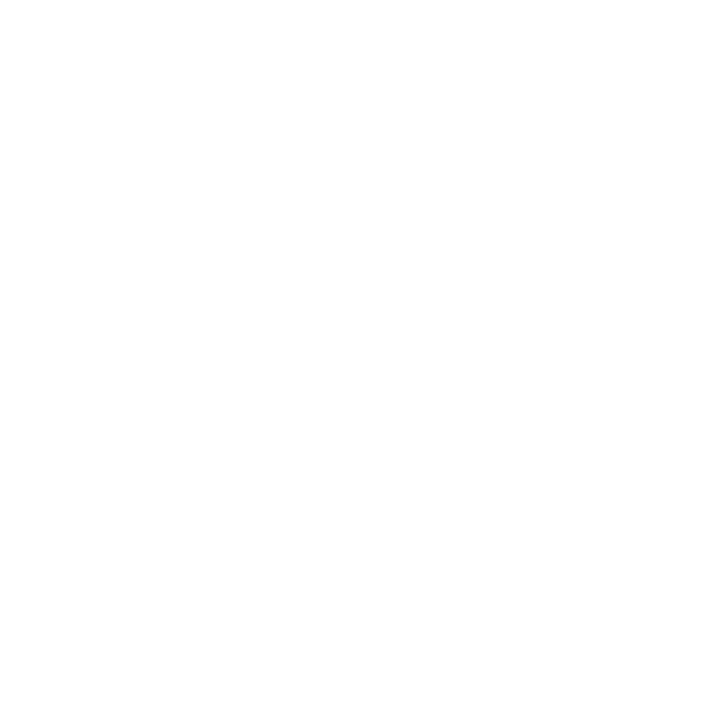

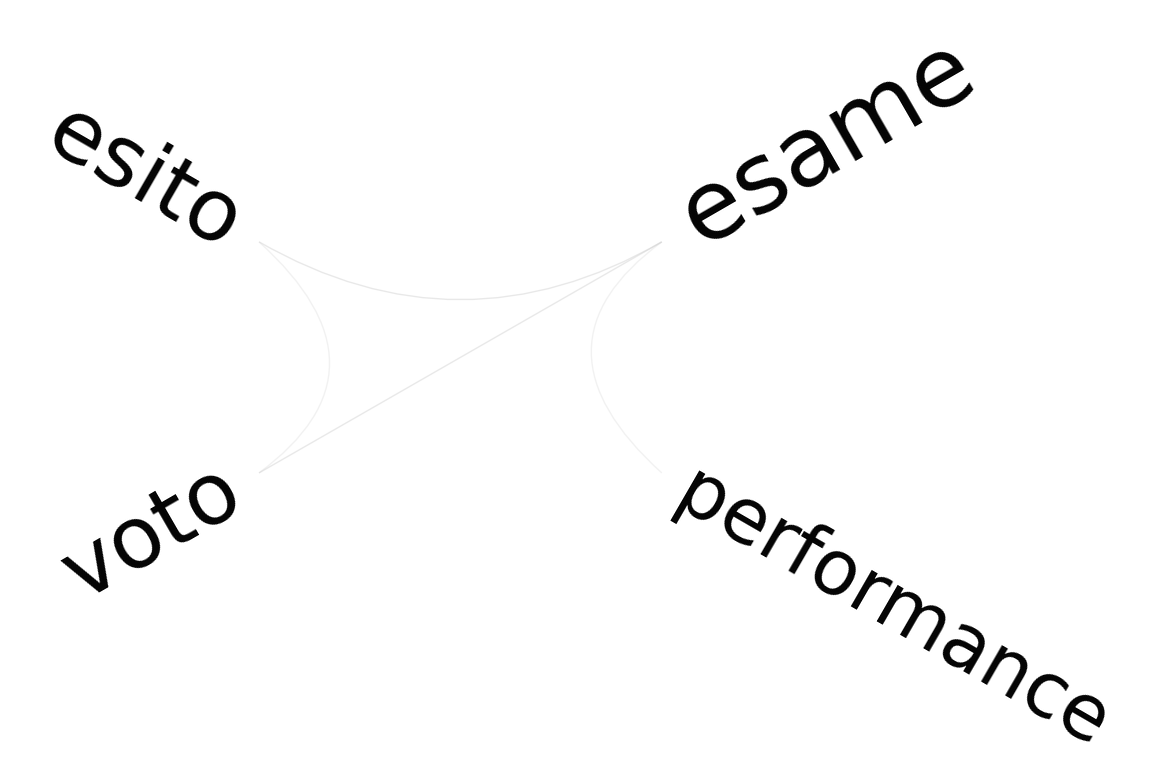

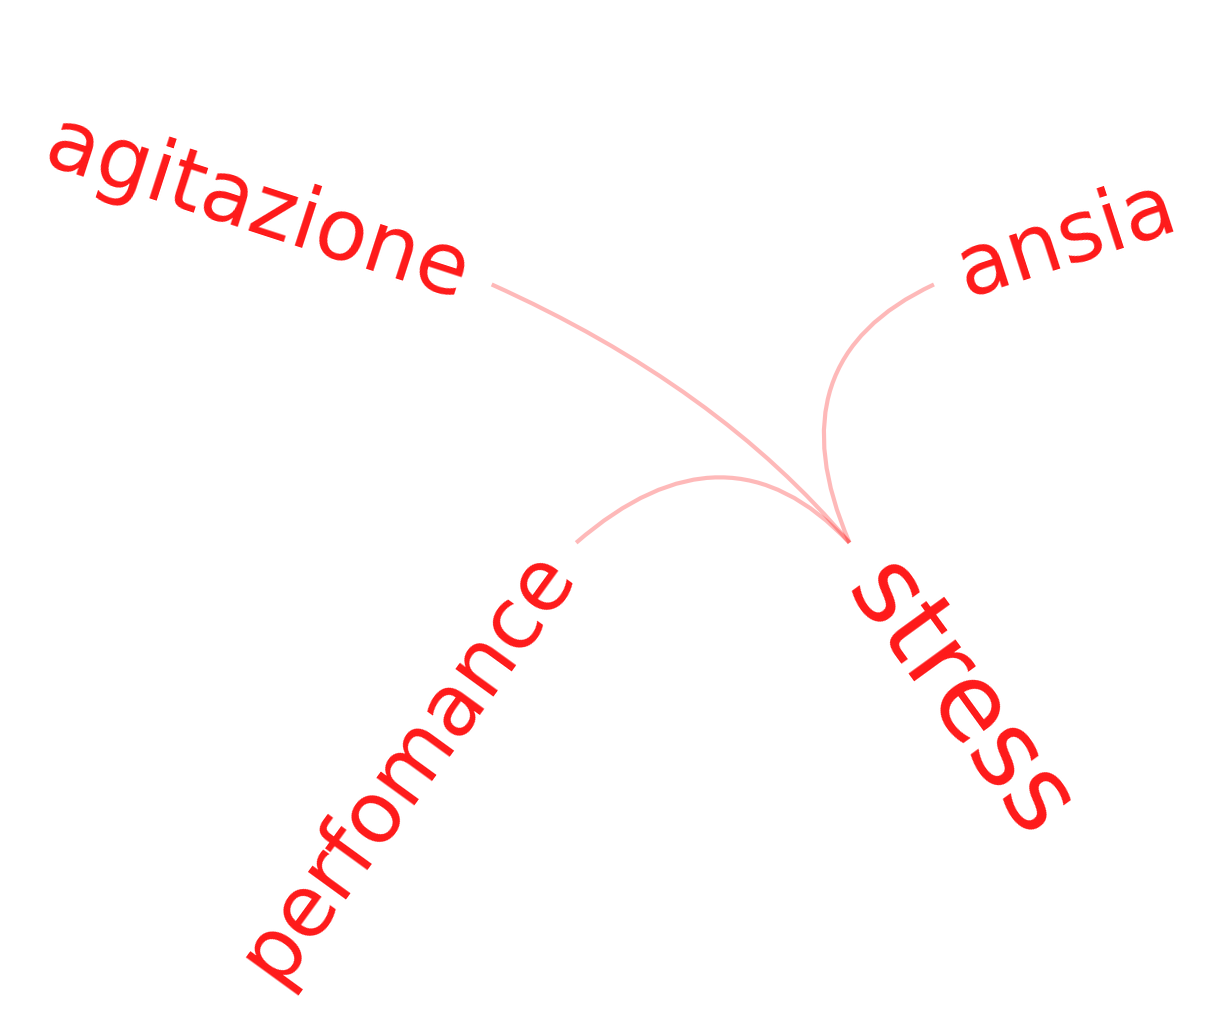

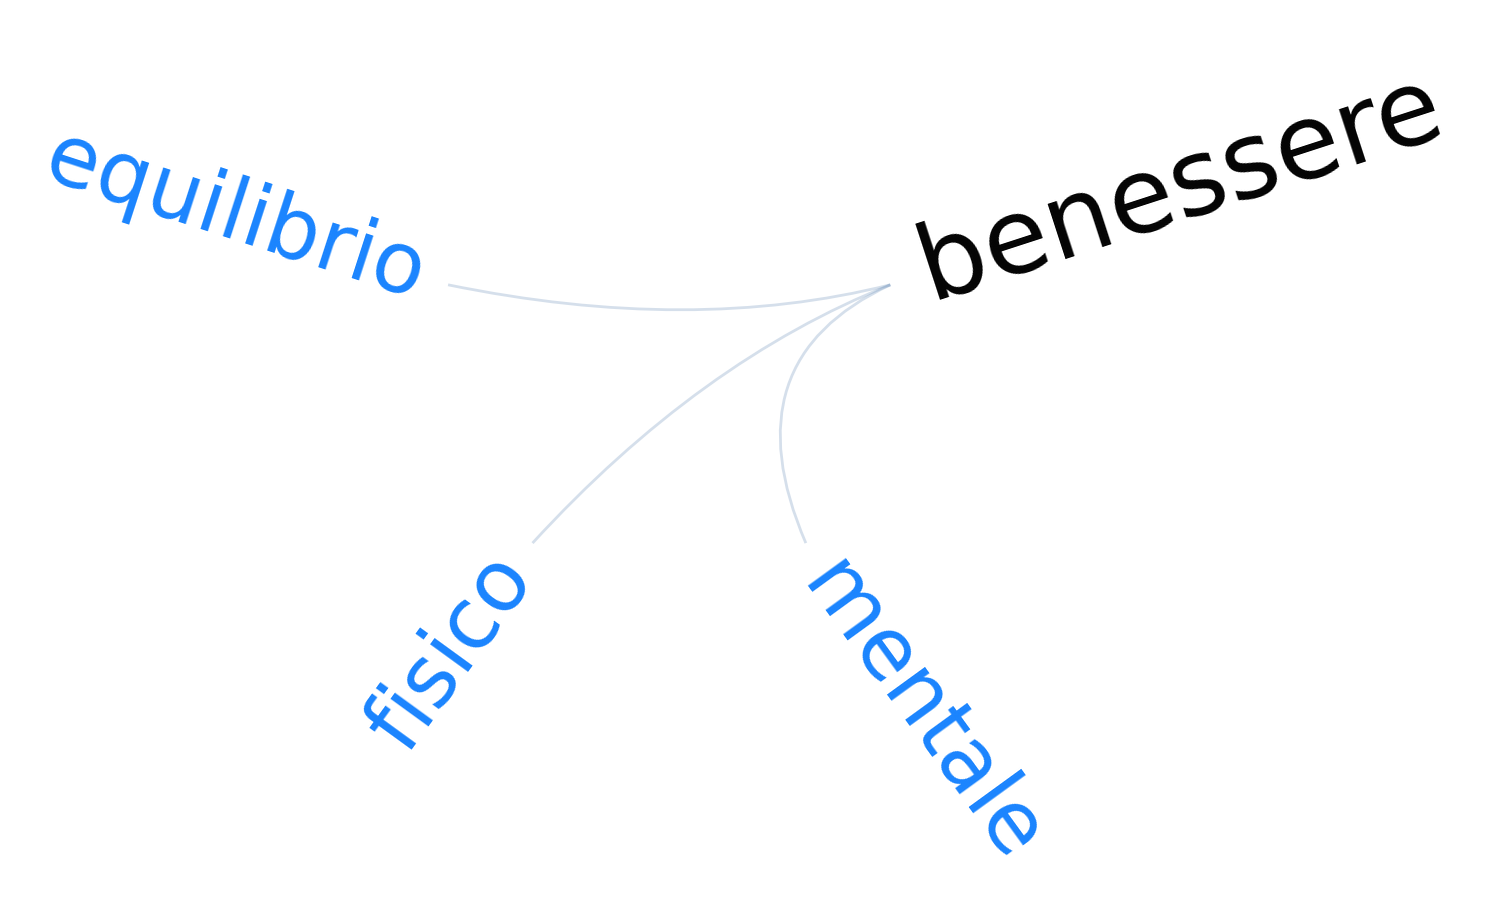

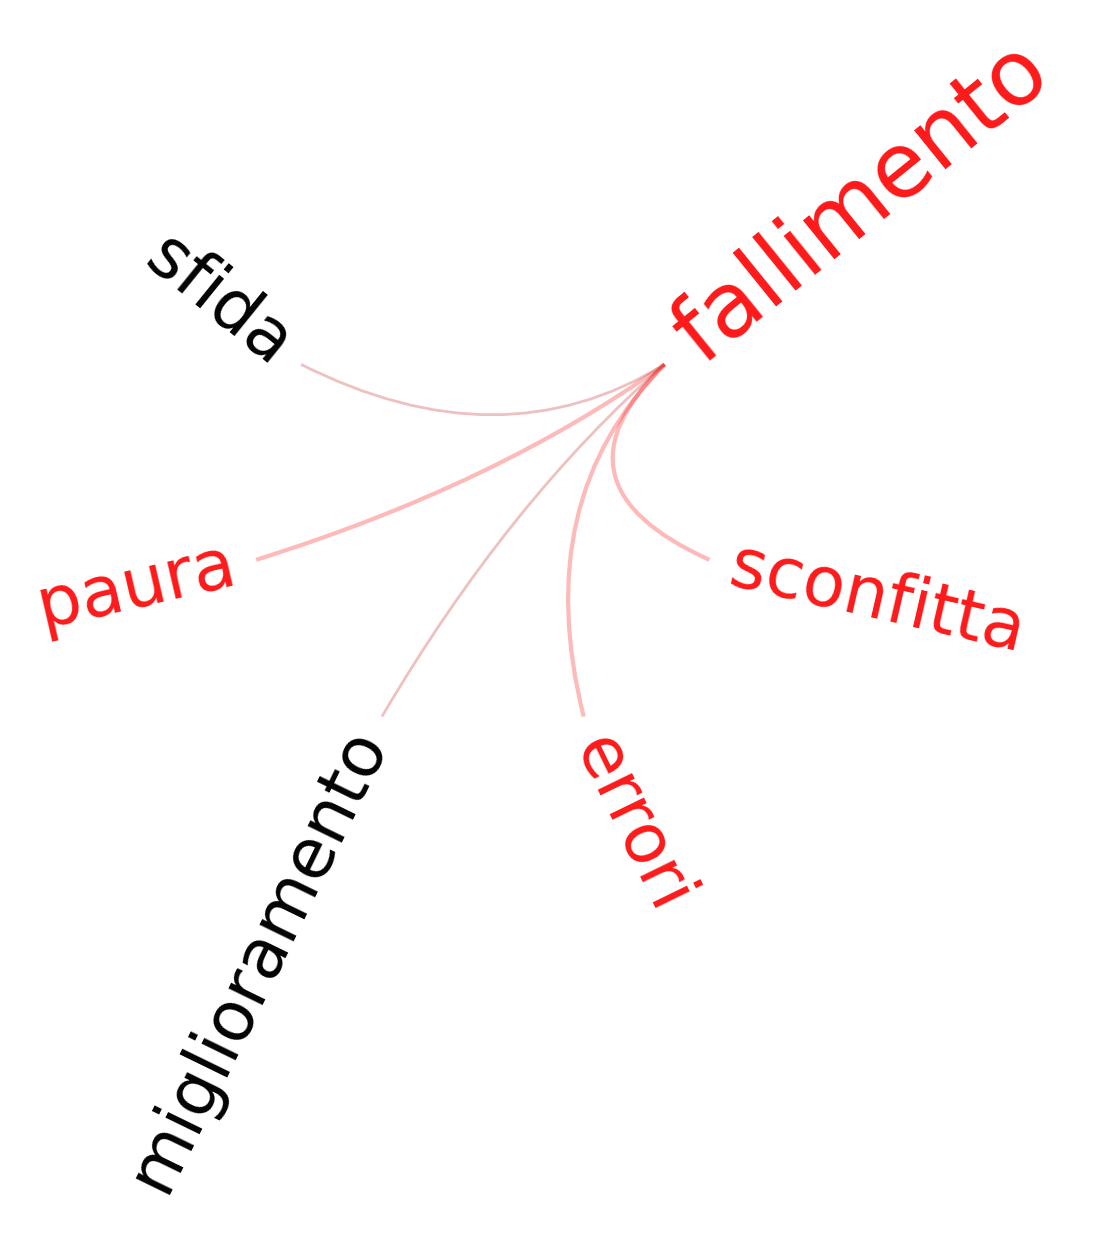

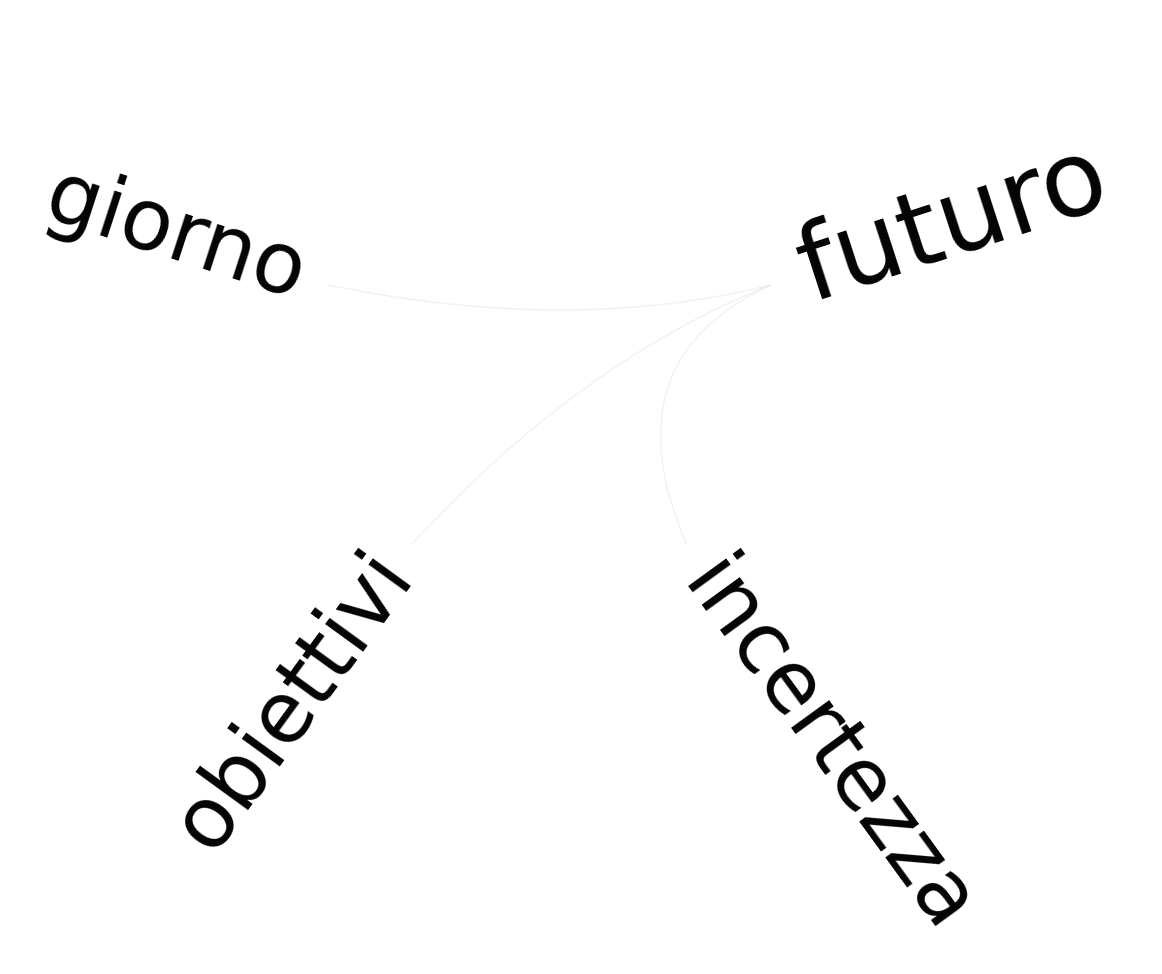

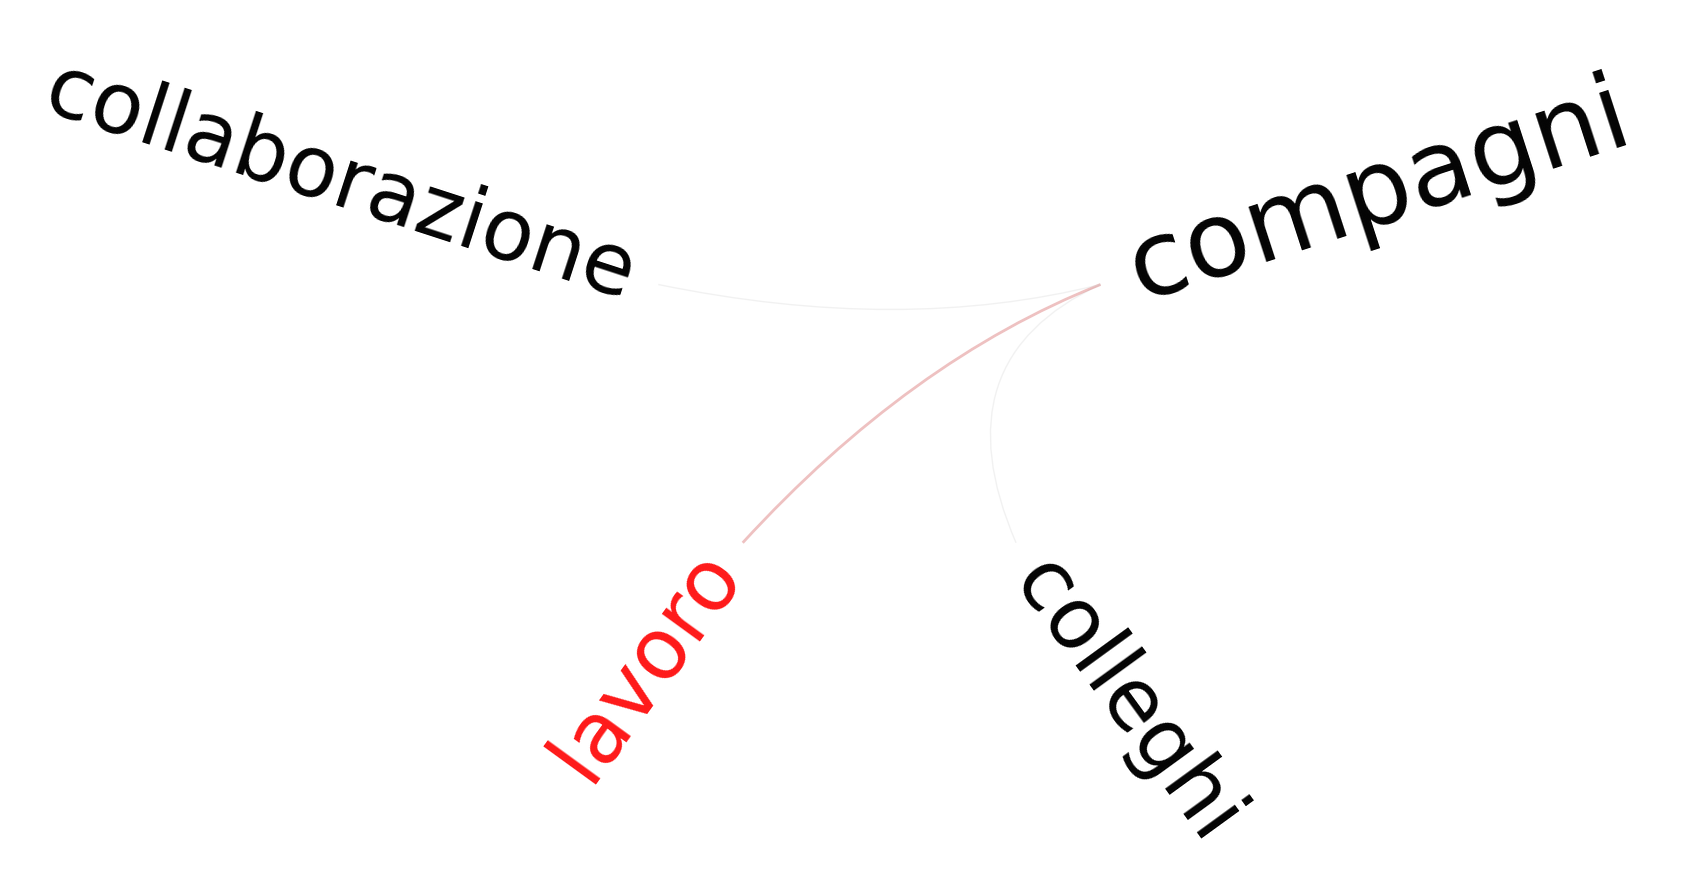

In [7]:
for id in ids_sessions:
    print(f'Processing participant: {id}')
    participant_data = stem_group_associations[stem_group_associations['participant_id'] == id]
    final_df, features_fmnt, valences = pipeline_single_participant(participant_data, keywords, out_folder, 'stem_group/single_bfmn', id)

## Multiple BFMN

Number of unique words: 498


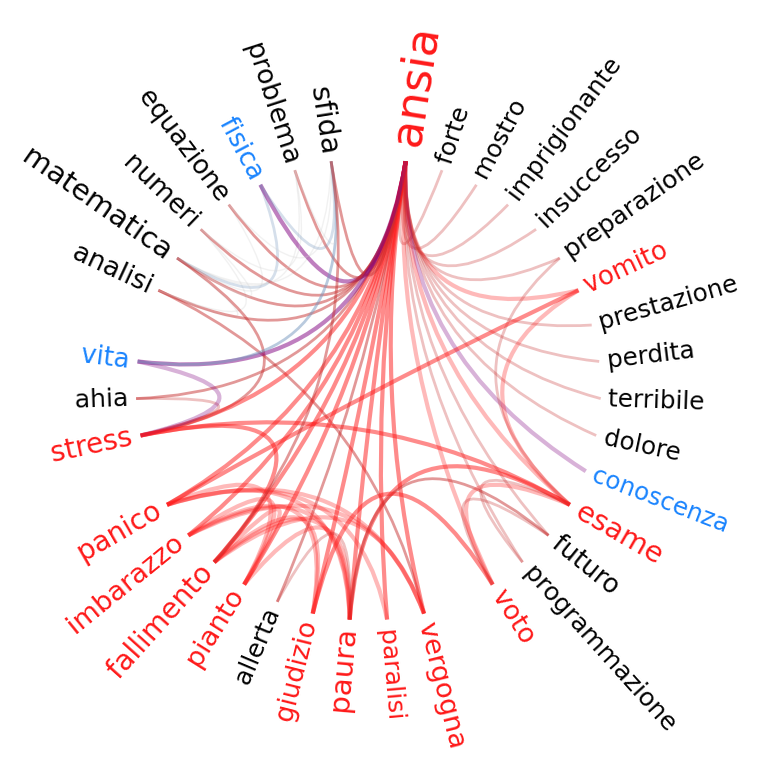

Local clustering ansia: 0.0748663101604278
Degree ansia: 34
Counts of 'ansia' = {'positive': 3, 'negative': 13, 'neutral': 19}
Mode of 'ansia' = neutral


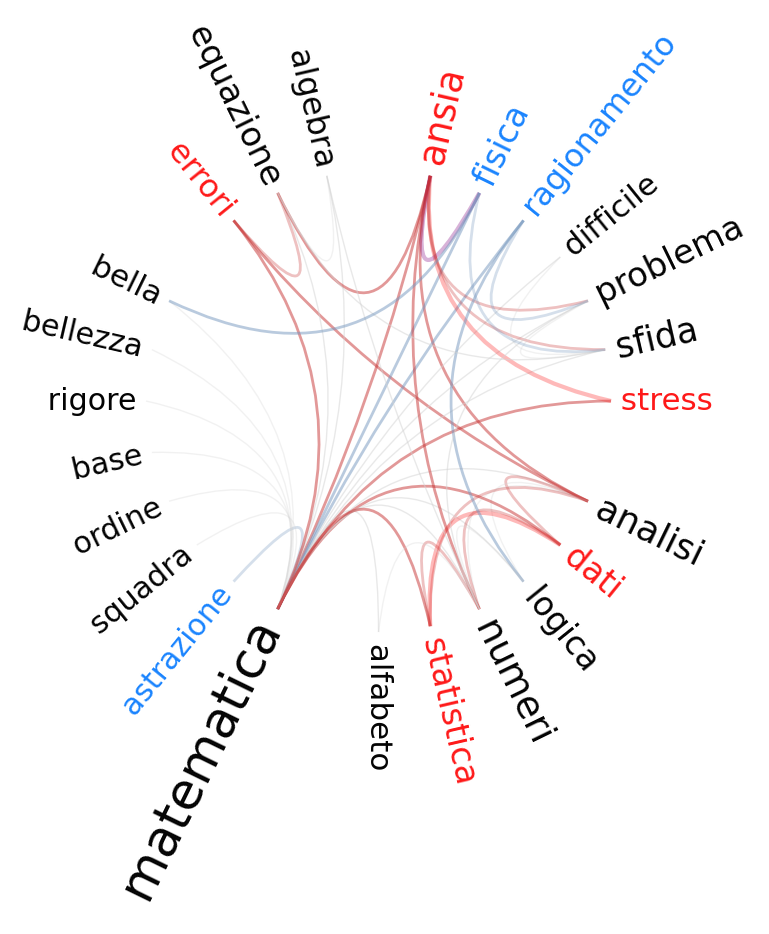

Local clustering matematica: 0.11067193675889328
Degree matematica: 23
Counts of 'matematica' = {'positive': 3, 'negative': 5, 'neutral': 16}
Mode of 'matematica' = neutral


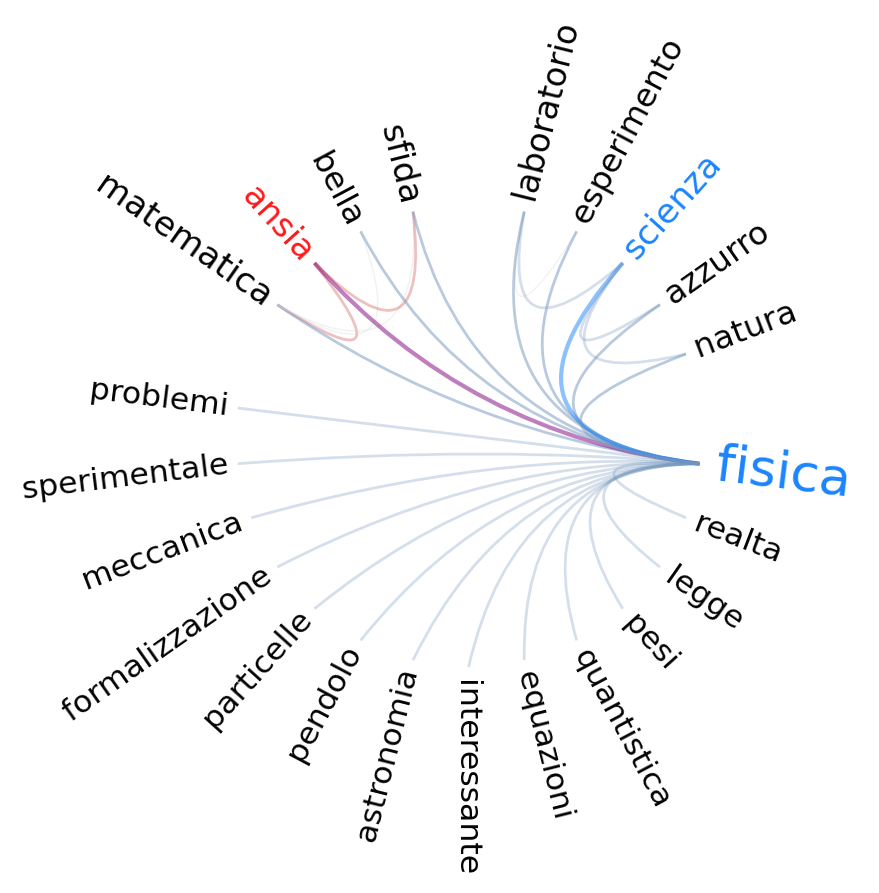

Local clustering fisica: 0.03463203463203463
Degree fisica: 22
Counts of 'fisica' = {'positive': 2, 'negative': 1, 'neutral': 20}
Mode of 'fisica' = neutral


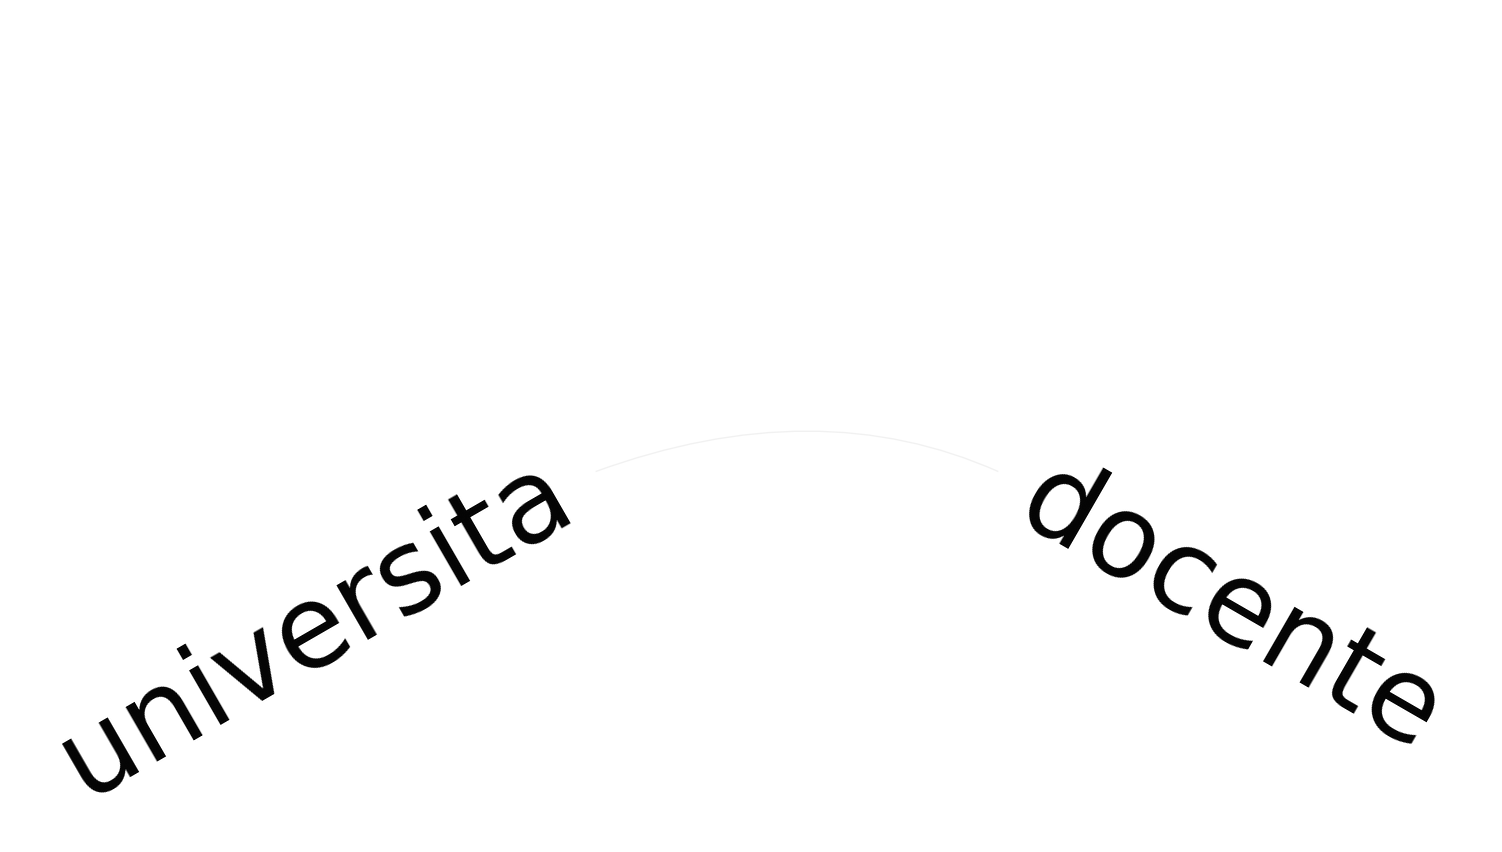

Local clustering universita: 0
Degree universita: 1
Counts of 'universita' = {'positive': 0, 'negative': 0, 'neutral': 2}
Mode of 'universita' = neutral


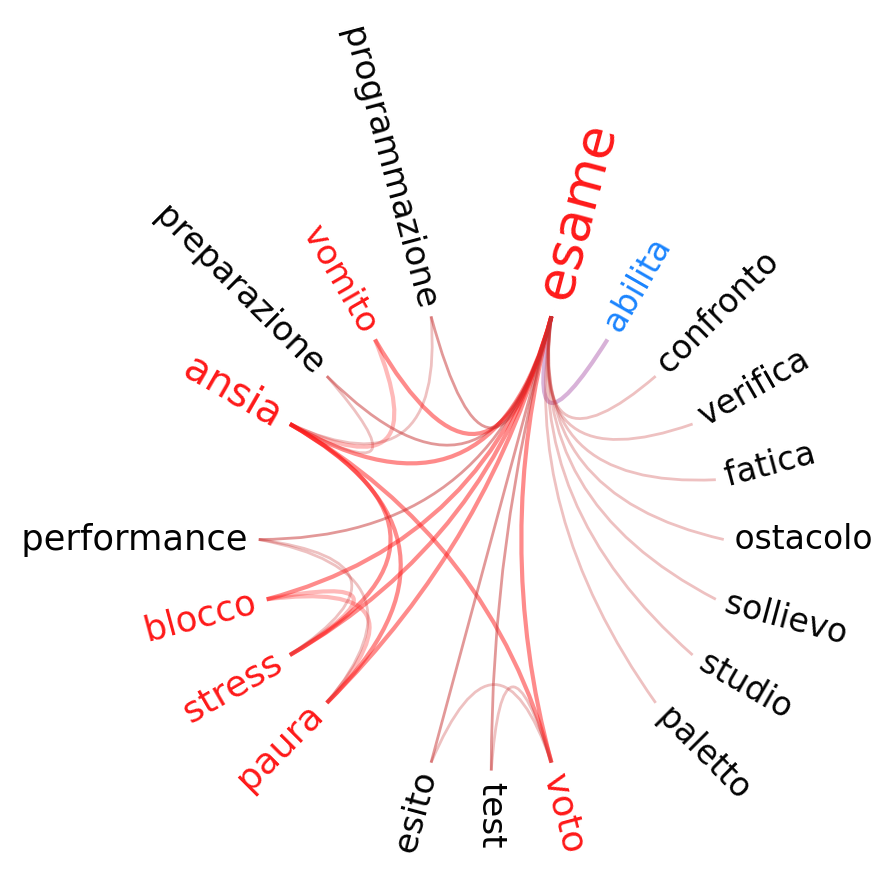

Local clustering esame: 0.07017543859649122
Degree esame: 19
Counts of 'esame' = {'positive': 1, 'negative': 7, 'neutral': 12}
Mode of 'esame' = neutral


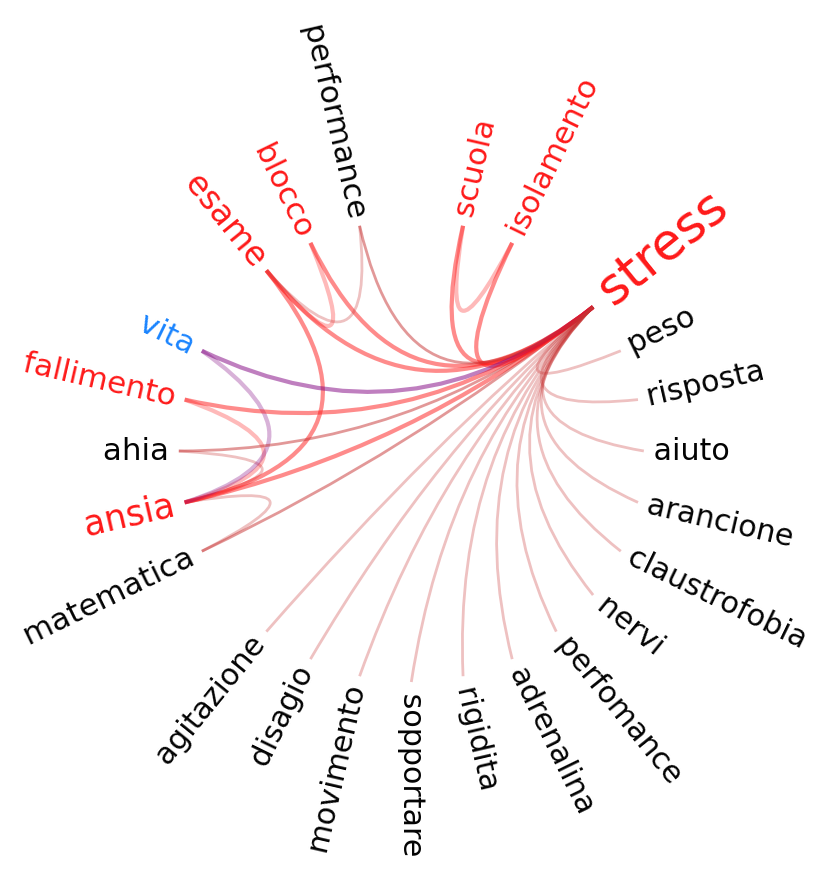

Local clustering stress: 0.03162055335968379
Degree stress: 23
Counts of 'stress' = {'positive': 1, 'negative': 7, 'neutral': 16}
Mode of 'stress' = neutral


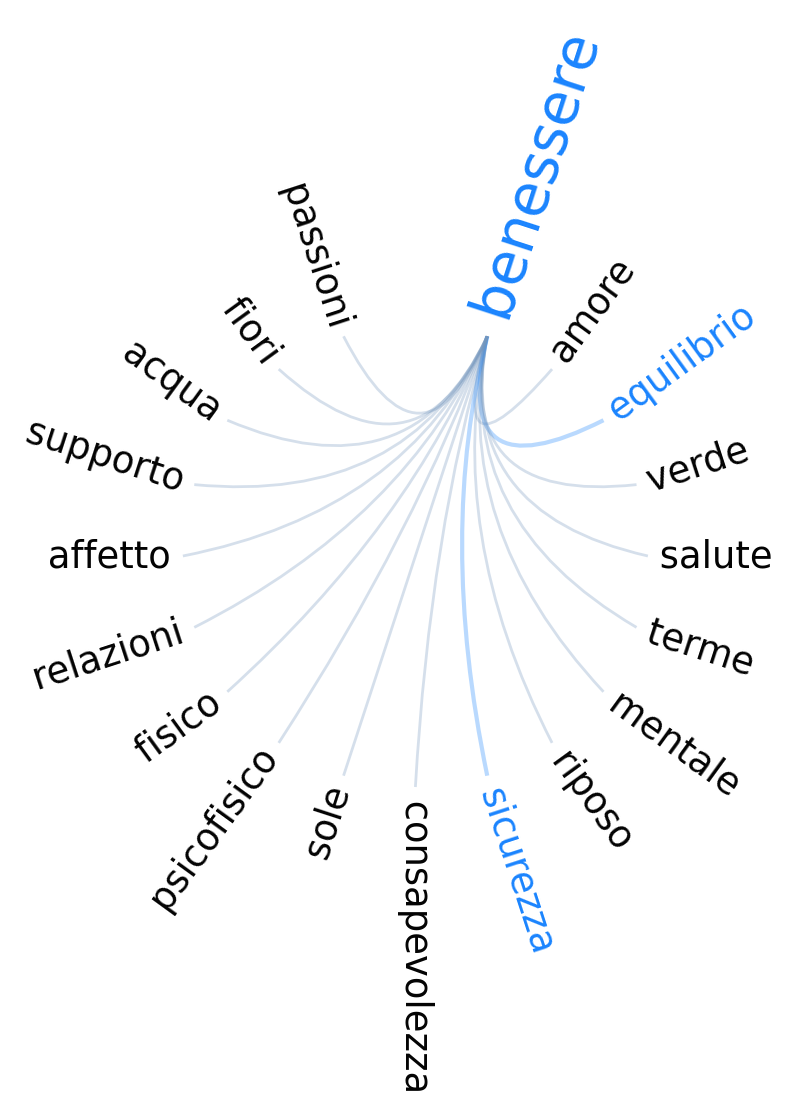

Local clustering benessere: 0
Degree benessere: 18
Counts of 'benessere' = {'positive': 3, 'negative': 0, 'neutral': 16}
Mode of 'benessere' = neutral


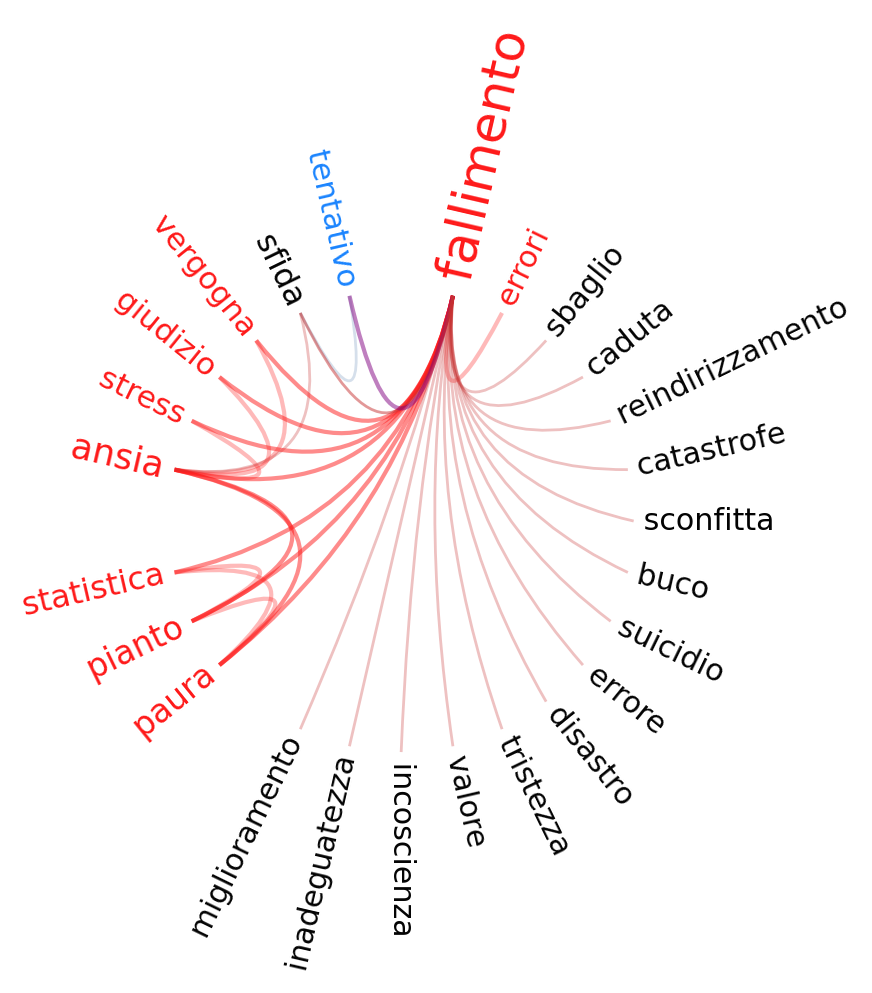

Local clustering fallimento: 0.036231884057971016
Degree fallimento: 24
Counts of 'fallimento' = {'positive': 1, 'negative': 9, 'neutral': 15}
Mode of 'fallimento' = neutral


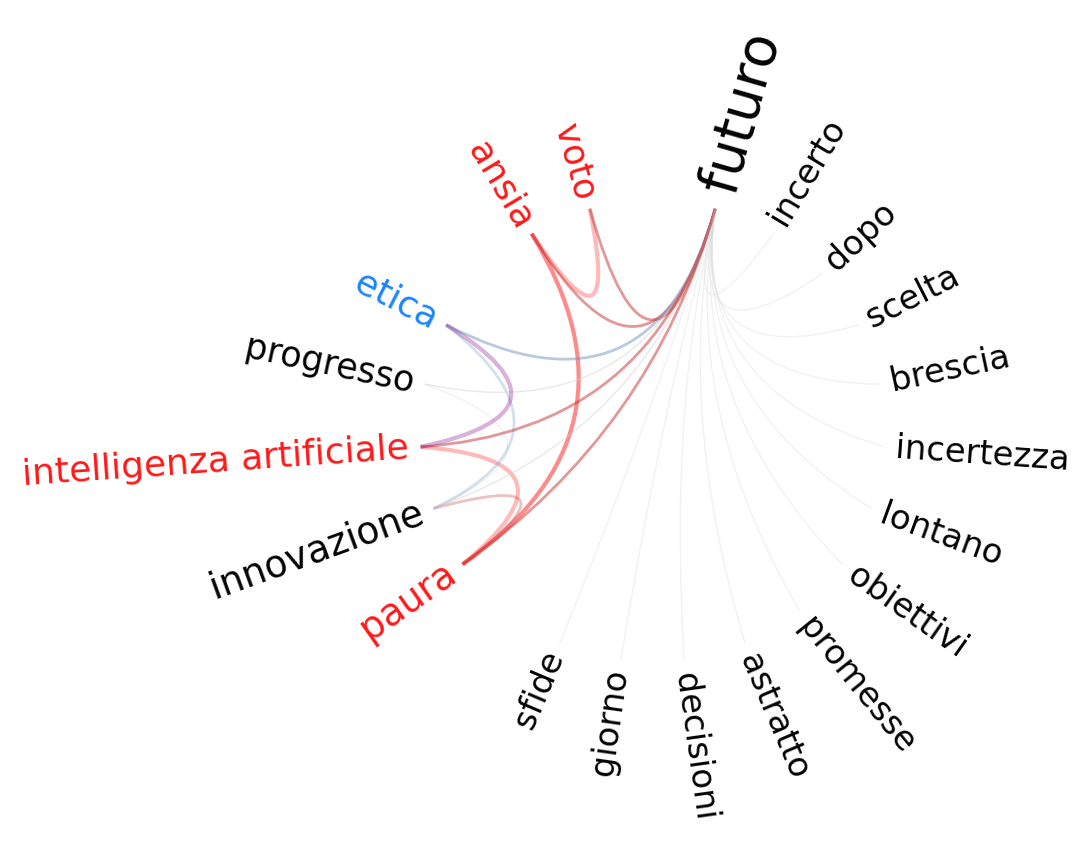

Local clustering futuro: 0.04093567251461988
Degree futuro: 19
Counts of 'futuro' = {'positive': 1, 'negative': 4, 'neutral': 15}
Mode of 'futuro' = neutral


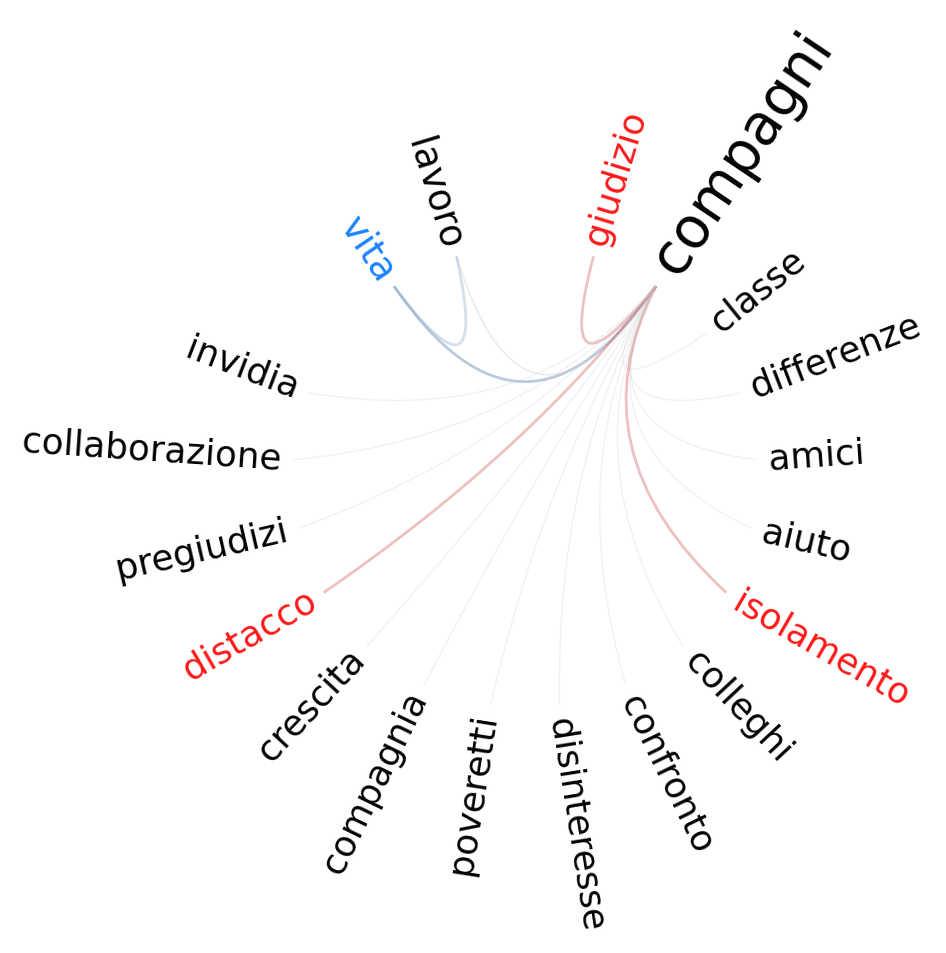

Local clustering compagni: 0.006535947712418301
Degree compagni: 18
Counts of 'compagni' = {'positive': 1, 'negative': 3, 'neutral': 15}
Mode of 'compagni' = neutral


In [8]:
features = pipeline_multiple_participants(stem_group_associations, keywords, '/Users/emma/projects/cognoscolab/rassereno', 'stem_group/multiple_bfmn', flower=False)

# TFMN building

In [9]:
all_students_2025_free_text = pd.read_csv(f'{out_folder}/formatting/all_students_2025/free_text.csv')

stem_group_free_text = all_students_2025_free_text[all_students_2025_free_text['participant_id'].str.startswith('fisica_stem')]

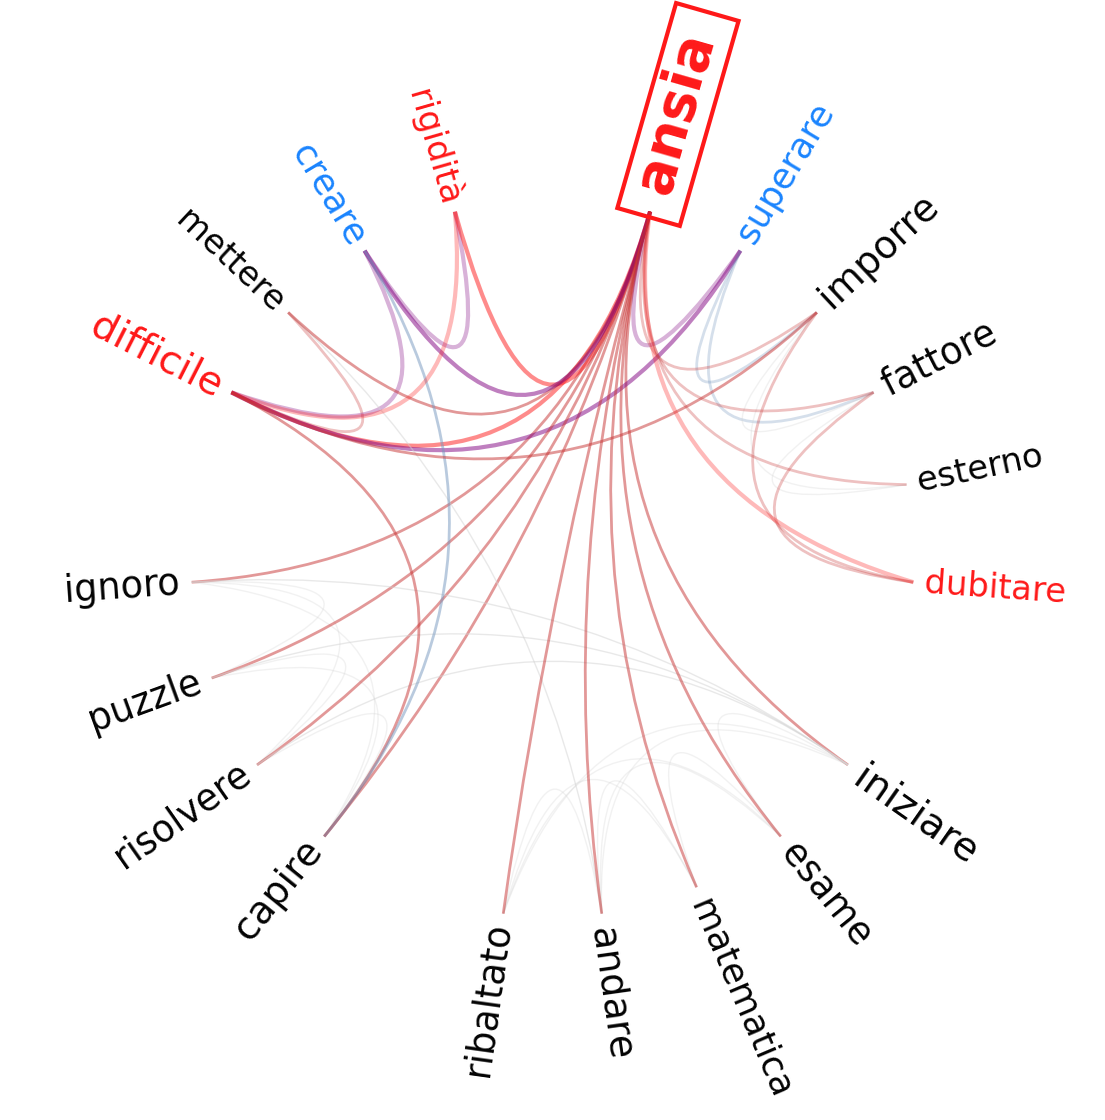

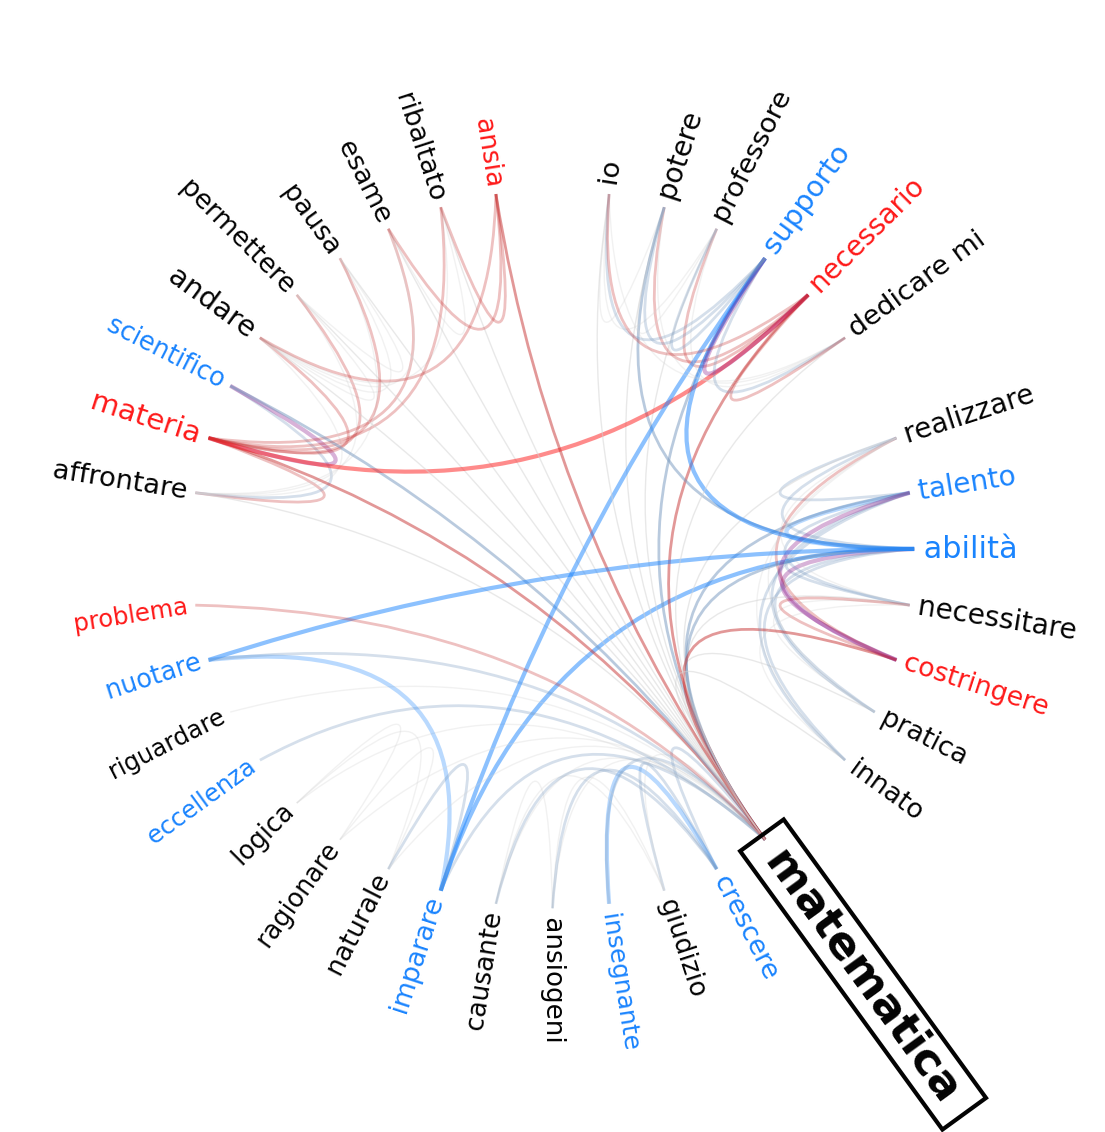

⚠️ Skipping 'fisica' of stem_group sample: not enough data to build the network.
⚠️ Skipping 'universita' of stem_group sample: not enough data to build the network.


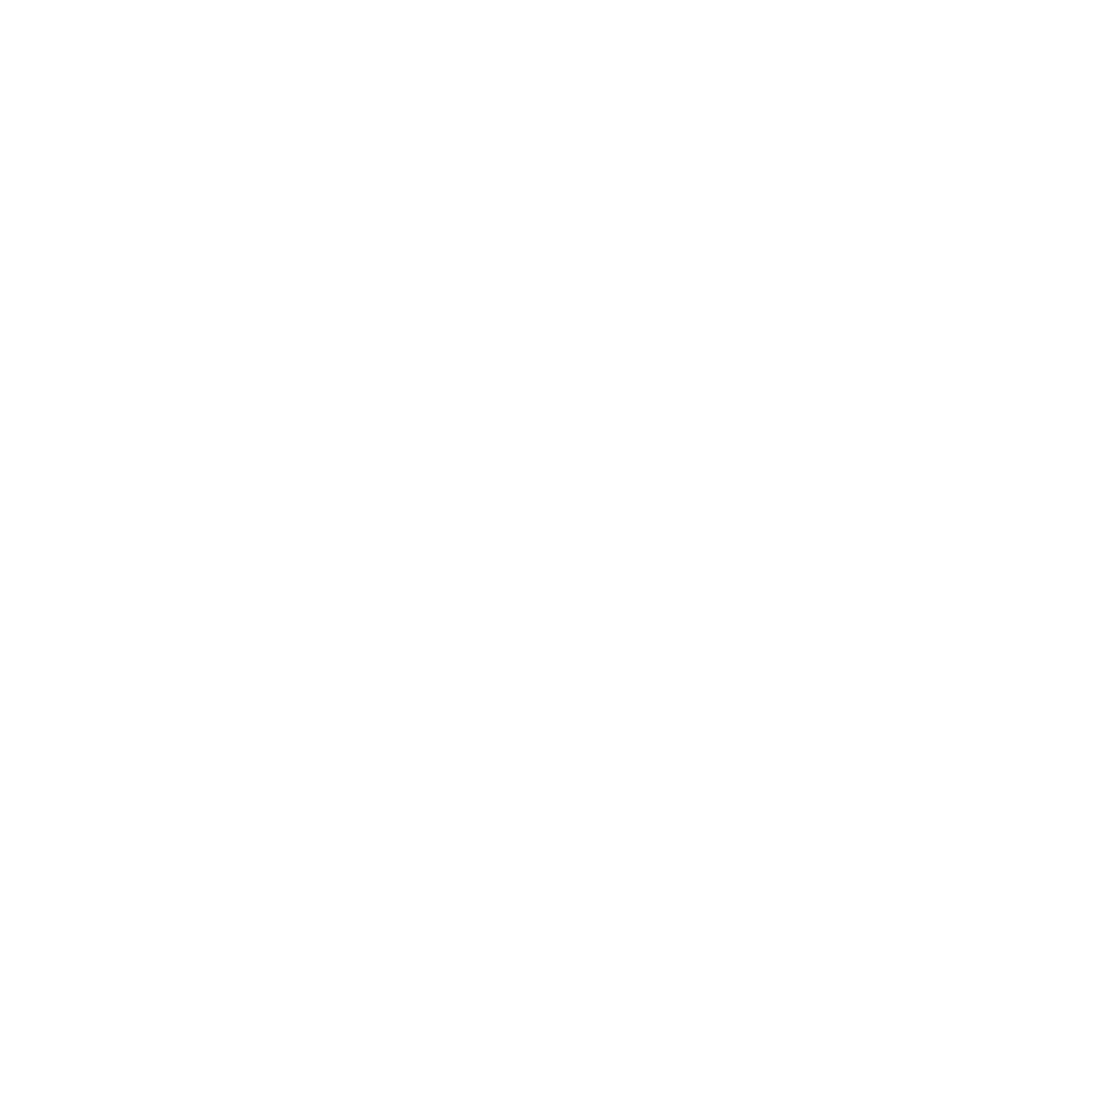

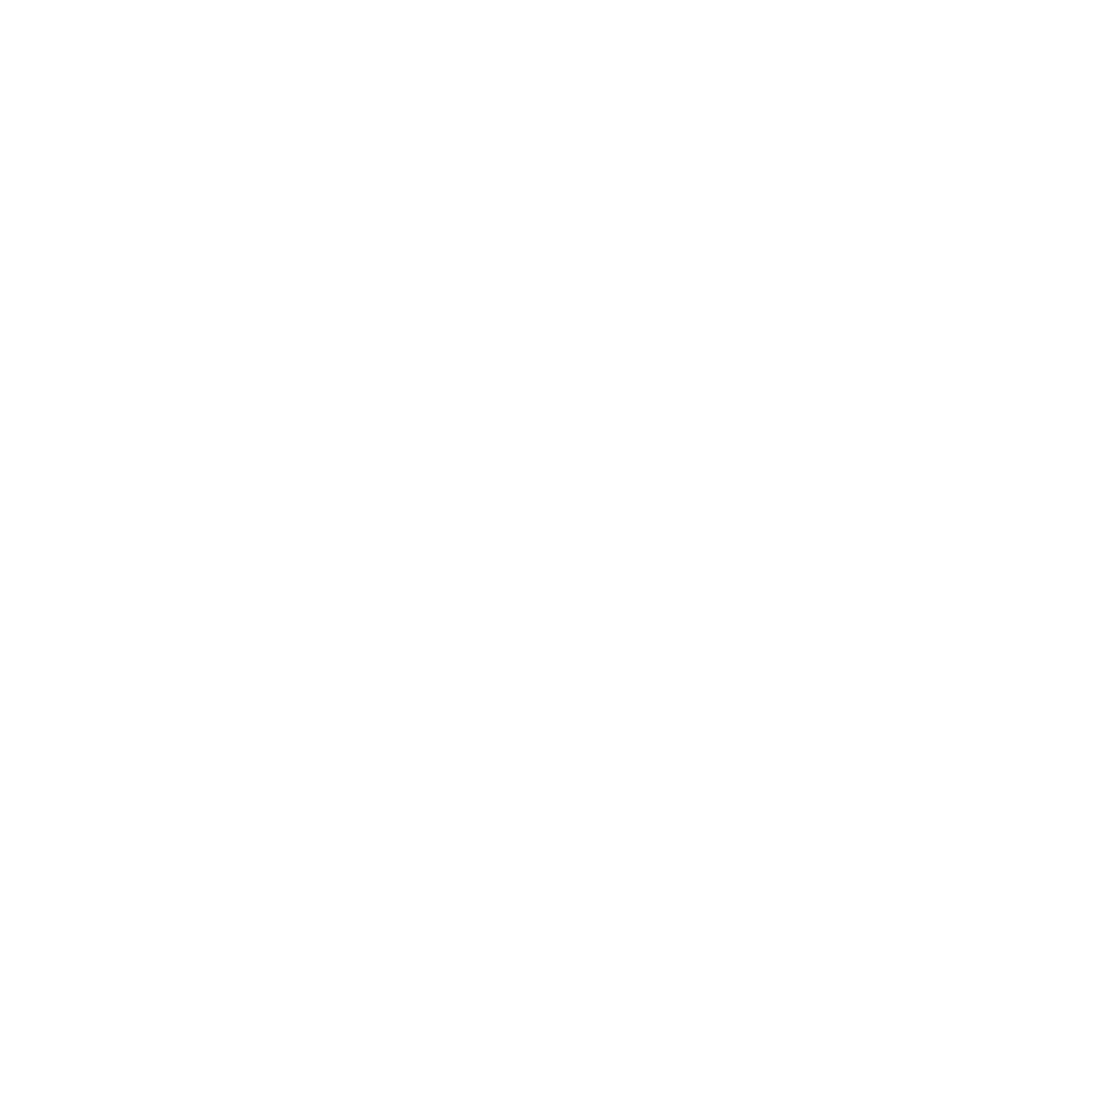

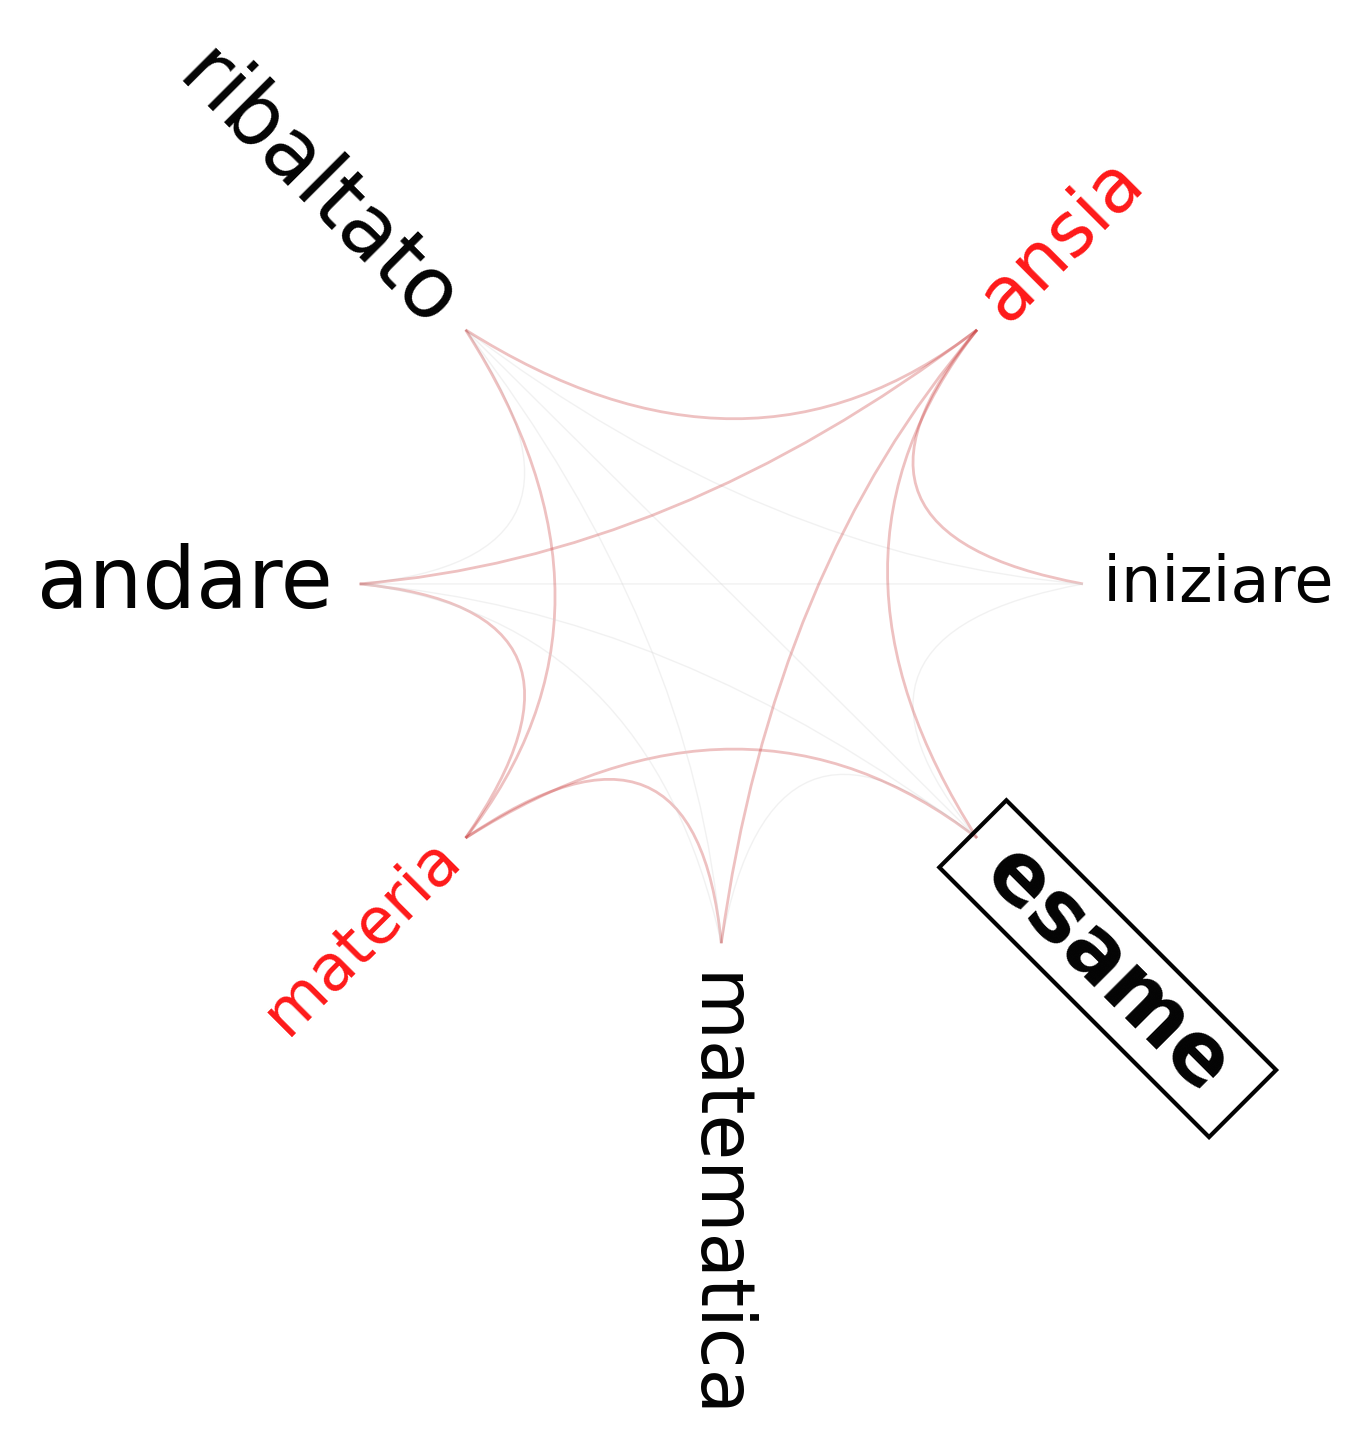

⚠️ Skipping 'stress' of stem_group sample: not enough data to build the network.
⚠️ Skipping 'benessere' of stem_group sample: not enough data to build the network.
⚠️ Skipping 'fallimento' of stem_group sample: not enough data to build the network.
⚠️ Skipping 'futuro' of stem_group sample: not enough data to build the network.
⚠️ Skipping 'compagni' of stem_group sample: not enough data to build the network.


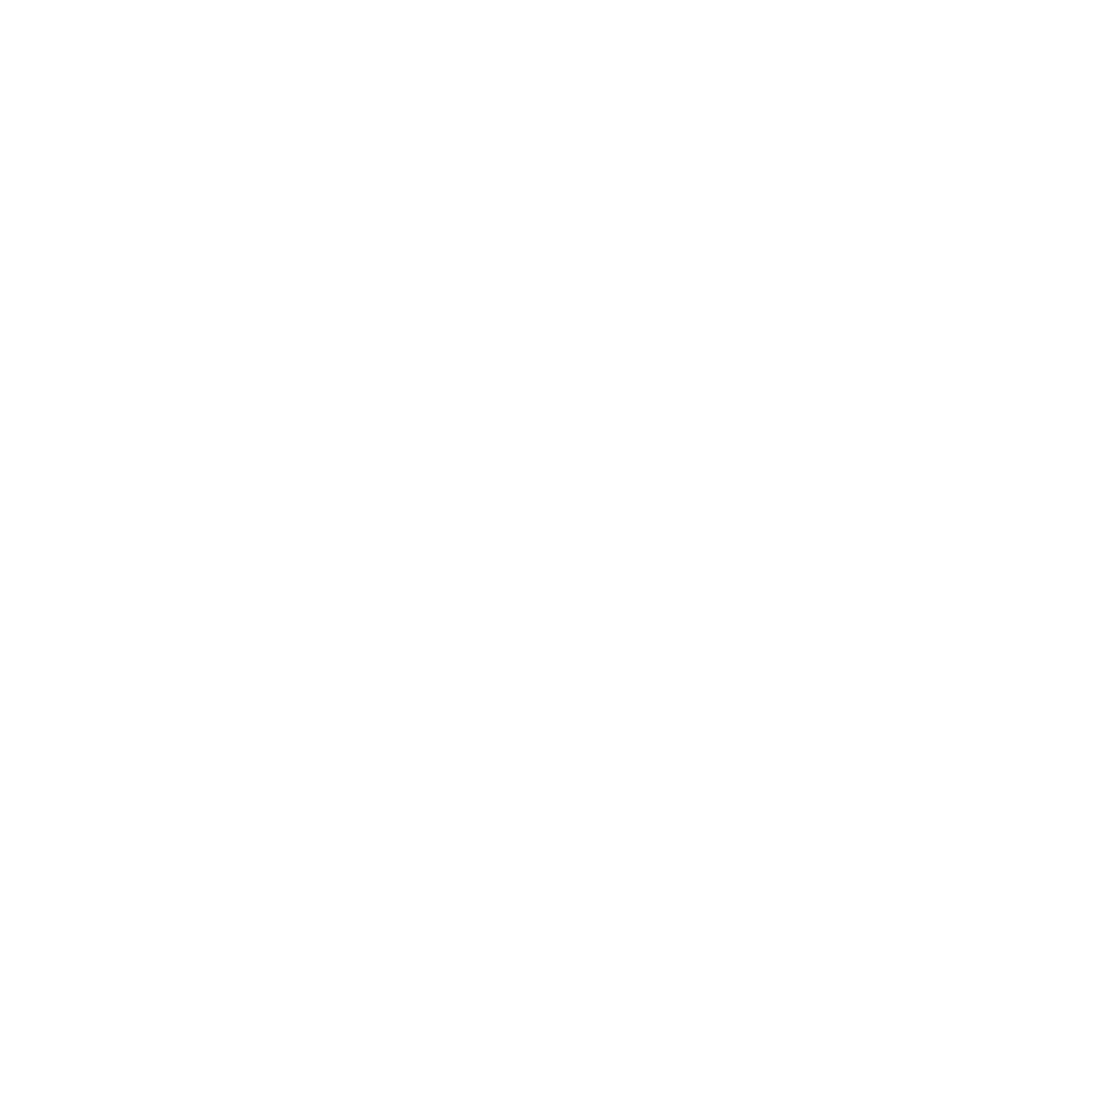

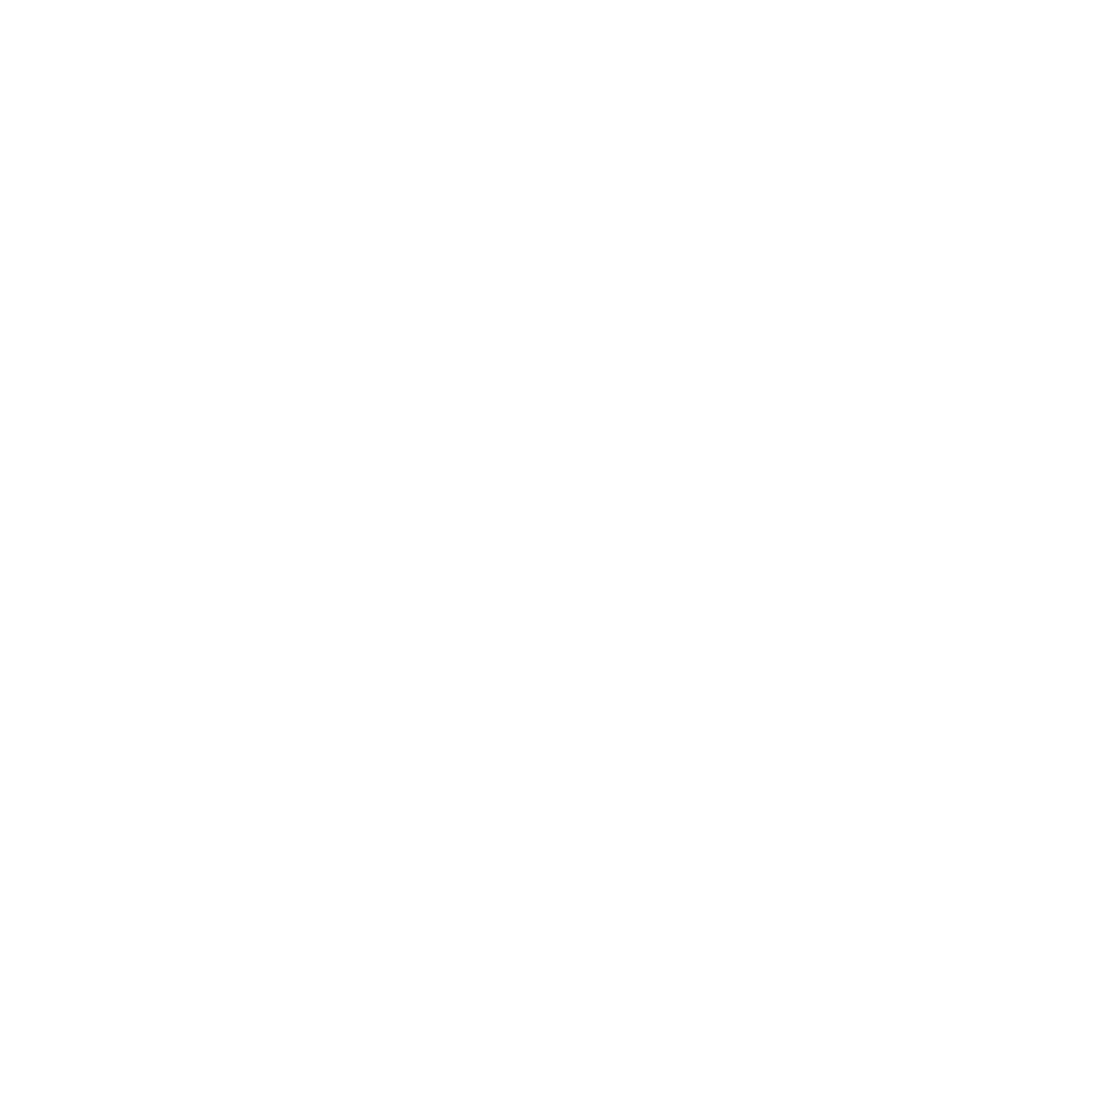

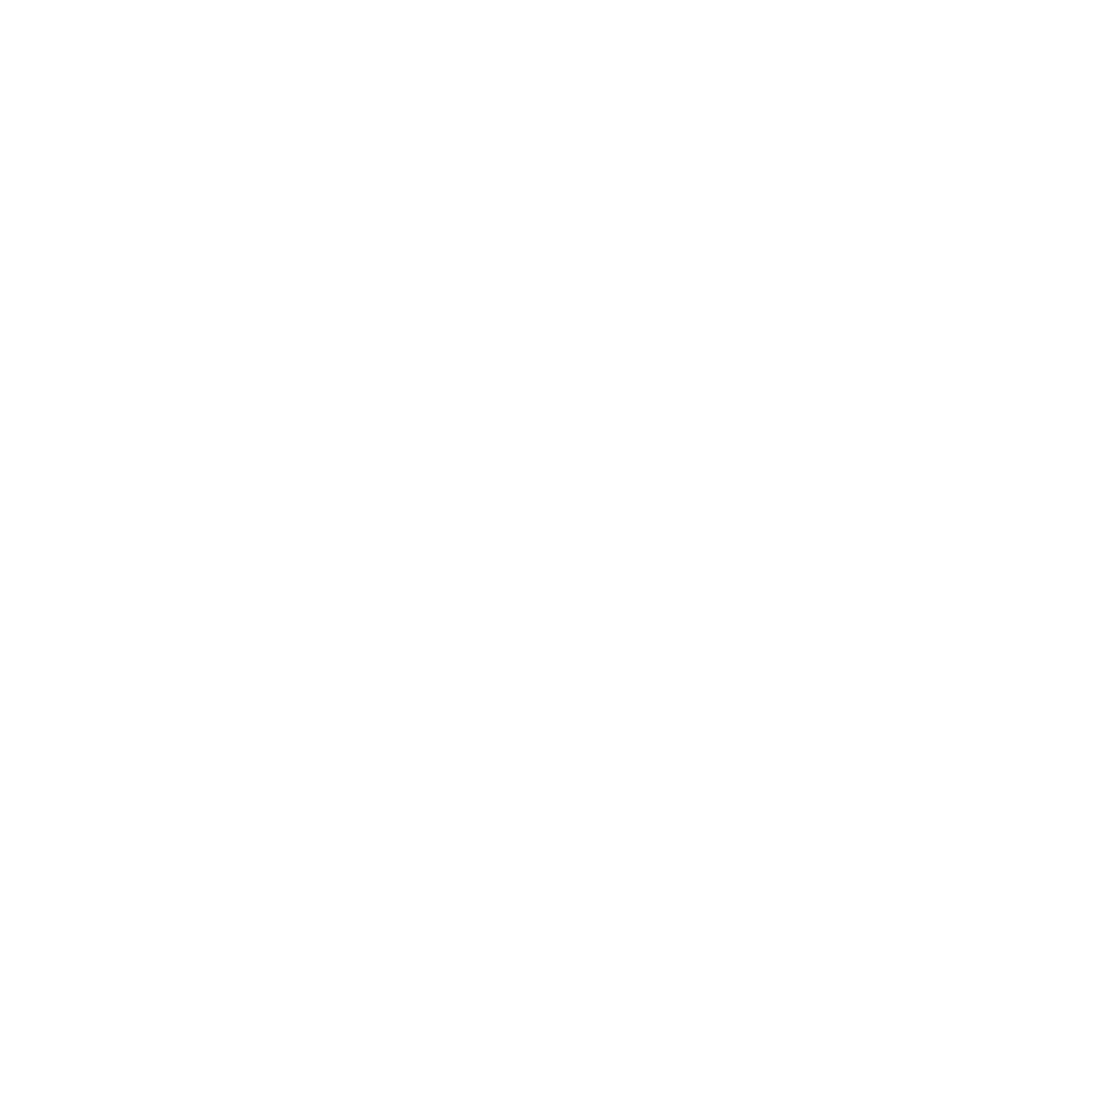

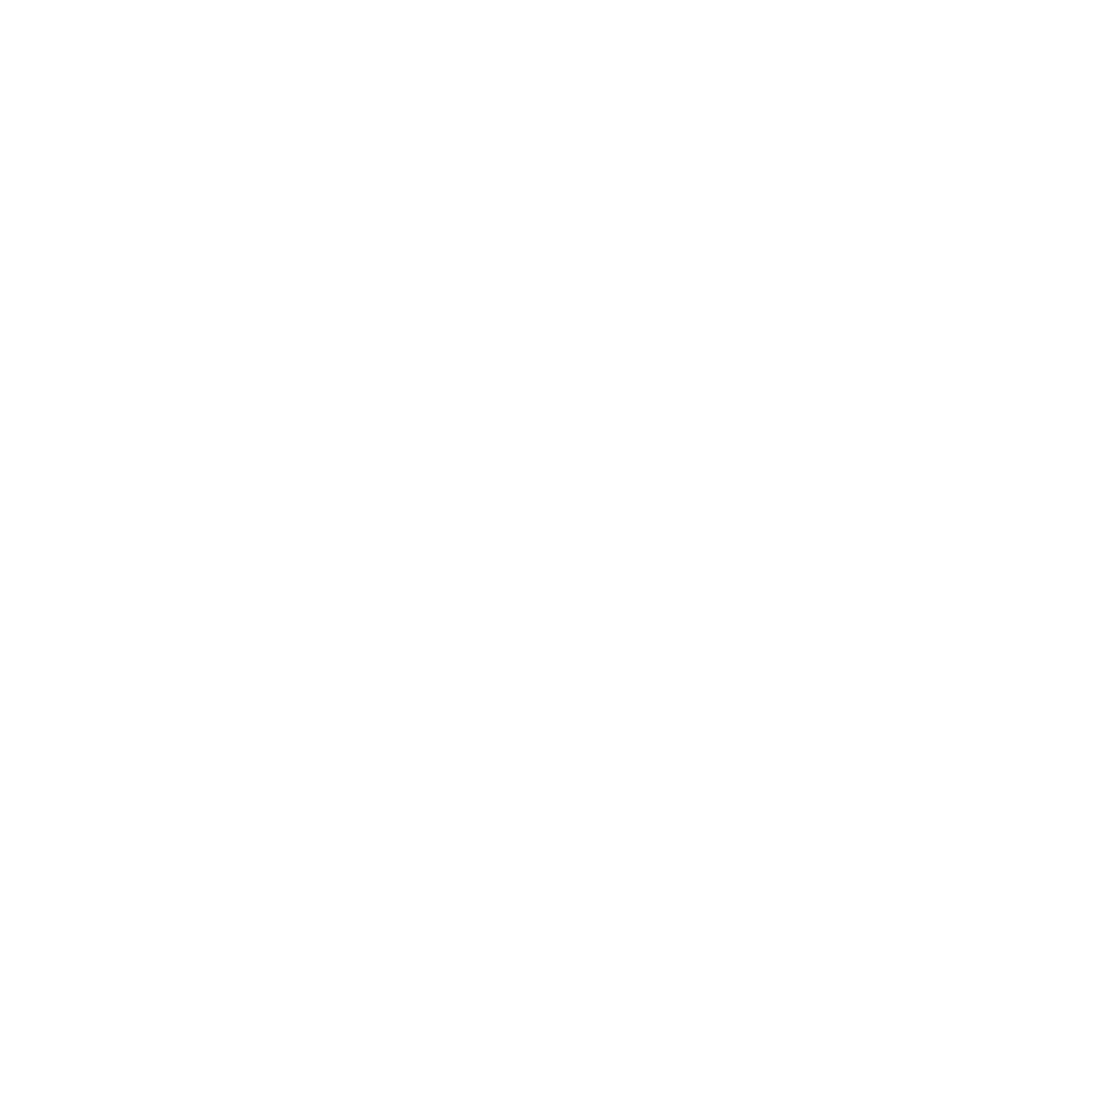

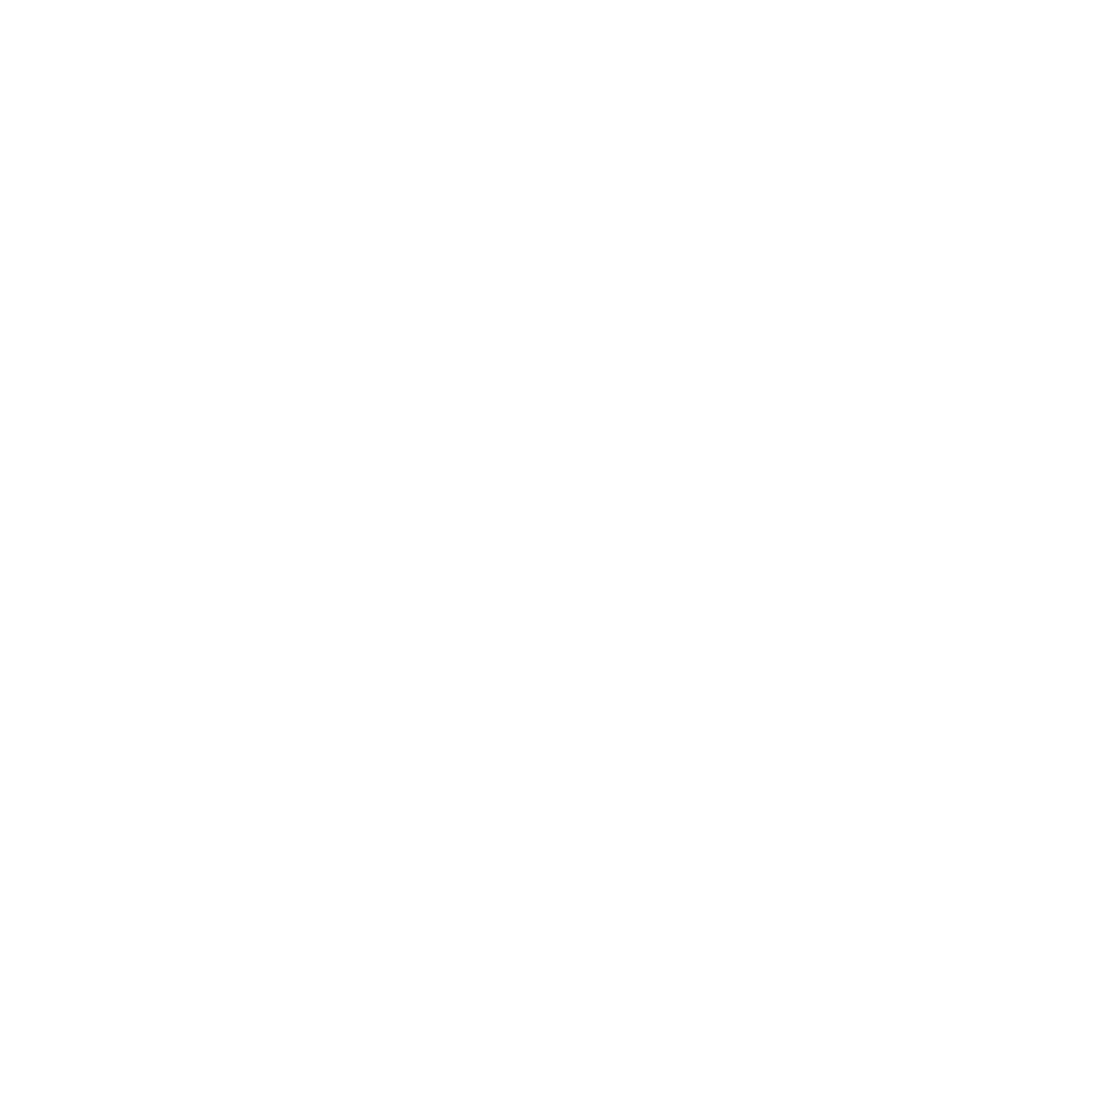

In [10]:
tfmn_buiding(stem_group_free_text, keywords, '/Users/emma/projects/cognoscolab/rassereno', 'stem_group', flower='no')

# Questionnaires

## MAS-IT 

In [11]:
physics_mas_it = pd.read_csv(f'{out_folder}/formatting/physics_2025/mas_it_fisica_2025.csv')

# selazionare solo i partecipanti del gruppo STEM
stem_group_mas_it = physics_mas_it[physics_mas_it['participant_id'].str.startswith('fisica_stem')]

In [12]:
# mas_it factors, without the reduntant and unstable ones (MAS-IT questionnaire)
mas_factor_1 = [1, 4, 5, 7, 8, 11, 12, 13, 14]				
mas_factor_2 = [3, 6, 9]				
mas_factor_3 = [18, 19, 20, 21, 22]

mas_factors  = [mas_factor_1, mas_factor_2, mas_factor_3]
# create a df with the scores of each factor
mas_factors_list_df = factor_grouping(mas_factors, stem_group_mas_it, 'mas_it', agg = "list").reset_index(drop=True)

# make labels based on the pre or post sessions
mas_factors_list_df['session'] = np.where(stem_group_mas_it['participant_id'].str.endswith('1'),'pre','post')

mas_factors_long_df = mas_factors_list_df.melt(id_vars='session', var_name='factor', value_name='score')

mas_factors_long_df = mas_factors_long_df.explode('score')

In [13]:
def pvalues_annotations(ax, df = pd.DataFrame(), var1 = str, var2 = str, test='Kruskal', alpha=0.05):
    n_questionnaire = df[var1].unique()
    factors = df[var2].unique()

    pairs = [((factor, n_questionnaire[0]), (factor, n_questionnaire[1])) for factor in factors]

    annotator = Annotator(
        ax,
        pairs=pairs,
        data=df,
        x=var2, 
        y="score", 
        hue=var1
    )

    annotator.configure(test=test, loc='inside', hide_non_significant=True)
    
    annotator.apply_test()
    annotator.annotate()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

mas_it_factor_1_pre vs. mas_it_factor_1_post: Kruskal-Wallis independent samples (pairwise between groups), P_val:2.795e-02 Stat=4.831e+00


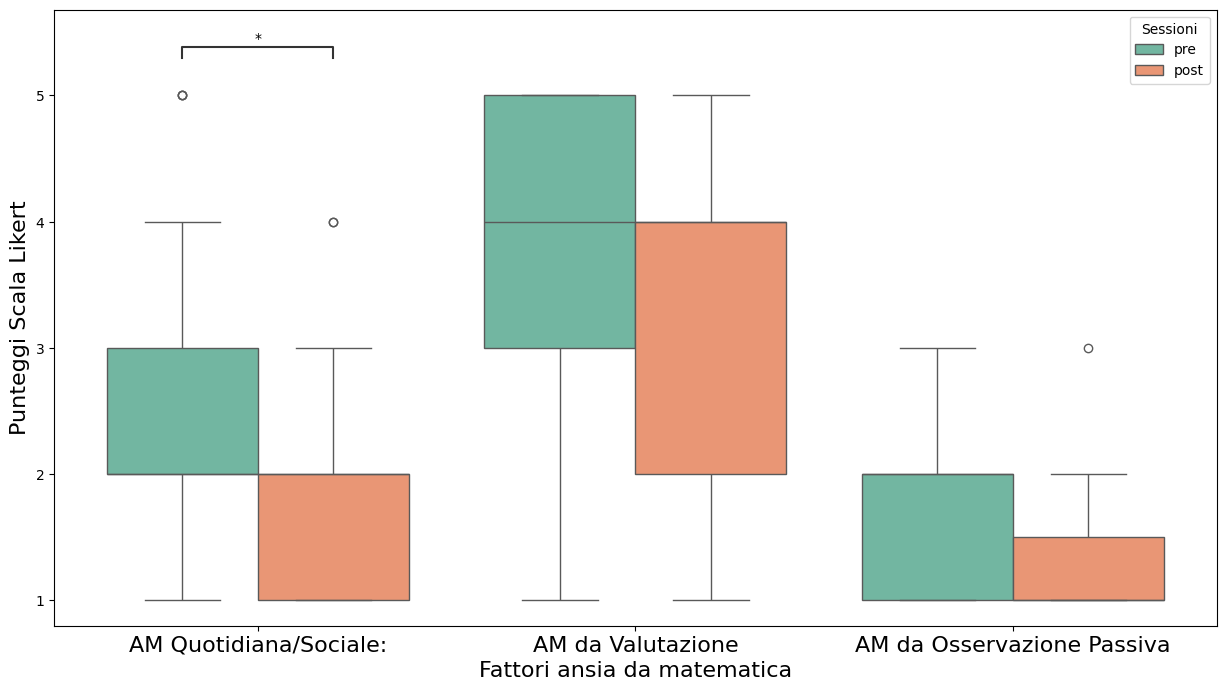

In [14]:
plt.figure(figsize=(15,8))
ax = sns.boxplot(
    data=mas_factors_long_df,
    x="factor",
    y="score",
    hue="session",
    palette="Set2"
)

pvalues_annotations(ax, df = mas_factors_long_df, var1 = 'session', var2 = 'factor')

ax.set_xticks(range(3))
ax.set_xticklabels(
    labels=["AM Quotidiana/Sociale:", "AM da Valutazione", "AM da Osservazione Passiva"],
    fontsize=16
)

plt.xlabel('Fattori ansia da matematica', fontsize=16)

plt.yticks(range(1, 6))
plt.ylabel('Punteggi Scala Likert', fontsize=16)

plt.legend(title='Sessioni')

plt.savefig(f'{out_folder}analysis/stem_group/mas_it_boxplot.png')

## Congnitive Flexibility Scale

In [15]:
questionnaires_2025 = pd.read_csv(f'{out_folder}formatting/all_students_2025/all_questionnaires_2025.csv')

# selazionare solo i partecipanti del gruppo STEM
stem_group_questionnaires = questionnaires_2025[questionnaires_2025['participant_id'].str.startswith('fisica_stem')].reset_index(drop=True)

In [16]:
cfs_questionnaire = item_reversion_sum(stem_group_questionnaires, 'cfs',1, 13, [2,3,5,10])

cfs_questionnaire["participant_base"] = cfs_questionnaire["participant_id"].str.rsplit("_", n=1).str[0]

cfs_mean = cfs_questionnaire.groupby("participant_base")["cfs_total"].mean().reset_index(drop=True)

print(cfs_mean.to_latex(float_format='%.2f'))

print(cfs_mean.describe().to_frame().T.to_latex(float_format='%.2f'))

\begin{tabular}{lr}
\toprule
 & cfs_total \\
\midrule
0 & 38.00 \\
1 & 52.00 \\
2 & 55.00 \\
3 & 42.00 \\
4 & 38.00 \\
\bottomrule
\end{tabular}

\begin{tabular}{lrrrrrrrr}
\toprule
 & count & mean & std & min & 25% & 50% & 75% & max \\
\midrule
cfs_total & 5.00 & 45.00 & 8.00 & 38.00 & 38.00 & 42.00 & 52.00 & 55.00 \\
\bottomrule
\end{tabular}



## State Trait Anxiety Inventory

In [17]:
state_anxiety_questionnaire = item_reversion_sum(stem_group_questionnaires, 'state_anxiety', 1, 19, [1, 2, 5, 8, 11, 15, 16])

In [18]:
mas_it_data = mas_factors_list_df.copy()
mas_it_data.drop(columns=['session'], inplace=True)

for col in mas_it_data.columns:
    mas_it_data[col] = mas_it_data[col].apply(lambda x: sum(x)/len(x))

mas_it_data.insert(0, 'participant_id', stem_group_mas_it['participant_id'].values)

In [19]:
df_merged = pd.merge(mas_it_data,state_anxiety_questionnaire, on='participant_id')
numeric_cols = df_merged.columns.drop('participant_id')
corr_matrix = df_merged[numeric_cols].corr()

# print(corr_matrix['state_anxiety_total'])

for col in df_merged.columns.drop(['participant_id', 'state_anxiety_total']):
    r, p = pearsonr(df_merged[col], df_merged['state_anxiety_total'])
    print(f"{col}: r = {r:.2f}, p = {p:.3f}")

mas_it_factor_1: r = 0.13, p = 0.767
mas_it_factor_2: r = -0.02, p = 0.955
mas_it_factor_3: r = 0.59, p = 0.126


## Big Five Inventory - 10

In [20]:
big_5_questionnaire = big_5(stem_group_questionnaires)

stats = []
for col in big_5_questionnaire.columns:
    if col != 'participant_id':
       stats.append(big_5_questionnaire[col].describe().drop('count'))

stats_df = pd.DataFrame(stats)

print(stats_df.to_latex(float_format='%.2f'))

\begin{tabular}{lrrrrrrr}
\toprule
 & mean & std & min & 25% & 50% & 75% & max \\
\midrule
extraversion & 3.25 & 0.93 & 2.00 & 2.75 & 3.25 & 4.00 & 4.50 \\
agreeableness & 2.50 & 0.76 & 1.50 & 1.88 & 2.75 & 3.00 & 3.50 \\
conscientiousness & 3.56 & 0.78 & 2.50 & 3.00 & 3.50 & 4.12 & 4.50 \\
neuroticism & 3.12 & 0.35 & 2.50 & 3.00 & 3.00 & 3.50 & 3.50 \\
openness & 4.69 & 0.37 & 4.00 & 4.50 & 4.75 & 5.00 & 5.00 \\
\bottomrule
\end{tabular}

